<a href="https://colab.research.google.com/github/elenamaggiore/Thesis_Elena_Maggiore/blob/dataset-branch/Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **DATASETS NOTEBOOK:** EXPLAINS THE PARTITION OF THE ORIGINAL **PANDORA** DATASET AND PERFORMS A DESCRIPTIVE ANALYSIS.

Libraries (_cudf_ is used instead of _pandas_ due to the dimension of the datasets, which requires to be loaded to GPU):

In [ ]:
import cudf as pd
from google.colab import drive
import json
from __future__ import annotations
import ast
import hashlib
import json
import re
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import gc
import os

Mounting Google Drive and loading dataset *author_profiles.csv* to GPU:

In [ ]:
drive.mount('/content/drive')

author_profiles_path = '/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/author_profiles.csv'

try:
    df_authors = pd.read_csv(author_profiles_path)
    print('\nauthor_profiles.csv loaded successfully to GPU.')
    display(df_authors.head(1))
except FileNotFoundError:
    print(f"Error: '{author_profiles_path}' not found. Please ensure the file is in your Google Drive and you have correctly mounted it.")
except Exception as e:
    print(f"An error occurred while loading '{author_profiles_path}': {e}.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

author_profiles.csv loaded successfully to GPU.


,author,mbti,introverted,intuitive,thinking,perceiving,gender,age,enneagram,country,...,enneagram_wing,is_native_english_country,predicted_test,test_name,test_scale,16pers_ta,test_result_type,is_female,is_female_pred,is_female_proba
0,-Afrodisiac-,intp,1.0,1.0,1.0,1.0,m,19.0,None,None,...,<NA>,<NA>,<NA>,None,None,None,None,0.0,1,0.531728


## DATASET SPLIT: Big Five, MBTI, and final dataset

The *author_profiles** dataset is split into three other datasets:
* *big_five_dataset*, which contains the authors for which the Big Five labels are defined, but not the MBTI ones.
* *mbti_dataset*, which contains the authors for which the MBTI labels are defined, but not the Big Five ones.
* *final_dataset*, which containes rows that have both Big Five and MBTI labels defined. This dataset will be used as **test set** for this thesis.

The columns that represent Big Five labels are _"agreeableness", "openness", "conscientiousness", "extraversion", "neuroticism"_, while the columns that represent MBTI labels are _"mbti", "introverted", "intuitive", "thinking", "perceiving"_.

In [ ]:
mbti_columns = ["mbti", "introverted", "intuitive", "thinking", "perceiving"]
big_five_columns = ["agreeableness", "openness", "conscientiousness", "extraversion", "neuroticism"]
all_columns = mbti_columns + big_five_columns

# Final dataset
final_dataset = df_authors.dropna(subset=all_columns)
print(f"Shape of 'final_dataset': {final_dataset.shape}")
print("Head of 'final_dataset':")
display(final_dataset.head(1))

# MBTI dataset
mbti_dataset = df_authors.dropna(subset=mbti_columns)
mbti_dataset = mbti_dataset[~mbti_dataset['author'].isin(final_dataset['author'])]
print(f"Shape of 'mbti_dataset': {mbti_dataset.shape}")
print("Head of 'mbti_dataset':")
display(mbti_dataset.head(1))

# Big Five dataset
big_five_dataset = df_authors.dropna(subset=big_five_columns)
big_five_dataset = big_five_dataset[~big_five_dataset['author'].isin(final_dataset['author'])]
print(f"Shape of 'big_five_dataset': {big_five_dataset.shape}")
print("Head of 'big_five_dataset':")
display(big_five_dataset.head(1))

Shape of 'final_dataset': (377, 38)
Head of 'final_dataset':


,author,mbti,introverted,intuitive,thinking,perceiving,gender,age,enneagram,country,...,enneagram_wing,is_native_english_country,predicted_test,test_name,test_scale,16pers_ta,test_result_type,is_female,is_female_pred,is_female_proba
7,-BlitzN9ne,entp,0.0,1.0,1.0,1.0,m,21.0,3w4,None,...,4.0,<NA>,1.0,qualtrics,percentiles,None,description,0.0,0,0.027725


Shape of 'mbti_dataset': (8690, 38)
Head of 'mbti_dataset':


,author,mbti,introverted,intuitive,thinking,perceiving,gender,age,enneagram,country,...,enneagram_wing,is_native_english_country,predicted_test,test_name,test_scale,16pers_ta,test_result_type,is_female,is_female_pred,is_female_proba
0,-Afrodisiac-,intp,1.0,1.0,1.0,1.0,m,19.0,None,None,...,<NA>,<NA>,<NA>,None,None,None,None,0.0,1,0.531728


Shape of 'big_five_dataset': (1191, 38)
Head of 'big_five_dataset':


,author,mbti,introverted,intuitive,thinking,perceiving,gender,age,enneagram,country,...,enneagram_wing,is_native_english_country,predicted_test,test_name,test_scale,16pers_ta,test_result_type,is_female,is_female_pred,is_female_proba
1,-Areopagan-,None,<NA>,<NA>,<NA>,<NA>,m,<NA>,None,None,...,<NA>,<NA>,0.0,understand myself,percentiles,None,percentiles,0.0,0,0.162758


The Big Five and MBTI datasets are cleaned from columns that measure the other technique, and it's performed a first descriptive analysis through the python function **describe**.

In [ ]:
#Cleaning
mbti_columns = ["mbti", "introverted", "intuitive", "thinking", "perceiving"]
big_five_columns = ["agreeableness", "openness", "conscientiousness", "extraversion", "neuroticism"]
#mbti_dataset = mbti_dataset.drop(columns=big_five_columns)
#big_five_dataset = big_five_dataset.drop(columns=mbti_columns)

#Descriptive analysis
print("=== DESCRIPTIVE ANALYSIS MBTI DATASET ===")
display(mbti_dataset.describe(include='all'))
print("\n=== DESCRIPTIVE ANALYSIS BIG FIVE DATASET ===")
display(big_five_dataset.describe())
print("\n=== DESCRIPTIVE ANALYSIS FINAL DATASET ===")
display(final_dataset.describe(include='all'))

#Counting rows: was the partitioning successful?
len_mbti = len(mbti_dataset)
len_b5 = len(big_five_dataset)
len_final = len(final_dataset)
total_split = len_mbti + len_b5 + len_final

cond_mbti = df_authors[mbti_columns].notna().all(axis=1)
cond_b5 = df_authors[big_five_columns].notna().all(axis=1)
len_initial_dataset = len(df_authors[cond_mbti | cond_b5])

print(f"Authors in 'mbti_dataset': {len_mbti}")
print(f"Authors in 'big_five_dataset': {len_b5}")
print(f"Authors in 'final_dataset': {len_final}")
print(f"Sum of the authors in the three datasets: {total_split}")
print(f"Valid authors in the starting dataset: {len_initial_dataset}")
print(f"Verifica: {total_split} == {len_initial_dataset} -> {total_split == len_initial_dataset}")

##COMMENTS INCLUSION: this step will consider dataset *all_comments_since_2015* and add them to each dataset.

Dataset *all_comments_since_2015* contains, for each author mentioned in the original *authors_dataset*, all published comments on Reddit since 2015. Dataset *all_comments_since_2015* has already been partitioned by methodology using **DB SQLite** due to its enormous number of rows.

Comments are stored in column *comments* in JSON format, while the corresponding subreddits are stored in column *subreddits* in the same format.

In [ ]:
import json
import cudf as pd

comments_big_five_path = '/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/comments_big_five.csv'
output_big_five_path = '/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/big_five_dataset_commented.csv'

try:
    # 1. Load comments_big_five.csv
    print("Loading comments_big_five.csv...")
    df_comments_b5 = pd.read_csv(comments_big_five_path)
    print(f"Loaded successfully. Shape: {df_comments_b5.shape}")

    # 2. Handle missing values and ensure strings
    df_comments_b5['body'] = df_comments_b5['body'].fillna('').astype(str)
    df_comments_b5['subreddit'] = df_comments_b5['subreddit'].fillna('').astype(str)

    # 3. Aggregate to lists (converting to pandas if it is a cuDF DataFrame)
    print("Aggregating comments and subreddits per author...")
    if hasattr(df_comments_b5, 'to_pandas'):
        pdf_comments_b5 = df_comments_b5[['author', 'body', 'subreddit']].to_pandas()
    else:
        pdf_comments_b5 = df_comments_b5[['author', 'body', 'subreddit']]

    agg_df_b5 = pdf_comments_b5.groupby('author').agg({
        'body': list,
        'subreddit': list
    }).reset_index()

    # 4. Serialize lists to JSON strings
    print("Converting lists to JSON format...")
    agg_df_b5['comments'] = agg_df_b5['body'].apply(json.dumps)
    agg_df_b5['subreddits'] = agg_df_b5['subreddit'].apply(json.dumps)

    # 5. Merge back with big_five_dataset
    print("Merging with big_five_dataset...")
    b5_agg_df = agg_df_b5[['author', 'comments', 'subreddits']]

    if hasattr(big_five_dataset, 'to_pandas'):
        import cudf
        gpu_agg_b5 = cudf.from_pandas(b5_agg_df)
    else:
        gpu_agg_b5 = b5_agg_df

    big_five_dataset_commented = big_five_dataset.merge(gpu_agg_b5, on='author', how='left')

    # Fill missing values with empty JSON arrays
    big_five_dataset_commented['comments'] = big_five_dataset_commented['comments'].fillna('[]')
    big_five_dataset_commented['subreddits'] = big_five_dataset_commented['subreddits'].fillna('[]')

    # 6. Save the final commented dataset to Drive
    print(f"Saving dataset to: {output_big_five_path}...")
    big_five_dataset_commented.to_csv(output_big_five_path, index=False)

    print("All operations completed successfully!")
    display(big_five_dataset_commented[['author', 'comments', 'subreddits']].head())

except FileNotFoundError:
    print(f"Error: '{comments_big_five_path}' not found.")
except Exception as e:
    print(f"An error occurred: {e}")

In [ ]:
import json
import cudf as pd

comments_final_path = '/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/comments_final.csv'
output_final_path = '/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/final_dataset_commented.csv'

try:
    print("Loading comments_final.csv...")
    df_comments_final = pd.read_csv(comments_final_path)
    print(f"Loaded successfully. Shape: {df_comments_final.shape}")

    df_comments_final['body'] = df_comments_final['body'].fillna('').astype(str)
    df_comments_final['subreddit'] = df_comments_final['subreddit'].fillna('').astype(str)

    print("Aggregating comments and subreddits...")
    if hasattr(df_comments_final, 'to_pandas'):
        pdf_comments_final = df_comments_final[['author', 'body', 'subreddit']].to_pandas()
    else:
        pdf_comments_final = df_comments_final[['author', 'body', 'subreddit']]

    agg_df_final = pdf_comments_final.groupby('author').agg({
        'body': list,
        'subreddit': list
    }).reset_index()

    print("Converting lists to JSON format...")
    agg_df_final['comments'] = agg_df_final['body'].apply(json.dumps)
    agg_df_final['subreddits'] = agg_df_final['subreddit'].apply(json.dumps)

    print("Merging with final_dataset...")
    final_agg_df = agg_df_final[['author', 'comments', 'subreddits']]

    if hasattr(final_dataset, 'to_pandas'):
        import cudf
        gpu_agg_final = cudf.from_pandas(final_agg_df)
    else:
        gpu_agg_final = final_agg_df

    final_dataset_commented = final_dataset.merge(gpu_agg_final, on='author', how='left')

    final_dataset_commented['comments'] = final_dataset_commented['comments'].fillna('[]')
    final_dataset_commented['subreddits'] = final_dataset_commented['subreddits'].fillna('[]')

    print(f"Saving dataset to: {output_final_path}...")
    final_dataset_commented.to_csv(output_final_path, index=False)

    print("All operations completed successfully!")
    display(final_dataset_commented[['author', 'comments', 'subreddits']].head())


except FileNotFoundError:
    print(f"Error: '{comments_big_five_path}' not found.")
except Exception as e:
    print(f"An error occurred: {e}")

In [ ]:
# ============================================================
# CONFIGURATION
# ============================================================
import pandas as pd

comments_mbti_path = '/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/comments_mbti.csv'
output_dir = '/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/mbti_chunks'

# Number of rows of comments_mbti.csv to read at a time
CHUNK_SIZE = 10000000

# Create output folder
os.makedirs(output_dir, exist_ok=True)

print("Loading mbti_dataset...")

# We assume that mbti_dataset is already loaded in memory.
# If it is a cuDF DataFrame, convert it to pandas ONLY for the authors.
if hasattr(mbti_dataset, 'to_pandas'):
    mbti_pdf = mbti_dataset.to_pandas()
else:
    mbti_pdf = mbti_dataset.copy()

# We only need the authors
authors = set(mbti_pdf['author'].dropna().astype(str))

print(f"Authors in MBTI dataset: {len(authors):,}")

# ============================================================
# CHUNK PROCESSING
# ============================================================

chunk_number = 1

# Temporary dictionary:
# author -> {
#     'comments': [...],
#     'subreddits': [...]
# }
#
# IMPORTANT:
# this dictionary only contains the current chunk.
author_data = {}

print("\nStarting processing of comments_mbti.csv...\n")

for chunk in pd.read_csv(
    comments_mbti_path,
    chunksize=CHUNK_SIZE,
    usecols=['author', 'body', 'subreddit'],
    dtype={
        'author': 'string',
        'body': 'string',
        'subreddit': 'string'
    }
):

    print(f"Processing chunk {chunk_number}...")
    print(f"Rows read: {len(chunk):,}")

    # Data cleaning
    chunk['author'] = chunk['author'].fillna('').astype(str)
    chunk['body'] = chunk['body'].fillna('').astype(str)
    chunk['subreddit'] = chunk['subreddit'].fillna('').astype(str)

    # Keep only authors that are present in mbti_dataset
    chunk = chunk[chunk['author'].isin(authors)]

    print(f"Rows belonging to MBTI authors: {len(chunk):,}")

    # --------------------------------------------------------
    # Aggregate ONLY the current chunk
    # --------------------------------------------------------

    for author, group in chunk.groupby('author'):

        comments = group['body'].tolist()
        subreddits = group['subreddit'].tolist()

        if author not in author_data:
            author_data[author] = {
                'comments': [],
                'subreddits': []
            }

        author_data[author]['comments'].extend(comments)
        author_data[author]['subreddits'].extend(subreddits)

    # --------------------------------------------------------
    # Save the current chunk
    # --------------------------------------------------------

    output_path = os.path.join(
        output_dir,
        f'mbti_dataset_commented_{chunk_number}.csv'
    )

    # Create a DataFrame ONLY with the authors present in this chunk
    chunk_result = pd.DataFrame([
        {
            'author': author,
            'comments': json.dumps(data['comments'], ensure_ascii=False),
            'subreddits': json.dumps(data['subreddits'], ensure_ascii=False)
        }
        for author, data in author_data.items()
    ])

    # --------------------------------------------------------
    # Merge with mbti_dataset
    # --------------------------------------------------------

    result = mbti_pdf.merge(
        chunk_result,
        on='author',
        how='inner'
    )

    # Save the result
    result.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")
    print(f"Authors in file: {len(result):,}")

    # --------------------------------------------------------
    # FREE MEMORY
    # --------------------------------------------------------

    del chunk
    del chunk_result
    del result
    del author_data

    author_data = {}

    gc.collect()

    print("Memory freed.\n")

    chunk_number += 1


print("==========================================")
print("PROCESSING COMPLETED")
print("==========================================")
print(f"Files created: {chunk_number - 1}")
print(f"Output folder: {output_dir}")

Loading mbti_dataset...
Authors in MBTI dataset: 8,690

Starting processing of comments_mbti.csv...

Processing chunk 1...
Rows read: 10,000,000
Rows belonging to MBTI authors: 10,000,000
Saved: /content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/mbti_chunks/mbti_dataset_commented_1.csv
Authors in file: 8,690
Memory freed.

Processing chunk 2...
Rows read: 4,510,601
Rows belonging to MBTI authors: 4,510,601
Saved: /content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/mbti_chunks/mbti_dataset_commented_2.csv
Authors in file: 7,022
Memory freed.

PROCESSING COMPLETED
Files created: 2
Output folder: /content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/mbti_chunks


## DESCRIPTIVE ANALYSIS: this section will perform a descriptive analysis of all commented datasets.


The **CONFIG** cell performs the following steps:

1) Imports required libraries, going back to _pandas_.
2) Sets paths to datasets and to the folders in which outputs will be saved.
3) Saves parameters, such as flag and list columns, exclusion parameters such as age range and minimum number of comments, and settings like **anonymisation**, **saving images and tables**, and so on.
4) Sets parameters such as the MBTI Types names, the name of MBTI and Enneagram subreddits, and other possible causes of data leakage.

In [ ]:
import ast
import gc
import hashlib
import json
import random
import re
from collections import Counter, defaultdict
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = Path("/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets")
DATASETS = {
    "big_five": BASE / "big_five_dataset_commented.csv",
    "mbti_1": BASE / "mbti_dataset_commented_1.csv",
    "mbti_2": BASE / "mbti_dataset_commented_2.csv",
    "final": BASE / "final_dataset_commented.csv",
}
OUT_DIR = BASE / "Descriptive analysis output"

TRAIT_COLS = ["openness", "conscientiousness", "extraversion", "agreeableness", "neuroticism"]
TRAIT_OVERRIDE = {}
FLAG_COLS = {"introverted": ("I", "E"), "intuitive": ("N", "S"),
             "thinking": ("T", "F"), "perceiving": ("P", "J")}
LIST_COLS = ["comments", "subreddits"]
NA_STRINGS = {"", "none", "null", "nan", "<na>", "n/a", "na"}
AGE_RANGE = (10, 90)
MIN_COMMENTS = 1
ANONYMIZE = True
TOP_N = 30
MIN_GROUP_N = 30
MAX_SAMPLE_COMMENTS = 200_000
SHOW_FIGURES = True
EXPORT_WITH_TEXT = False
KEEP = {"test_name", "test_scale"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
FIG_DIR = TAB_DIR = OUT_DIR
_FIG_N = _TAB_N = 0

MBTI_GRID = [["ISTJ", "ISFJ", "INFJ", "INTJ"], ["ISTP", "ISFP", "INFP", "INTP"],
             ["ESTP", "ESFP", "ENFP", "ENTP"], ["ESTJ", "ESFJ", "ENFJ", "ENTJ"]]
MBTI_TYPES = [t for row in MBTI_GRID for t in row]
PERSONALITY_SUBS = {t.lower() for t in MBTI_TYPES} | {"mbti", "enneagram"}

This **UTILITY FUNCTIONS** cell defines the following functions:

* *set_output*: sets the output folders of a dataset (_figures_ and _tables_ inside _OUT_DIR/<dataset name>_), creates them if they do not exist and resets the figure and table counters.
* *savefig*: saves the current figure as a numbered PNG (300 dpi), displays it if _SHOW_FIGURES_ is _True_ and closes it.
* *savetab*: saves a DataFrame as a numbered CSV file in the tables folder.
* *load*: reads a dataset from a _.csv_, _.parquet_, _.json_ or _.jsonl_ file, depending on its extension.
* *parse_list*: converts the text stored in the _"comments"_ and _"subreddits"_ columns into a Python list. If the value is missing or cannot be read, it returns an empty list.
* *gini*: computes the Gini index of a variable (0 = perfectly even, 1 = fully concentrated). It is used to measure how unequally the comments are distributed among the authors.
* *hist_plot*: draws the histogram of a single variable, with mean and median lines. It can use a logarithmic scale or cut the values above a given quantile.
* *hist_grid*: draws a grid of histograms, one for each of the given columns.
* *bar_plot*: draws a bar chart (vertical or horizontal) of a series of counts, with the values written on the bars.
* *heatmap*: draws a matrix as a heatmap with a color bar. The values are written inside the cells when the matrix is small enough.
* *text_pass*: reads the _"comments"_ and _"subreddits"_ columns only once and, for each author, computes the number of comments, the number of words and characters, the number of distinct subreddits and the number of comments posted in personality subreddits (such as r/intj). At the same time it builds the global counters used later: comments and authors per subreddit, and subreddit counts per MBTI type. It also draws a random sample of comments (at most 20 per author, up to *MAX_SAMPLE_COMMENTS* in total) for the comment-level analyses. Subreddit names are converted to lower case, and authors with fewer than *MIN_COMMENTS* comments are left out of the counters and of the sample.

All the plotting functions end by calling *savefig*, so every figure is saved and displayed in the same way.

In [ ]:
def set_output(name: str) -> None:
    global FIG_DIR, TAB_DIR, _FIG_N, _TAB_N
    FIG_DIR, TAB_DIR = OUT_DIR / name / "figures", OUT_DIR / name / "tables"
    for d in (FIG_DIR, TAB_DIR):
        d.mkdir(parents=True, exist_ok=True)
    _FIG_N = _TAB_N = 0


def savefig(name: str) -> None:
    """Saves the graph (300 dpi), prints it, closes it."""
    global _FIG_N
    _FIG_N += 1
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"fig{_FIG_N:02d}_{name}.png", dpi=300, bbox_inches="tight")
    if SHOW_FIGURES:
        plt.show()
    plt.close()


def savetab(df: pd.DataFrame, name: str, index: bool = True) -> None:
    global _TAB_N
    _TAB_N += 1
    df.to_csv(TAB_DIR / f"tab{_TAB_N:02d}_{name}.csv", index=index, encoding="utf-8-sig")


def load(path: Path) -> pd.DataFrame:
    ext = path.suffix.lower()
    if ext == ".csv":
        return pd.read_csv(path, low_memory=False)
    if ext == ".parquet":
        return pd.read_parquet(path)
    if ext in {".json", ".jsonl"}:
        return pd.read_json(path, lines=(ext == ".jsonl"))
    raise ValueError(f"Unsupported format: {ext}")


def parse_list(x) -> list:
    if isinstance(x, (list, np.ndarray)):
        return list(x)
    if x is None or x is pd.NA or (isinstance(x, float) and np.isnan(x)):
        return []
    try:
        return json.loads(x)
    except (ValueError, TypeError):
        try:
            return ast.literal_eval(x)
        except (ValueError, SyntaxError):
            return []


def gini(x) -> float:
    x = np.sort(np.asarray(x, dtype=float))
    if len(x) == 0 or x.sum() == 0:
        return np.nan
    cum = np.cumsum(x)
    return (len(x) + 1 - 2 * cum.sum() / cum[-1]) / len(x)


def hist_plot(s, name, xlabel, title=None, bins=30, log=False, clip_q=None, ylabel="N. autori"):
    s = pd.Series(s).dropna()
    if log:
        s = s[s > 0]
    if s.empty:
        return
    if clip_q:
        s = s[s <= s.quantile(clip_q)]
    fig, ax = plt.subplots(figsize=(6, 4))
    if log and s.max() > s.min():
        bins = np.logspace(np.log10(s.min()), np.log10(s.max() * 1.0001), 40)
        ax.set_xscale("log")
    ax.hist(s, bins=bins, edgecolor="white")
    ax.axvline(s.mean(), ls="--", c="k", lw=1, label=f"mean {s.mean():,.1f}")
    ax.axvline(s.median(), ls=":", c="r", lw=1.5, label=f"median {s.median():,.1f}")
    ax.legend(frameon=False)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    savefig(name)


def hist_grid(df, cols, name, ncol=3, xlabel="Valore"):
    cols = [c for c in cols if df[c].notna().any()]
    if not cols:
        return
    ncol = min(ncol, len(cols))
    nrow = int(np.ceil(len(cols) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.2 * nrow), squeeze=False)
    for ax, c in zip(axes.ravel(), cols):
        s = df[c].dropna()
        ax.hist(s, bins=30, edgecolor="white")
        ax.axvline(s.mean(), ls="--", c="k", lw=1)
        ax.axvline(s.median(), ls=":", c="r", lw=1.5)
        ax.set(title=c, xlabel=xlabel, ylabel="Number of authors")
    for ax in axes.ravel()[len(cols):]:
        ax.axis("off")
    savefig(name)


def bar_plot(counts, name, xlabel="", ylabel="Number of authors", horizontal=False, title=None):
    counts = pd.Series(counts).dropna()
    if counts.empty:
        return
    n = len(counts)
    labels = [f"{v:,.0f}" for v in counts.values]
    if horizontal:
        fig, ax = plt.subplots(figsize=(7, max(3, 0.3 * n + 1)))
        bars = ax.barh(counts.index.astype(str), counts.values, edgecolor="white")
        ax.invert_yaxis()
        ax.set(xlabel=ylabel, ylabel=xlabel, title=title)
    else:
        fig, ax = plt.subplots(figsize=(max(5, 0.5 * n + 2), 4))
        bars = ax.bar(counts.index.astype(str), counts.values, edgecolor="white")
        ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    if n <= 40:
        ax.bar_label(bars, labels=labels, padding=2, fontsize=7)
    savefig(name)


def heatmap(mat, name, title="", fmt="{:.2f}", cmap="viridis", vmin=None, vmax=None,
            cbar_label="", figsize=None):
    mat = mat.astype(float)
    fig, ax = plt.subplots(figsize=figsize or (max(5, 0.7 * mat.shape[1] + 3),
                                               max(4, 0.4 * mat.shape[0] + 2)))
    im = ax.imshow(mat.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(mat.shape[1]), [str(c) for c in mat.columns], rotation=45, ha="right")
    ax.set_yticks(range(mat.shape[0]), [str(i) for i in mat.index])
    if mat.size <= 400:
        for i in range(mat.shape[0]):
            for j in range(mat.shape[1]):
                v = mat.iloc[i, j]
                if np.isnan(v):
                    continue
                r, g, b, _ = im.cmap(im.norm(v))
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8,
                        color="white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "black")
    fig.colorbar(im, ax=ax, label=cbar_label)
    ax.set_title(title)
    savefig(name)


def text_pass(df):
    """Global metrics, by author."""
    types = df["mbti"].tolist() if "mbti" in df.columns else [None] * len(df)
    keys = ["n_comments", "n_subreddit_entries", "n_words_total", "n_chars_total",
            "n_unique_subreddits", "n_comments_personality"]
    rec = {k: [] for k in keys}
    c_posts, c_auth, by_type = Counter(), Counter(), defaultdict(Counter)
    sample, rnd = [], random.Random(42)

    for com_raw, sub_raw, t in zip(df["comments"], df["subreddits"], types):
        coms = parse_list(com_raw)
        subs = [str(s).lower() for s in parse_list(sub_raw)]
        n = len(coms)
        rec["n_comments"].append(n)
        rec["n_subreddit_entries"].append(len(subs))
        rec["n_words_total"].append(sum(len(str(c).split()) for c in coms))
        rec["n_chars_total"].append(sum(len(str(c)) for c in coms))
        rec["n_unique_subreddits"].append(len(set(subs)))
        rec["n_comments_personality"].append(sum(1 for s in subs if s in PERSONALITY_SUBS))
        if n >= MIN_COMMENTS:
            c_posts.update(subs)
            c_auth.update(set(subs))
            if t is not None and pd.notna(t):
                by_type[t].update(subs)
            if n:
                sample.extend(str(coms[i]) for i in rnd.sample(range(n), min(n, 20)))
                if len(sample) > 2 * MAX_SAMPLE_COMMENTS:
                    sample = rnd.sample(sample, MAX_SAMPLE_COMMENTS)
    for k, v in rec.items():
        df[k] = v
    if len(sample) > MAX_SAMPLE_COMMENTS:
        sample = rnd.sample(sample, MAX_SAMPLE_COMMENTS)
    return df, c_posts, c_auth, by_type, sample

In [ ]:
def run_analysis(name: str, path: Path):
    set_output(name)
    print("=" * 70, f"\nDATASET: {name}\n{path}\n" + "=" * 70)
    S = {"dataset": name}

    # Loading dataset
    df = load(path)
    S["n_rows_raw"], S["n_cols_raw"] = len(df), df.shape[1]
    print(f"Righe: {len(df):,} | Colonne: {df.shape[1]}")

    # Cleaning columns
    df.columns = [re.sub(r"[^0-9a-zA-Z]+", "_", str(c).strip()).strip("_").lower() for c in df.columns]

    for c in df.select_dtypes(include=["object", "string"]).columns:
        if c in LIST_COLS:
            continue
        s = df[c].astype("string").str.strip()
        df[c] = s.mask(s.str.lower().isin(NA_STRINGS))

    trait_cols = [c for c in (TRAIT_OVERRIDE.get(name) or TRAIT_COLS) if c in df.columns]
    flag_cols = [c for c in FLAG_COLS if c in df.columns]
    for c in trait_cols + flag_cols + ["age", "is_female", "is_female_pred", "is_female_proba", "predicted_test"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")

    for c in flag_cols:
        bad = df[c].notna() & ~df[c].isin([0, 1])
        if bad.any():
            print(f"Flag {c}: {bad.sum()} is not binary -> NaN")
            df.loc[bad, c] = np.nan

    if "age" in df.columns:
        bad = (~df["age"].between(*AGE_RANGE)) & df["age"].notna()
        print(f"Out of age range {AGE_RANGE}: {bad.sum()} -> NaN")
        df.loc[bad, "age"] = np.nan

    audit = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "n_unique": df.apply(lambda s: np.nan if s.name in LIST_COLS else s.nunique(dropna=True)),
        "example": df.apply(lambda s: str(s.dropna().iloc[0])[:40] if s.notna().any() else ""),
    })
    audit["advice"] = np.select([audit["n_unique"] <= 1, audit["pct_missing"] > 90],
                                      ["DROP (empty/constant)", "consider dropping (more than 90% missing)"], default="")
    savetab(audit, "audit_columns")
    print(audit.sort_values("pct_missing", ascending=False).to_string())

    miss = audit["pct_missing"].sort_values()
    fig, ax = plt.subplots(figsize=(7, max(3, 0.28 * len(miss) + 1)))
    ax.barh(miss.index, miss.values, edgecolor="white")
    ax.set(xlabel="Percentage of missing values", xlim=(0, 100), title="Missing values per column")
    savefig("missing values")

    to_drop = [c for c in audit.index[audit["n_unique"] <= 1] if c not in KEEP]
    df = df.drop(columns=to_drop)
    S["n_cols_clean"] = df.shape[1]
    print("Dropped columns:", to_drop)
    trait_cols = [c for c in trait_cols if c in df.columns]
    flag_cols = [c for c in flag_cols if c in df.columns]

    known = set(trait_cols) | set(flag_cols) | {"age", "is_female", "is_female_pred", "is_female_proba",
                                                "predicted_test", "enneagram"}
    extra_num = [c for c in df.select_dtypes("number").columns if c not in known and df[c].notna().sum() >= 20]
    print("Traits:", trait_cols, "| MBTI flag:", flag_cols)
    print("Other numerical columns:", extra_num)

    if "author" in df.columns:
        print(f"Duplicates: {df['author'].duplicated().sum()}")
        df = df.drop_duplicates(subset="author", keep="first")
        if ANONYMIZE:
            df["author_id"] = df["author"].astype(str).map(lambda a: hashlib.sha256(a.encode()).hexdigest()[:10])
            df = df.drop(columns="author")
    key = "author_id" if "author_id" in df.columns else ("author" if "author" in df.columns else None)


    if {"is_female", "is_female_pred"} <= set(df.columns):
        both = df.dropna(subset=["is_female", "is_female_pred"])
        if len(both):
            print(f"Declared gender vs predicted gender: {(both['is_female'] == both['is_female_pred']).mean():.1%} (n={len(both)})")
        df["is_female_final"] = df["is_female"].fillna(df["is_female_pred"])
        df["gender_source"] = np.select([df["is_female"].notna(), df["is_female_pred"].notna()],
                                        ["declared", "predicted"], default="missing")
    elif "is_female" in df.columns:
        df["is_female_final"] = df["is_female"]
    has_gender = "is_female_final" in df.columns and df["is_female_final"].notna().any()


    consistency = None
    if "mbti" in df.columns:
        df["mbti"] = df["mbti"].astype("string").str.upper()
        valid = df["mbti"].str.fullmatch(r"[EI][NS][TF][JP]", na=False)
        print(f"Missing or invalid MBTI: {(~valid).sum()}")
        df.loc[~valid, "mbti"] = pd.NA
    if len(flag_cols) == 4:
        complete = df[flag_cols].notna().all(axis=1)
        l = [np.where(df[c] == 1, FLAG_COLS[c][0], FLAG_COLS[c][1]) for c in flag_cols]
        derived = pd.Series(np.char.add(np.char.add(l[0], l[1]), np.char.add(l[2], l[3])),
                            index=df.index).astype("string").where(complete)
        if "mbti" in df.columns:
            both = df["mbti"].notna() & derived.notna()
            if both.any():
                rows = {f"{FLAG_COLS[c][0]}/{FLAG_COLS[c][1]}": (df.loc[both, "mbti"].str[i] == derived[both].str[i]).mean()
                        for i, c in enumerate(flag_cols)}
                rows["full type"] = (df.loc[both, "mbti"] == derived[both]).mean()
                consistency = pd.Series(rows, name="accordance")
                print("Flag coherence by MBTI type:\n", (consistency * 100).round(2).to_string())
            fill = df["mbti"].isna() & derived.notna()
            print(f"MBTI type obtained by flags for {fill.sum()} authors")
            df.loc[fill, "mbti"] = derived[fill]
        else:
            df["mbti"] = derived
    has_mbti = "mbti" in df.columns and df["mbti"].notna().any()

    # ------------------------------------------------------------ 4. TESTI (un solo passaggio)
    has_text = {"comments", "subreddits"} <= set(df.columns)
    c_posts = c_auth = Counter()
    by_type, sample = {}, []
    if has_text:
        df, c_posts, c_auth, by_type, sample = text_pass(df)
        print(f"Authors with more comments than subreddits: {(df['n_comments'] != df['n_subreddit_entries']).sum()}")
        print(f"Authors with less than {MIN_COMMENTS} commens have been removed: {(df['n_comments'] < MIN_COMMENTS).sum()}")
        df["mean_words_per_comment"] = df["n_words_total"] / df["n_comments"].replace(0, np.nan)
        df["share_personality_subs"] = df["n_comments_personality"] / df["n_comments"].replace(0, np.nan)
        df = df[df["n_comments"] >= MIN_COMMENTS].copy()
        if not EXPORT_WITH_TEXT:
            df = df.drop(columns=LIST_COLS)

    S["n_authors"] = len(df)
    S["n_mbti_valid"] = int(df["mbti"].notna().sum()) if "mbti" in df.columns else 0
    S["n_big5_complete"] = int(df[trait_cols].notna().all(axis=1).sum()) if trait_cols else 0
    S["pct_female"] = float(df["is_female_final"].mean() * 100) if has_gender else np.nan
    S["mean_age"] = float(df["age"].mean()) if "age" in df.columns else np.nan


    trait_cols = [c for c in trait_cols if df[c].notna().any()]
    if trait_cols:
        if {"test_name", "test_scale"} <= set(df.columns):
            sc = df.groupby(["test_name", "test_scale"], dropna=False)[trait_cols].agg(["count", "min", "max"])
            savetab(sc, "scala_per_test")
            print(sc.to_string())
        oor = pd.DataFrame({c: {"n_under_0": int((df[c] < 0).sum()), "n_over_100": int((df[c] > 100).sum())}
                            for c in trait_cols}).T
        savetab(oor, "value_out_of_range_0_100")

        desc = df[trait_cols].describe().T
        desc["skew"], desc["kurtosis"] = df[trait_cols].skew(), df[trait_cols].kurtosis()
        desc["pct_missing"] = df[trait_cols].isna().mean() * 100
        savetab(desc.round(3), "describing_traits")
        print(desc.round(2).to_string())

        hist_grid(df, trait_cols, "traits_distribution", xlabel="Percentiles")

        fig, ax = plt.subplots(figsize=(1.5 * len(trait_cols) + 2, 4))
        ax.boxplot([df[c].dropna() for c in trait_cols], showmeans=True)
        ax.set_xticklabels(trait_cols, rotation=30, ha="right")
        ax.set(ylabel="Percentiles", title="Traits boxplot")
        savefig("traits_boxplot")

        if len(trait_cols) > 1:
            corr = df[trait_cols].corr(method="spearman")
            savetab(corr.round(3), "spearman_traits_correlations")
            heatmap(corr, "spearman_traits_correlations", "Spearman_Traits_Correlation", cmap="coolwarm",
                    vmin=-1, vmax=1, cbar_label="ρ", figsize=(max(5, 0.9 * len(corr) + 2),) * 2)
            dd = df[trait_cols].dropna()
            if len(dd) > 5:
                k = len(trait_cols)
                pd.plotting.scatter_matrix(dd.sample(min(2000, len(dd)), random_state=1),
                                           figsize=(2.2 * k + 1, 2.2 * k + 1), alpha=0.25,
                                           diagonal="hist", s=6, hist_kwds={"bins": 25})
                savefig("scatter_matrix_traits")

        if has_gender:
            fig, axes = plt.subplots(1, len(trait_cols), figsize=(2.6 * len(trait_cols) + 1, 4), squeeze=False)
            for ax, c in zip(axes[0], trait_cols):
                g = [df.loc[df["is_female_final"] == v, c].dropna() for v in (0, 1)]
                if all(len(x) > 0 for x in g):
                    ax.boxplot(g, showmeans=True)
                ax.set_xticks([1, 2], ["M", "F"])
                ax.set_title(c)
            savefig("traits_by_gender")

        if "age" in df.columns and df["age"].notna().sum() > 20:
            ag = pd.cut(df["age"], bins=[10, 18, 25, 35, 45, 60, 91],
                        labels=["10-17", "18-24", "25-34", "35-44", "45-59", "60+"], right=False)
            g = df.groupby(ag, observed=True)[trait_cols].agg(["mean", "sem", "count"])
            savetab(g.round(3), "traits_by_age")
            fig, ax = plt.subplots(figsize=(7, 4))
            x = np.arange(len(g))
            for c in trait_cols:
                ax.errorbar(x, g[(c, "mean")], yerr=g[(c, "sem")], marker="o", capsize=3, label=c)
            ax.set_xticks(x, g.index.astype(str))
            ax.set(xlabel="Age", ylabel="Medium percentile (± SE)")
            ax.legend(frameon=False, fontsize=8)
            savefig("traits_by_age")

        if "test_name" in df.columns:
            vc = df["test_name"].value_counts()
            tests = vc[vc >= MIN_GROUP_N].index.tolist()[:4]
            if len(tests) >= 2:
                savetab(df[df["test_name"].isin(tests)].groupby("test_name")[trait_cols].agg(["count", "mean", "std"]).round(2),
                        "traits_by_test")
                fig, axes = plt.subplots(1, len(trait_cols), figsize=(2.8 * len(trait_cols) + 1, 4), squeeze=False)
                for ax, c in zip(axes[0], trait_cols):
                    ax.boxplot([df.loc[df["test_name"] == t, c].dropna() for t in tests], showmeans=True)
                    ax.set_xticks(range(1, len(tests) + 1), tests, rotation=30, ha="right")
                    ax.set_title(c)
                savefig("traits_by_test")

    if extra_num:
        savetab(df[extra_num].describe().T.round(3), "other numerical variables")
        hist_grid(df, extra_num[:12], "other numerical variables")

    # ------------------------------------------------------------ 6. MBTI
    if len(flag_cols) > 0:
        ft = pd.DataFrame({FLAG_COLS[c][0] + "/" + FLAG_COLS[c][1]: {
            "n_valid": int(df[c].notna().sum()), "n_first_pole": int((df[c] == 1).sum()),
            "% first_pole": df[c].mean() * 100} for c in flag_cols}).T
        savetab(ft.round(2), "proportions_flag_mbti")
        if len(flag_cols) > 1:
            heatmap(df[flag_cols].corr(), "phi_dychotomy_correlations", "Dychotomy correlations (φ)",
                    cmap="coolwarm", vmin=-1, vmax=1, cbar_label="φ", figsize=(5.5, 4.5))
    if consistency is not None:
        savetab(consistency.round(4).to_frame(), "flag_type_coherence")
        fig, ax = plt.subplots(figsize=(6, 4))
        bars = ax.bar(consistency.index, consistency.values * 100, edgecolor="white")
        ax.bar_label(bars, labels=[f"{v:.1f}%" for v in consistency.values * 100], padding=2)
        ax.set(ylim=(0, 108), ylabel="% agreement", title="Flag MBTI Coherence")
        savefig("flag_type_coherence")

    if has_mbti:
        freq = df["mbti"].value_counts()
        savetab(pd.DataFrame({"n": freq, "pct": (freq / freq.sum() * 100).round(2)}), "mbti_distribution")
        bar_plot(freq, "MBTI distribution", "MBTI type", title="16_types_distribution")

        grid = pd.DataFrame([[freq.get(t, 0) for t in row] for row in MBTI_GRID])
        fig, ax = plt.subplots(figsize=(6, 5))
        im = ax.imshow(grid.values, cmap="Blues")
        for i, row in enumerate(MBTI_GRID):
            for j, t in enumerate(row):
                v = freq.get(t, 0)
                r, g_, b, _ = im.cmap(im.norm(v))
                ax.text(j, i, f"{t}\n{v:,}\n({v / freq.sum() * 100:.1f}%)", ha="center", va="center",
                        fontsize=9, color="white" if 0.299 * r + 0.587 * g_ + 0.114 * b < 0.5 else "black")
        ax.set_xticks([]), ax.set_yticks([])
        ax.set_title("MBTI Types (4×4)")
        savefig("mbti_grid")

        pairs = [("E", "I", 0), ("S", "N", 1), ("T", "F", 2), ("J", "P", 3)]
        fig, axes = plt.subplots(1, 4, figsize=(11, 3.5))
        rows = {}
        for ax, (a, b, i) in zip(axes, pairs):
            cnt = df["mbti"].str[i].value_counts()
            vals = np.array([cnt.get(a, 0), cnt.get(b, 0)], dtype=float)
            pct = vals / vals.sum() * 100
            bars = ax.bar([a, b], pct, edgecolor="white")
            ax.bar_label(bars, labels=[f"{p:.1f}%" for p in pct], padding=2)
            ax.set(ylim=(0, 105), title=f"{a}/{b}", ylabel="% autori" if i == 0 else "")
            rows[f"{a}/{b}"] = {a: vals[0], b: vals[1], f"% {a}": pct[0], f"% {b}": pct[1]}
        savefig("mbti_dychotomies")
        savetab(pd.DataFrame(rows).T.round(2), "mbti_dychotomies")

        if has_gender:
            t = df.dropna(subset=["mbti", "is_female_final"]).groupby("mbti")["is_female_final"].agg(["mean", "count"])
            t = t.reindex([x for x in MBTI_TYPES if x in t.index])
            savetab(t.round(3), "women_by_type")
            fig, ax = plt.subplots(figsize=(8, 4))
            ax.bar(t.index, t["mean"] * 100, edgecolor="white")
            ax.axhline(df["is_female_final"].mean() * 100, ls="--", c="k", lw=1, label="sample average")
            ax.set(xlabel="MBTI type", ylabel="% women")
            ax.legend(frameon=False)
            plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
            savefig("women_by_type")


        if trait_cols:
            order = [t for t in MBTI_TYPES if t in set(df["mbti"].dropna())]
            mt = df.groupby("mbti")[trait_cols].mean().reindex(order)
            if mt.notna().any().any():
                savetab(mt.round(2), "average_traits_per_mbti_type")
                heatmap(mt, "average_traits_per_mbti_type", "Avg percentile per MBTI type",
                        fmt="{:.0f}", cmap="viridis", cbar_label="Avg percentile", figsize=(7, 8))
            if len(flag_cols) > 0 and len(df.dropna(subset=[flag_cols[0], trait_cols[0]])) > MIN_GROUP_N:
                cc = df[flag_cols + trait_cols].corr(method="spearman").loc[flag_cols, trait_cols]
                cc.index = [f"{FLAG_COLS[c][0]} (vs {FLAG_COLS[c][1]})" for c in flag_cols]
                savetab(cc.round(3), "flag_correlations_vs_traits")
                heatmap(cc, "dychotomies_correlations_vs_traits", "Spearman: MBTI dychotomies vs Big Five",
                        cmap="coolwarm", vmin=-0.6, vmax=0.6, cbar_label="ρ", figsize=(7, 4))
                fig, axes = plt.subplots(len(flag_cols), len(trait_cols), squeeze=False, sharey=True,
                                         figsize=(2.4 * len(trait_cols) + 1, 2.3 * len(flag_cols) + 1))
                for i, fc in enumerate(flag_cols):
                    pos, neg = FLAG_COLS[fc]
                    for j, tc in enumerate(trait_cols):
                        ax = axes[i][j]
                        g = [df.loc[df[fc] == v, tc].dropna() for v in (1, 0)]
                        if all(len(x) > 0 for x in g):
                            ax.boxplot(g, showmeans=True)
                        ax.set_xticks([1, 2], [pos, neg])
                        if i == 0:
                            ax.set_title(tc, fontsize=9)
                        if j == 0:
                            ax.set_ylabel(f"{pos}/{neg}")
                savefig("average_traits_per_mbti_type")


    if "age" in df.columns and df["age"].notna().any():
        savetab(df["age"].describe().to_frame().T.round(2), "age_description")
        hist_plot(df["age"], "Age Distribution", "Age",
                  bins=range(int(df["age"].min()), int(df["age"].max()) + 2))
        if has_gender:
            g = [df.loc[df["is_female_final"] == v, "age"].dropna() for v in (0, 1)]
            if all(len(x) > 0 for x in g):
                fig, ax = plt.subplots(figsize=(4, 4))
                ax.boxplot(g, showmeans=True)
                ax.set_xticks([1, 2], ["Men", "Women"])
                ax.set(ylabel="Age", title="Age by gender")
                savefig("age_by_gender")

    if has_gender:
        lab = df["is_female_final"].map({0: "Men", 1: "Women"})
        if "gender_source" in df.columns:
            ct = pd.crosstab(lab, df["gender_source"])
            savetab(ct, "gender_by_source")
            ct.plot(kind="bar", stacked=True, figsize=(5, 4), edgecolor="white")
            plt.xticks(rotation=0)
            plt.ylabel("N. authors")
            savefig("gender_by_source")
        else:
            bar_plot(lab.value_counts(), "gender", "Gender")
    if "is_female_proba" in df.columns:
        hist_plot(df["is_female_proba"], "proba_predicted_gender", "P(women) estimated",
                  bins=30, title="Confidence of gender predictions")

    for col, label, horiz in [("country", "Country", True), ("state", "State (USA)", True),
                              ("enneagram", "Enneagram", False), ("enneagram_wing", "Enneagram Wing", False),
                              ("is_native_english_country", "Native English country", False),
                              ("test_name", "Test type", False), ("16pers_ta", "16Personalities A/T", False),
                              ("gender", "Gender from data", False)]:
        if col in df.columns and df[col].notna().any():
            f = df[col].value_counts().head(TOP_N)
            savetab(pd.DataFrame({"n": f, "pct": (f / len(df) * 100).round(2)}), f"frequencies_{col}")
            bar_plot(f, f"frequencies_{col}", label, horizontal=horiz)


    if has_text:
        text_cols = ["n_comments", "n_words_total", "mean_words_per_comment", "n_unique_subreddits"]
        d = df[text_cols].describe(percentiles=[.05, .25, .5, .75, .95]).T
        d["skew"] = df[text_cols].skew()
        savetab(d.round(2), "text_descriptives")
        print(d.round(2).to_string())

        S["n_comments_total"] = int(df["n_comments"].sum())
        S["n_words_total"] = int(df["n_words_total"].sum())
        S["median_comments"] = float(df["n_comments"].median())
        S["words_per_comment"] = S["n_words_total"] / max(S["n_comments_total"], 1)
        S["gini_comments"] = gini(df["n_comments"])

        hist_plot(df["n_comments"], "comments_per_author", "N. comments per author (log)", log=True)
        hist_plot(df["n_words_total"], "words_per_author", "N. total words per author (log)", log=True)
        hist_plot(df["mean_words_per_comment"], "mean_words_per_comment",
                  "Mean words per comment (cut at the 99th pct.)", clip_q=0.99)
        hist_plot(df["n_unique_subreddits"], "distinct_subreddits_per_author",
                  "N. distinct subreddits per author (log)", log=True)

        fig, ax = plt.subplots(figsize=(5.5, 4.5))
        ax.scatter(df["n_comments"], df["n_words_total"], s=6, alpha=0.3)
        ax.set(xscale="log", yscale="log", xlabel="N. comments", ylabel="N. total words")
        savefig("comments_vs_words")

        x = np.sort(df["n_comments"].values)
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].step(x, np.arange(1, len(x) + 1) / len(x), where="post")
        axes[0].set(xscale="log", xlabel="N. comments per author", ylabel="Cumulative proportion of authors", title="ECDF")
        cum = np.insert(np.cumsum(x), 0, 0) / x.sum()
        axes[1].plot(np.linspace(0, 1, len(cum)), cum, label=f"Gini = {S['gini_comments']:.2f}")
        axes[1].plot([0, 1], [0, 1], "--", c="gray")
        axes[1].set(xlabel="Cumulative share of authors", ylabel="Cumulative share of comments",
                    title="Lorenz curve (inequality of activity)")
        axes[1].legend(frameon=False)
        savefig("comments_ecdf_and_lorenz")

        if has_mbti:
            order = [t for t in MBTI_TYPES if t in set(df["mbti"].dropna())]
            fig, ax = plt.subplots(figsize=(10, 4))
            ax.boxplot([df.loc[df["mbti"] == t, "n_comments"] for t in order], showfliers=False)
            ax.set_xticks(range(1, len(order) + 1), order, rotation=45)
            ax.set(yscale="log", xlabel="MBTI type", ylabel="N. comments per author (log)")
            savefig("comments_by_mbti_type")
        if has_gender:
            g = [df.loc[df["is_female_final"] == v, "n_comments"] for v in (0, 1)]
            if all(len(x_) > 0 for x_ in g):
                fig, ax = plt.subplots(figsize=(4, 4))
                ax.boxplot(g, showfliers=False)
                ax.set_xticks([1, 2], ["Male", "Female"])
                ax.set(yscale="log", ylabel="N. comments per author (log)")
                savefig("comments_by_gender")

        if trait_cols:
            cc = df[trait_cols + text_cols].corr(method="spearman").loc[trait_cols, text_cols]
            savetab(cc.round(3), "traits_vs_text_correlations")
            heatmap(cc, "traits_vs_text_correlations", "Spearman: traits vs text metrics",
                    cmap="coolwarm", vmin=-0.3, vmax=0.3, cbar_label="ρ")

        # single comments (sample)
        if sample:
            wc = pd.Series([len(c.split()) for c in sample])
            savetab(wc.describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("words_per_comment").round(2),
                    "comment_length")
            hist_plot(wc, "comment_length", "Words per comment (log)", log=True,
                      ylabel="N. comments (sample)")
            cnt = Counter()
            for c in sample:
                c = re.sub(r"http\S+|www\.\S+", " ", c.lower())
                # Counting words with >=3 chars, ignoring any stopwords list since they are not used
                cnt.update(w for w in re.findall(r"[a-z']{3,}", c))
            top_w = pd.Series(dict(cnt.most_common(TOP_N)))
            savetab(top_w.to_frame("frequency"), "most_frequent_words")
            bar_plot(top_w, "most_frequent_words", "Word", ylabel="Frequency (sample)", horizontal=True,
                     title=f"Top {TOP_N} words (sample of {len(sample):,} comments)")


    if has_text:
        sr = pd.DataFrame({"n_comments": pd.Series(c_posts), "n_authors": pd.Series(c_auth)})
        sr["pct_comments"] = (sr["n_comments"] / sr["n_comments"].sum() * 100).round(3)
        sr = sr.sort_values("n_comments", ascending=False)
        savetab(sr.head(200), "top200_subreddits")
        S["n_subreddits"] = len(sr)
        S["top10_share"] = float(sr["pct_comments"].head(10).sum())
        print(f"Distinct subreddits: {len(sr):,} | share of the top 10: {S['top10_share']:.1f}%")

        bar_plot(sr["n_comments"].head(TOP_N), "top_subreddits_by_comments", "Subreddit", ylabel="N. comments",
                 horizontal=True, title=f"Top {TOP_N} subreddits by comments")
        bar_plot(sr.sort_values("n_authors", ascending=False)["n_authors"].head(TOP_N), "top_subreddits_by_authors",
                 "Subreddit", ylabel="N. distinct authors", horizontal=True, title=f"Top {TOP_N} subreddits by authors")

        fig, axes = plt.subplots(1, 3, figsize=(14, 4))
        axes[0].loglog(np.arange(1, len(sr) + 1), sr["n_comments"].values)
        axes[0].set(xlabel="Subreddit rank", ylabel="N. comments", title="Rank-frequency (log-log)")
        cs = sr["pct_comments"].cumsum()
        axes[1].plot(np.arange(1, len(cs) + 1), cs.values)
        axes[1].set(xscale="log", xlabel="N. subreddits (largest first)", ylabel="Cumulative % of comments",
                    title="Concentration of comments")
        axes[2].hist(sr["n_authors"], bins=np.logspace(0, np.log10(max(sr["n_authors"].max(), 2)), 40), edgecolor="white")
        axes[2].set(xscale="log", yscale="log", xlabel="N. authors in the subreddit", ylabel="N. subreddits",
                    title="Long tail of the subreddits")
        savefig("subreddits_distribution")

        tot_c = df["n_comments"].sum()
        S["pct_comments_personality_subs"] = float(df["n_comments_personality"].sum() / tot_c * 100)
        S["pct_authors_any_personality_sub"] = float((df["n_comments_personality"] > 0).mean() * 100)
        print(f"Comments in personality subreddits: {S['pct_comments_personality_subs']:.1f}% | "
              f"authors with at least one: {S['pct_authors_any_personality_sub']:.1f}%")
        hist_plot(df.loc[df["n_comments_personality"] > 0, "share_personality_subs"] * 100,
                  "share_comments_personality_subreddits", "% of the author's comments in personality subreddits",
                  bins=30, title="Authors with ≥1 comment in personality subreddits")

        if by_type:
            tot = {t: sum(c.values()) for t, c in by_type.items()}
            cols = [t for t in MBTI_TYPES if t in by_type]

            diag = pd.DataFrame({t.upper(): {a: by_type[a].get(t, 0) / tot[a] * 100 for a in cols}
                                 for t in sorted(PERSONALITY_SUBS - {"mbti", "enneagram"})})
            diag = diag[[t for t in MBTI_TYPES if t in diag.columns]]
            savetab(diag.round(3), "author_type_vs_type_subreddit")
            heatmap(diag, "author_type_vs_type_subreddit",
                    "% of the comments of each type (rows) in r/<type> (columns)",
                    fmt="{:.1f}", cmap="Reds", cbar_label="% comments", figsize=(11, 8))

            top_names = [s for s in sr.index if s not in PERSONALITY_SUBS][:15]
            mat = pd.DataFrame({t: {s: by_type[t].get(s, 0) / tot[t] * 100 for s in top_names} for t in cols})
            savetab(mat.round(3), "top_subreddits_by_mbti_type")
            heatmap(mat, "subreddits_by_mbti_type", "% of the comments of each type in the top 15 subreddits (personality subreddits excluded)",
                    fmt="{:.1f}", cmap="YlGnBu", cbar_label="% of the type's comments", figsize=(13, 7))


    agg_cols = [c for c in ["n_comments", "n_words_total", "mean_words_per_comment", "n_unique_subreddits"]
                if c in df.columns]
    for g in ["mbti", "is_female_final"]:
        if agg_cols and g in df.columns and df[g].notna().any():
            savetab(df.groupby(g)[agg_cols].agg(["count", "mean", "median"]).round(2), f"text_by_{g}")


    df.to_csv(OUT_DIR / name / "clean_dataset.csv", index=False, encoding="utf-8")
    authors = set(df[key]) if key else set()
    del df
    gc.collect()
    print(f"-> completed '{name}': {S['n_authors']:,} authors")
    return S, authors

The **CYCLING** cell runs the previous functions on all datasets and compares them.

In [ ]:

import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def compare_datasets(summaries, author_sets):
    global FIG_DIR, _FIG_N

    cdir = OUT_DIR / "datasets_comparison"
    cdir.mkdir(parents=True, exist_ok=True)
    FIG_DIR, _FIG_N = cdir, 0

    # --------------------------------------------------------
    # DATASET SUMMARY
    # --------------------------------------------------------

    comp = pd.DataFrame(summaries).set_index("dataset")

    comp.round(3).to_csv(
        cdir / "datasets_recap.csv",
        encoding="utf-8-sig"
    )

    print(comp.round(2).T.to_string())

    gc.collect()

    # --------------------------------------------------------
    # COMPARISON PLOTS
    # --------------------------------------------------------

    panels = [
        ("n_authors", "N. authors"),
        ("n_mbti_valid", "N. authors with MBTI type"),
        ("n_big5_complete", "N. authors with all Big Five traits"),
        ("n_comments_total", "Total number of comments"),
        ("median_comments", "Median of comments per author"),
        ("pct_female", "Women percentage"),
        ("mean_age", "Average age"),
        ("n_subreddits", "Different subreddits count"),
        ("pct_comments_personality_subs", "Percentage of possible leakage comments")
    ]

    panels = [
        (c, t) for c, t in panels
        if c in comp.columns
        and comp[c].notna().any()
        and (comp[c] != 0).any()
    ]

    if panels:
        nc = 3
        nr = int(np.ceil(len(panels) / nc))

        fig, axes = plt.subplots(
            nr,
            nc,
            figsize=(4.4 * nc, 3.6 * nr),
            squeeze=False
        )

        for ax, (c, t) in zip(axes.ravel(), panels):
            bars = ax.bar(comp.index, comp[c], edgecolor="white")

            ax.bar_label(
                bars,
                labels=[
                    f"{v:,.1f}" if abs(v) < 1000 else f"{v:,.0f}"
                    for v in comp[c]
                ],
                padding=2,
                fontsize=8
            )

            ax.set_title(t, fontsize=10)

            # Free temporary objects after each panel
            del bars
            gc.collect()

        for ax in axes.ravel()[len(panels):]:
            ax.axis("off")

        savefig("datasets_comparison")

        plt.close(fig)
        del fig, axes
        gc.collect()

    # --------------------------------------------------------
    # AUTHOR OVERLAP
    # --------------------------------------------------------

    names = [n for n, a in author_sets.items() if a]

    if len(names) >= 2:
        print("\nCalculating author overlap...")

        # Build overlap matrix
        overlap_data = []

        for a in names:
            row = []

            for b in names:
                row.append(len(author_sets[a] & author_sets[b]))

            overlap_data.append(row)

            # Free temporary objects after each row
            del row
            gc.collect()

        ov = pd.DataFrame(
            overlap_data,
            index=names,
            columns=names
        )

        ov.to_csv(
            cdir / "authors_overlap.csv",
            encoding="utf-8-sig"
        )

        print("\nAuthors Overlap:\n", ov.to_string())

        heatmap(
            ov,
            "authors_overlap",
            "Common authors",
            fmt="{:,.0f}",
            cmap="Blues",
            cbar_label="Number of authors",
            figsize=(5.5, 4.5)
        )

        # Free overlap-related objects
        del ov, overlap_data
        gc.collect()

    # --------------------------------------------------------
    # FINAL MEMORY CLEANUP
    # --------------------------------------------------------

    del comp, panels, names
    gc.collect()

    print("\nDataset comparison completed.")
    print(f"Results saved in: {cdir}")

DATASET: big_five
/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/big_five_dataset_commented.csv
Righe: 1,191 | Colonne: 35
Out of age range (10, 90): 0 -> NaN
                             dtype  n_missing  pct_missing  n_unique                                   example                                     advice
16pers_ta                  float64       1191       100.00       0.0                                                                DROP (empty/constant)
enneagram                   string       1190        99.92       1.0                                       5w6                      DROP (empty/constant)
enneagram_type             float64       1190        99.92       1.0                                       5.0                      DROP (empty/constant)
enneagram_wing             float64       1190        99.92       1.0                                       6.0                      DROP (empty/constant)
region                      string       1141        95.80      

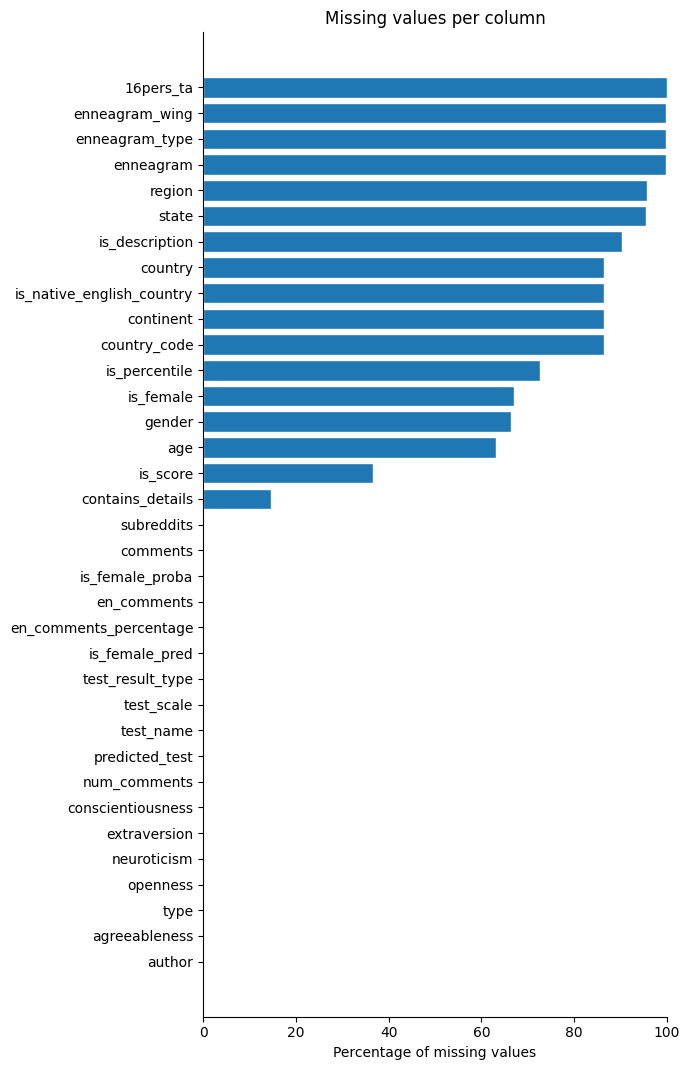

Dropped columns: ['enneagram', 'is_description', 'is_score', 'enneagram_type', 'enneagram_wing', '16pers_ta']
Traits: ['openness', 'conscientiousness', 'extraversion', 'agreeableness', 'neuroticism'] | MBTI flag: []
Other numerical columns: ['contains_details', 'num_comments', 'en_comments', 'en_comments_percentage', 'is_native_english_country']
Duplicates: 0
Declared gender vs predicted gender: 86.0% (n=392)
Authors with more comments than subreddits: 0
Authors with less than 1 commens have been removed: 0
                                 openness              conscientiousness             extraversion             agreeableness              neuroticism             
                                    count   min    max             count   min   max        count   min   max         count   min    max       count   min    max
test_name            test_scale                                                                                                                                  
1

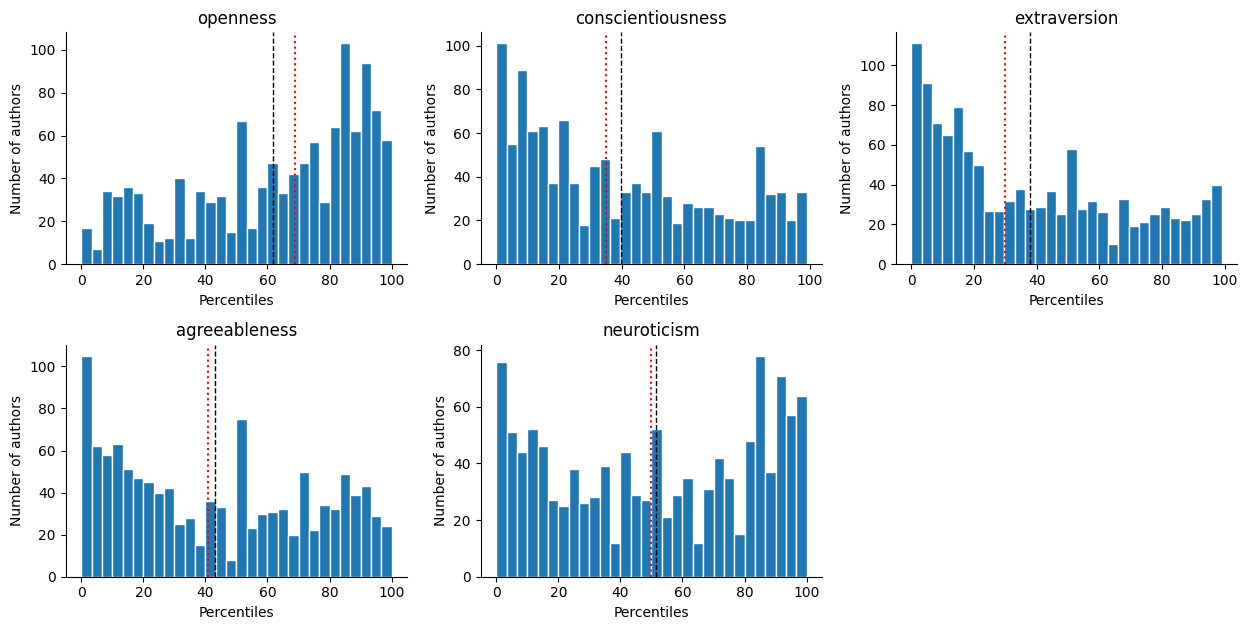

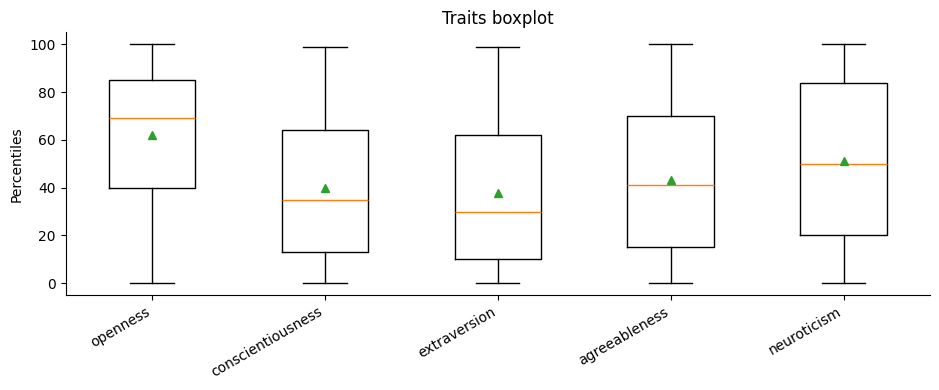

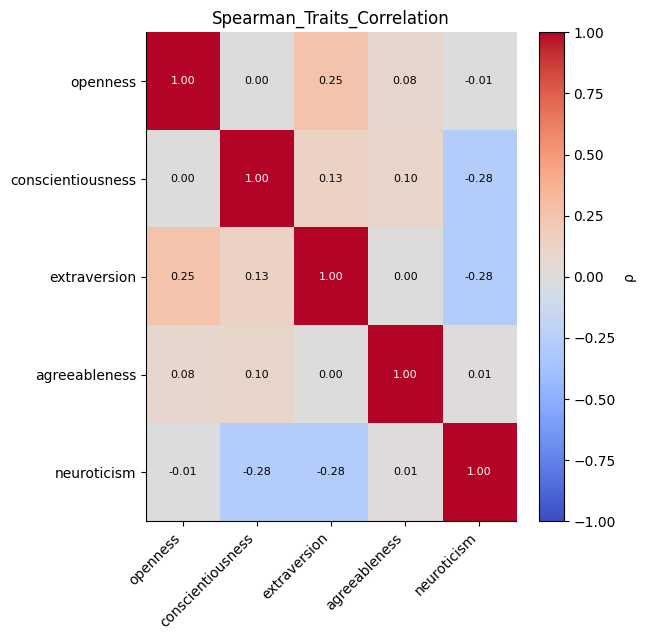

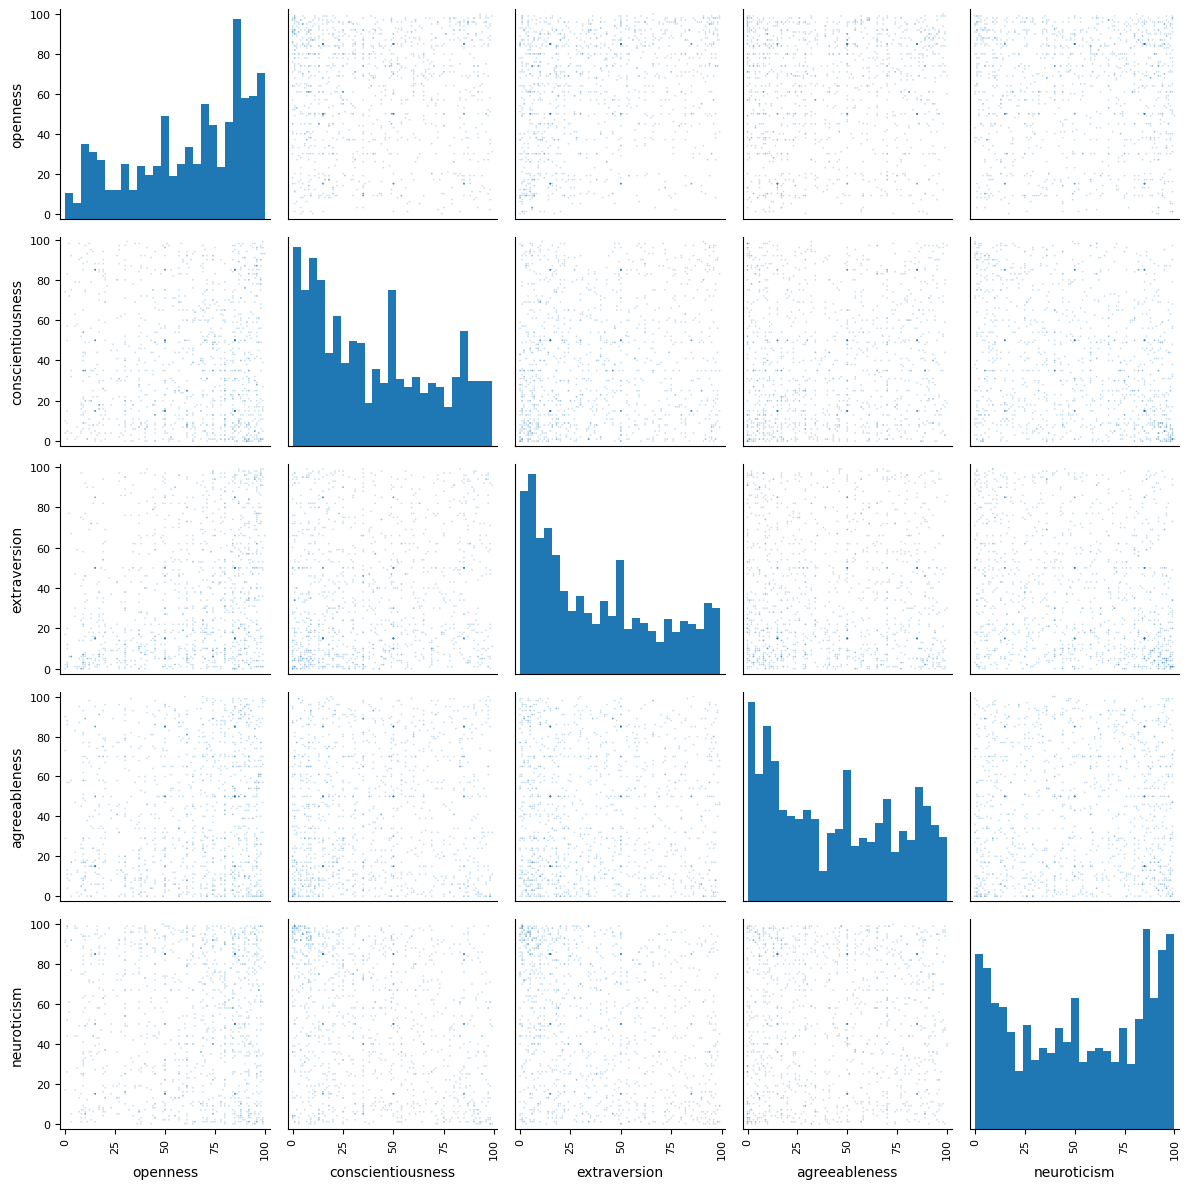

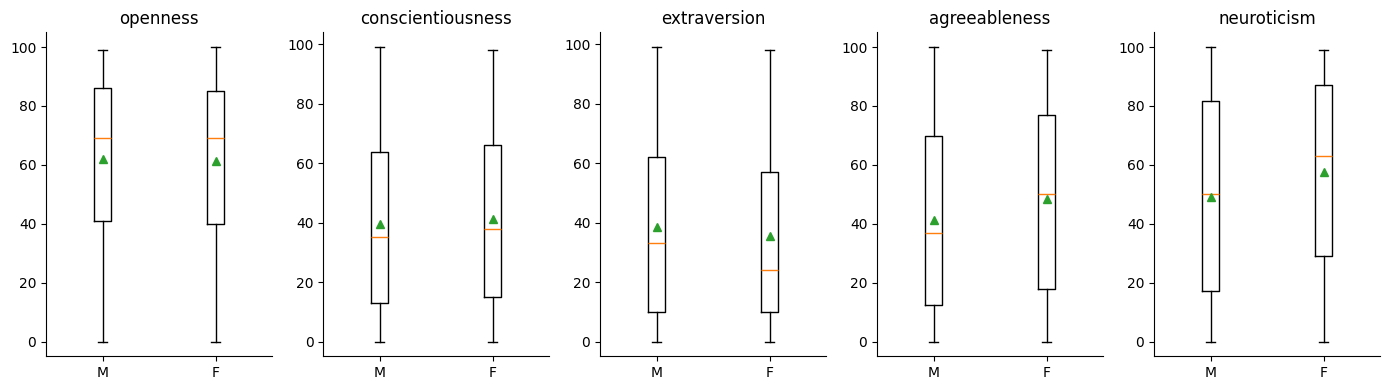

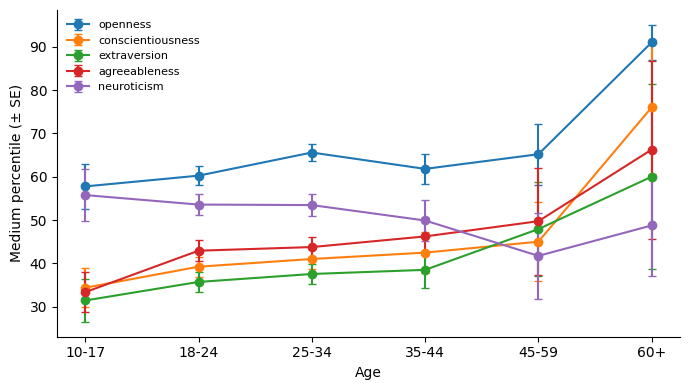

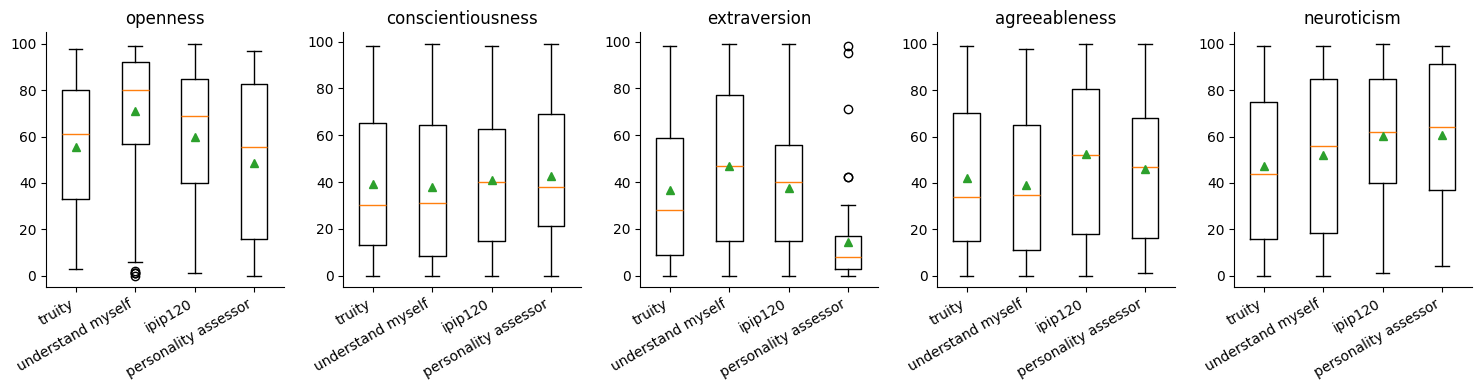

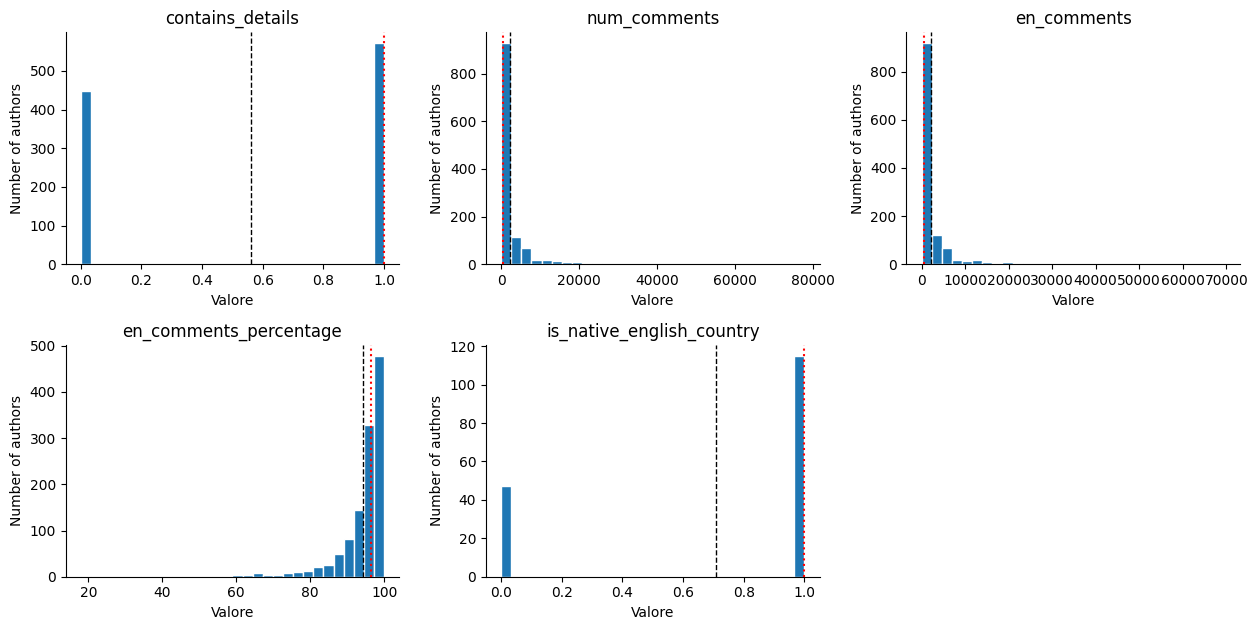

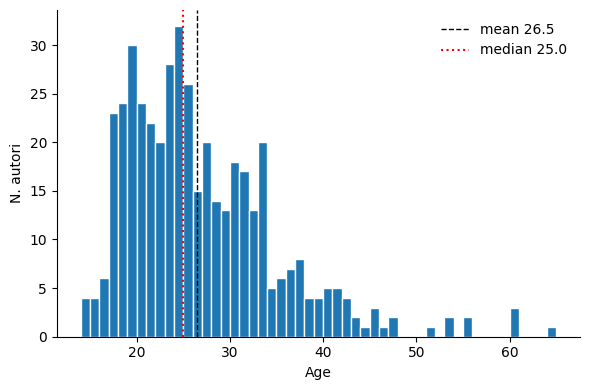

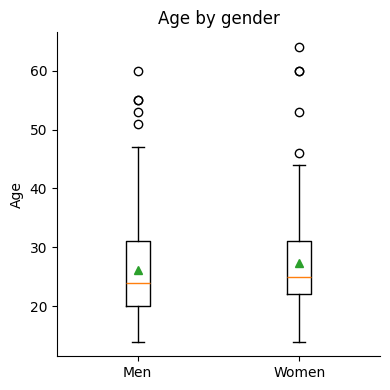

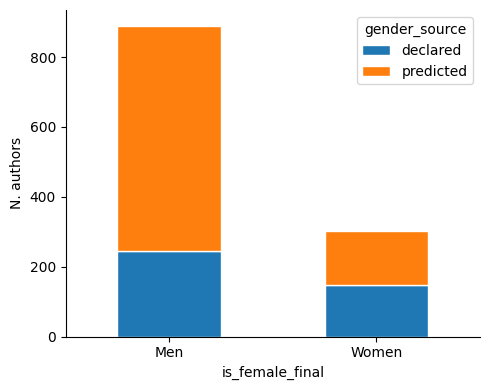

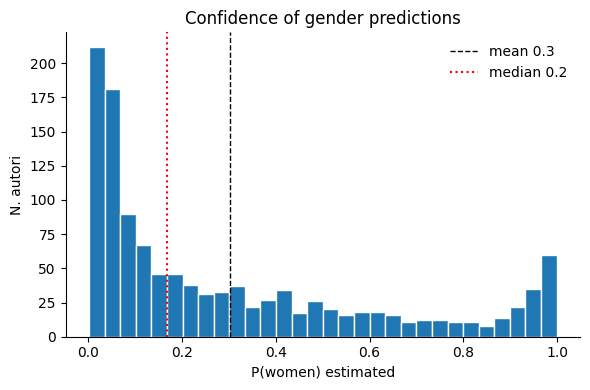

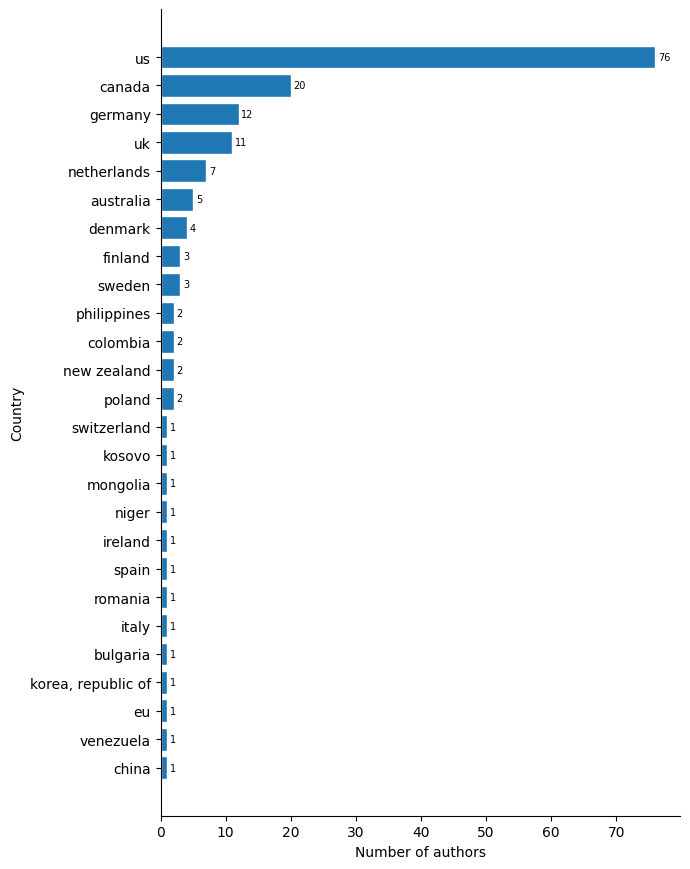

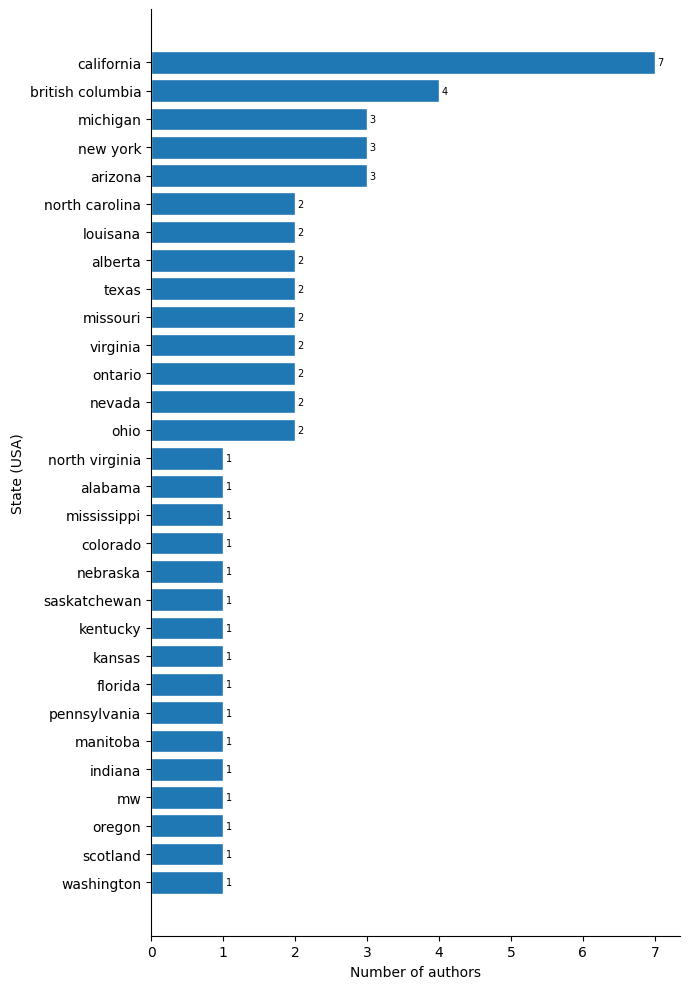

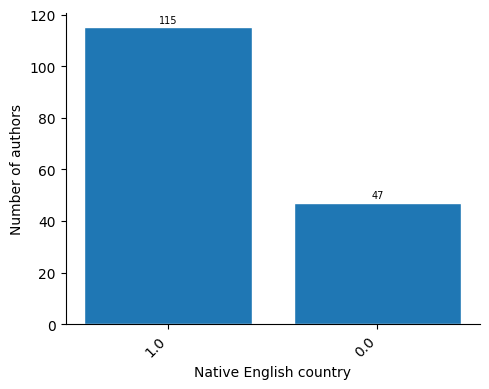

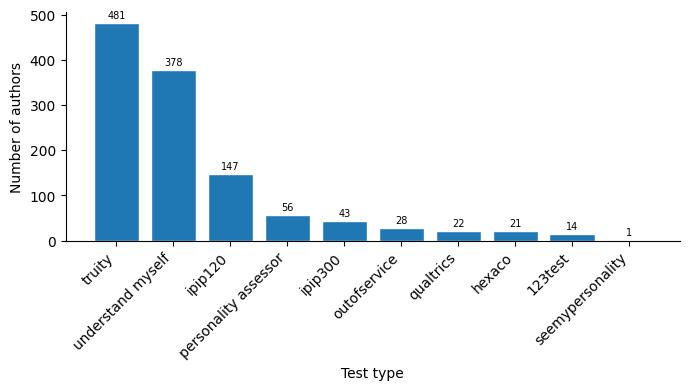

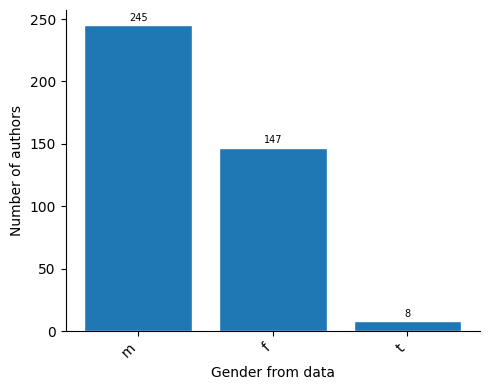

                         count      mean        std  min      5%      25%       50%      75%        95%        max  skew
n_comments              1191.0   1646.68    3684.54  1.0    2.00    54.00    299.00   1555.5    7894.50    52406.0  5.65
n_words_total           1191.0  60949.69  160594.63  7.0  132.00  1877.50  11201.00  55647.5  266409.00  2857859.0  8.75
mean_words_per_comment  1191.0     46.82      41.08  4.4   13.67    24.51     36.54     57.3     109.74      670.0  5.72
n_unique_subreddits     1191.0     56.19      74.05  1.0    1.00     8.00     28.00     75.5     189.50      540.0  2.65


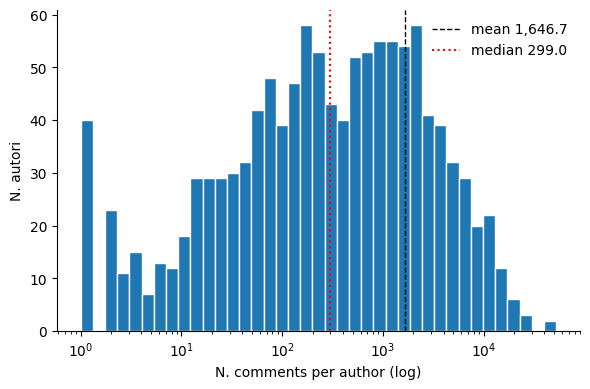

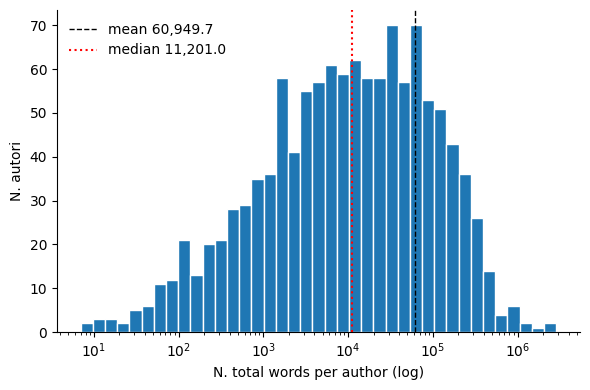

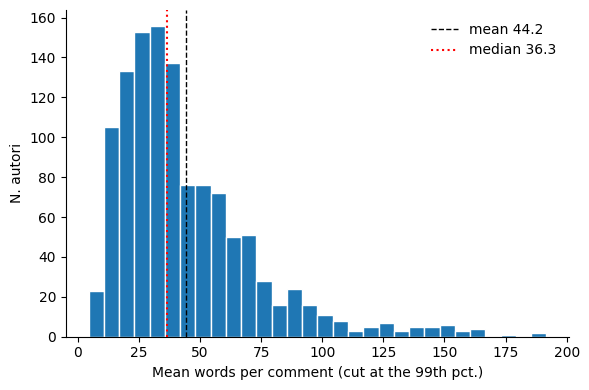

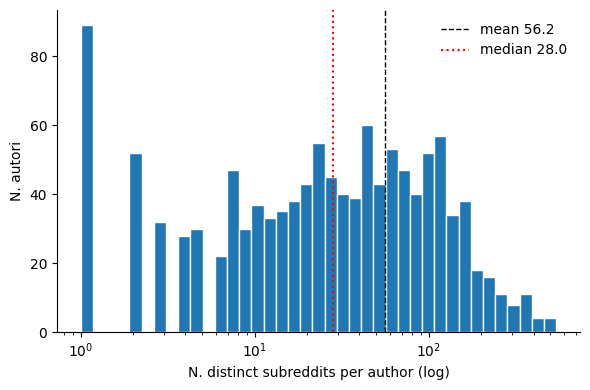

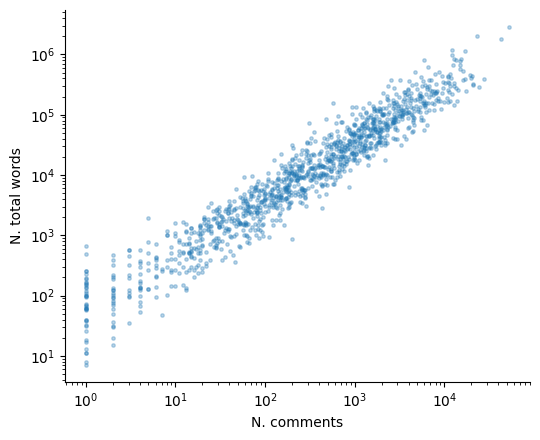

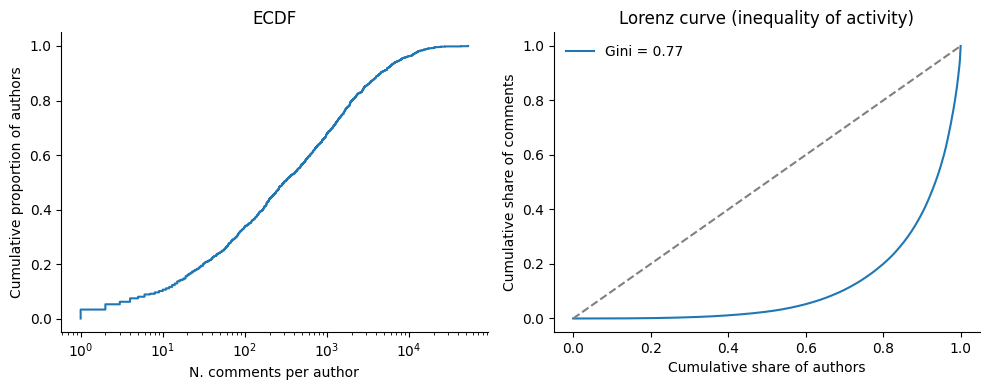

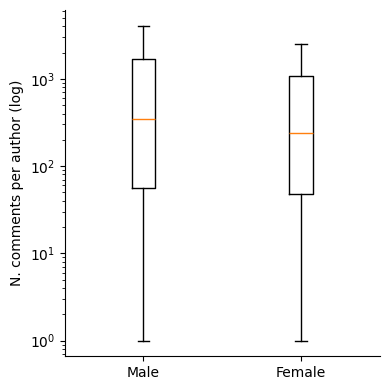

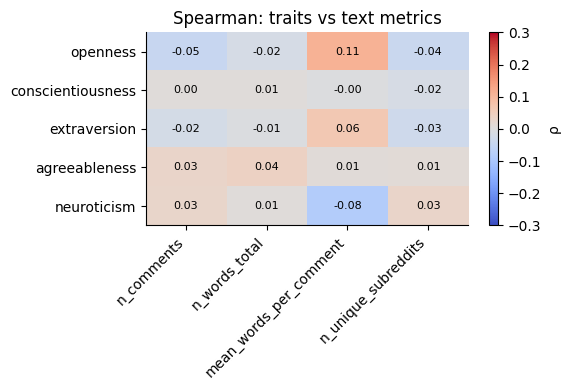

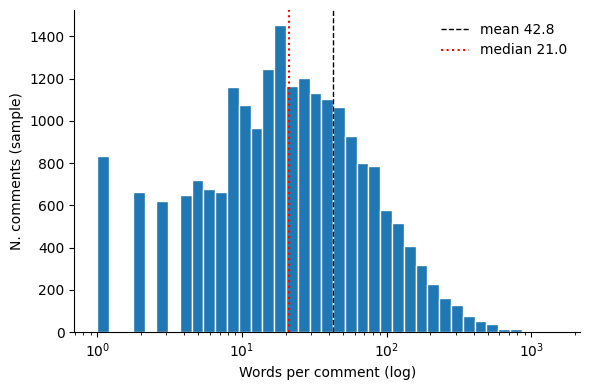

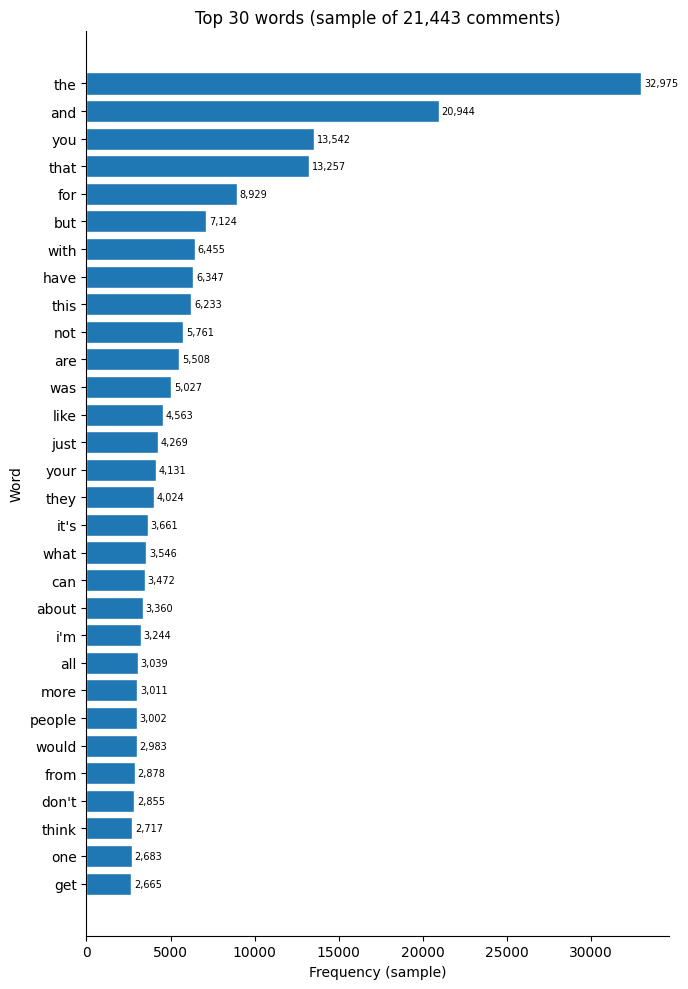

Distinct subreddits: 13,147 | share of the top 10: 28.7%


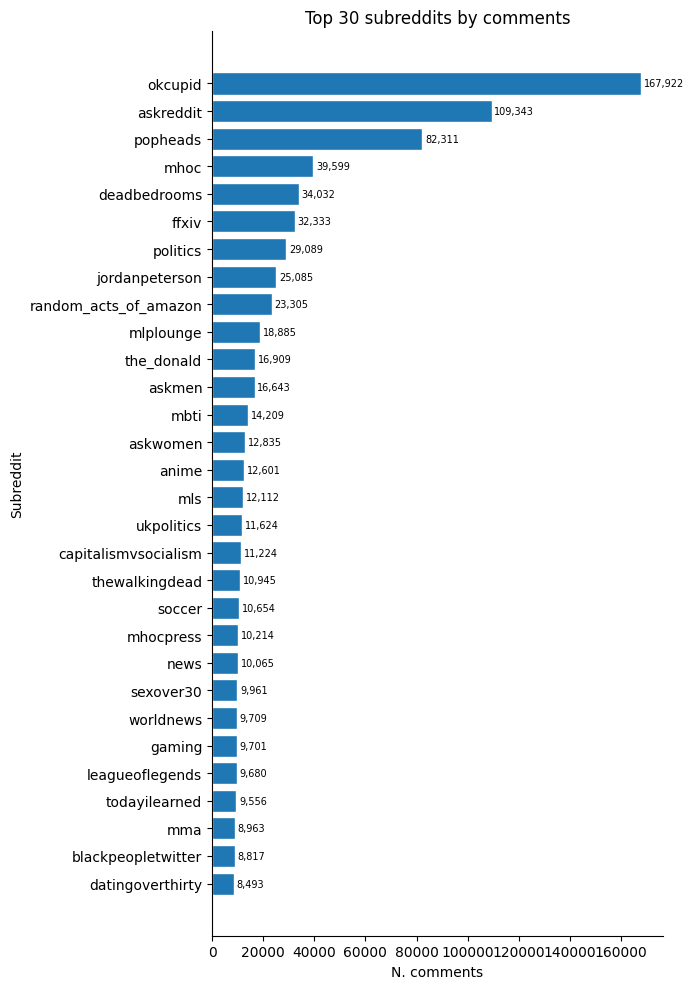

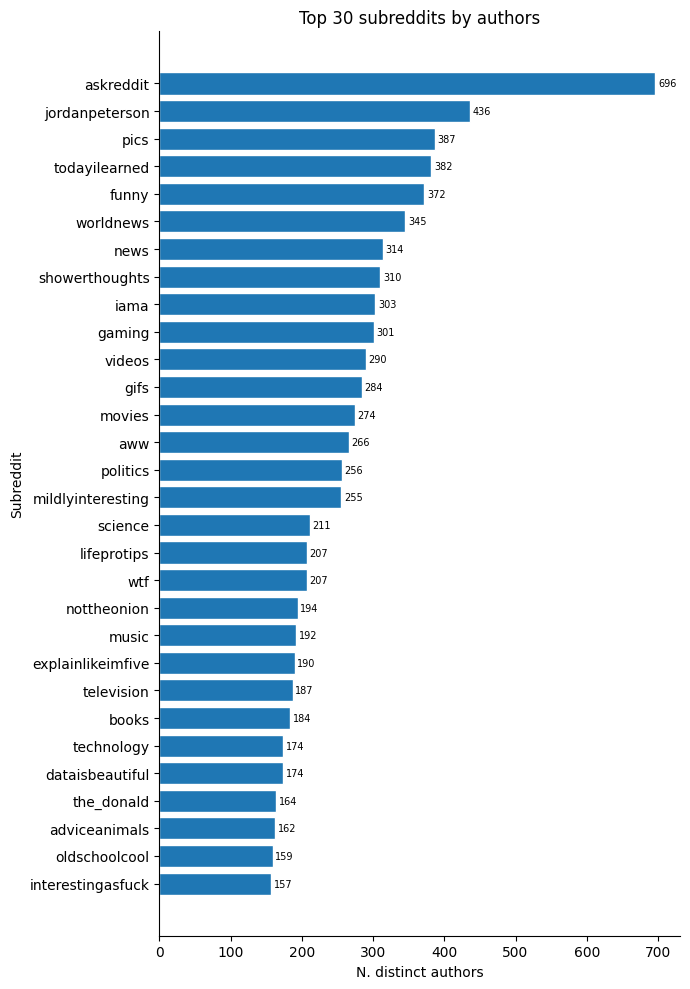

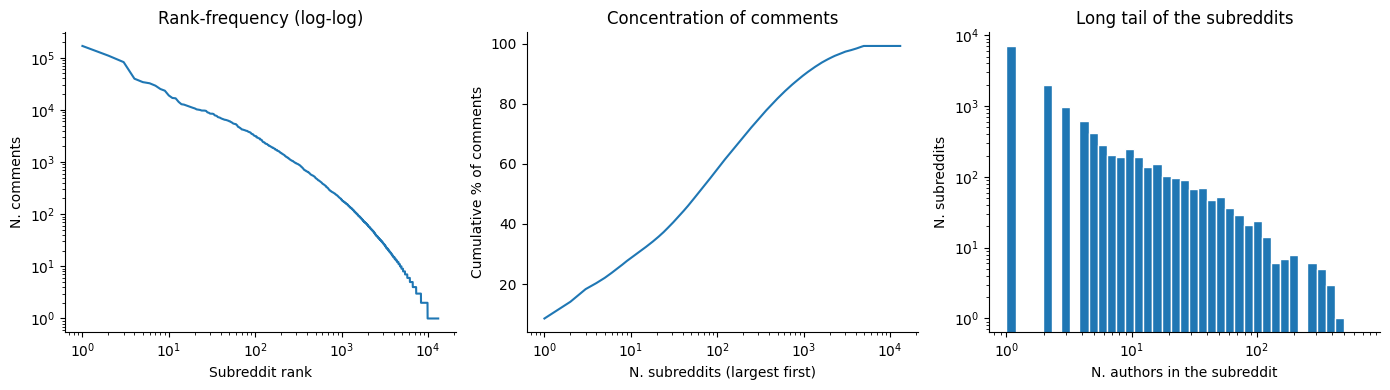

Comments in personality subreddits: 1.6% | authors with at least one: 22.2%


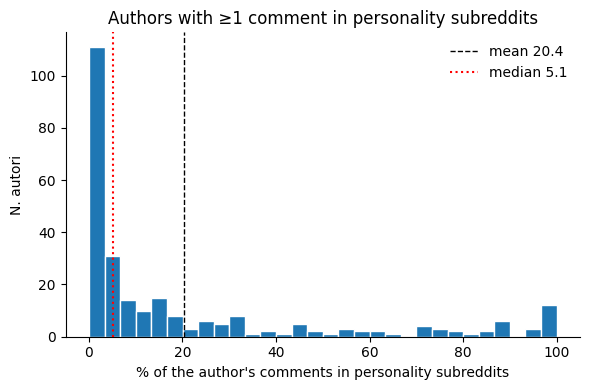

-> completed 'big_five': 1,191 authors
DATASET: mbti_1
/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/mbti_dataset_commented_1.csv
Righe: 8,690 | Colonne: 40
Out of age range (10, 90): 0 -> NaN
                             dtype  n_missing  pct_missing  n_unique                                   example                                     advice
is_percentile              float64       8690       100.00       0.0                                                                DROP (empty/constant)
is_description             float64       8689        99.99       1.0                                       1.0                      DROP (empty/constant)
16pers_ta                   string       8689        99.99       1.0                                         a                      DROP (empty/constant)
openness                   float64       8685        99.94       5.0                                      74.0  consider dropping (more than 90% missing)
conscientiousness          fl

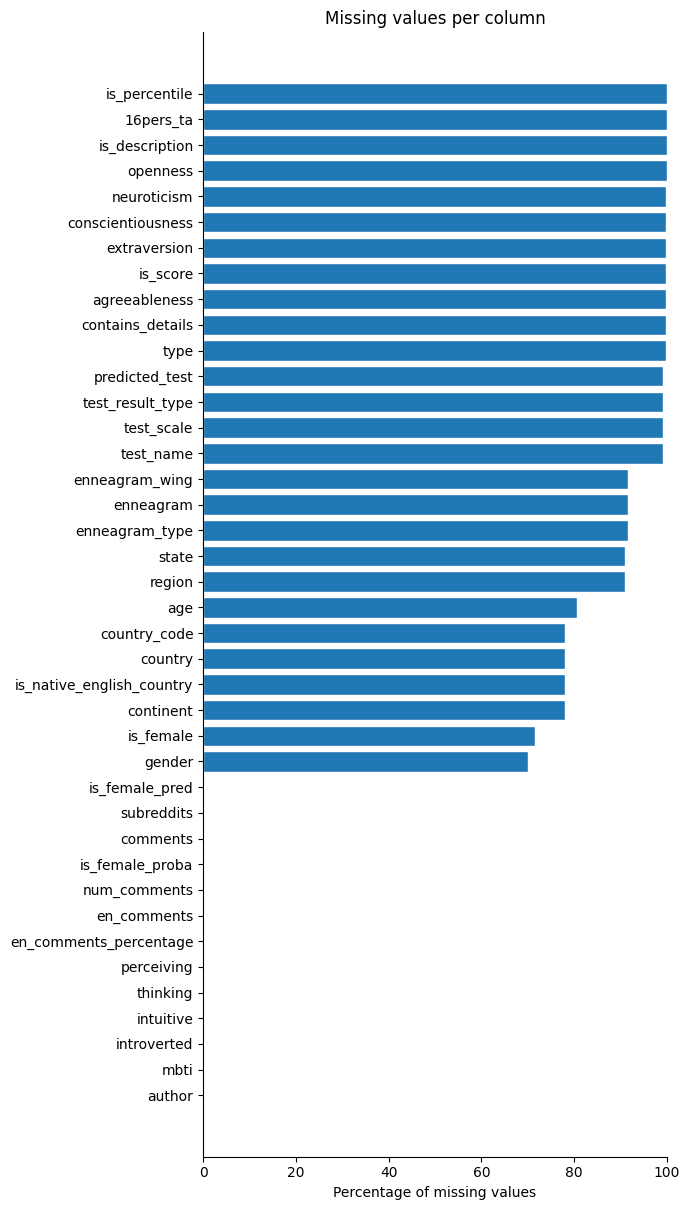

Dropped columns: ['is_description', 'is_percentile', 'is_score', '16pers_ta']
Traits: ['openness', 'conscientiousness', 'extraversion', 'agreeableness', 'neuroticism'] | MBTI flag: ['introverted', 'intuitive', 'thinking', 'perceiving']
Other numerical columns: ['num_comments', 'en_comments', 'en_comments_percentage', 'enneagram_type', 'enneagram_wing', 'is_native_english_country']
Duplicates: 0
Declared gender vs predicted gender: 89.7% (n=2477)
Missing or invalid MBTI: 0
Flag coherence by MBTI type:
 I/E          100.0
N/S          100.0
T/F          100.0
P/J          100.0
full type    100.0
MBTI type obtained by flags for 0 authors
Authors with more comments than subreddits: 0
Authors with less than 1 commens have been removed: 0
                              openness            conscientiousness            extraversion            agreeableness             neuroticism           
                                 count  min   max             count  min   max        count  min   max  

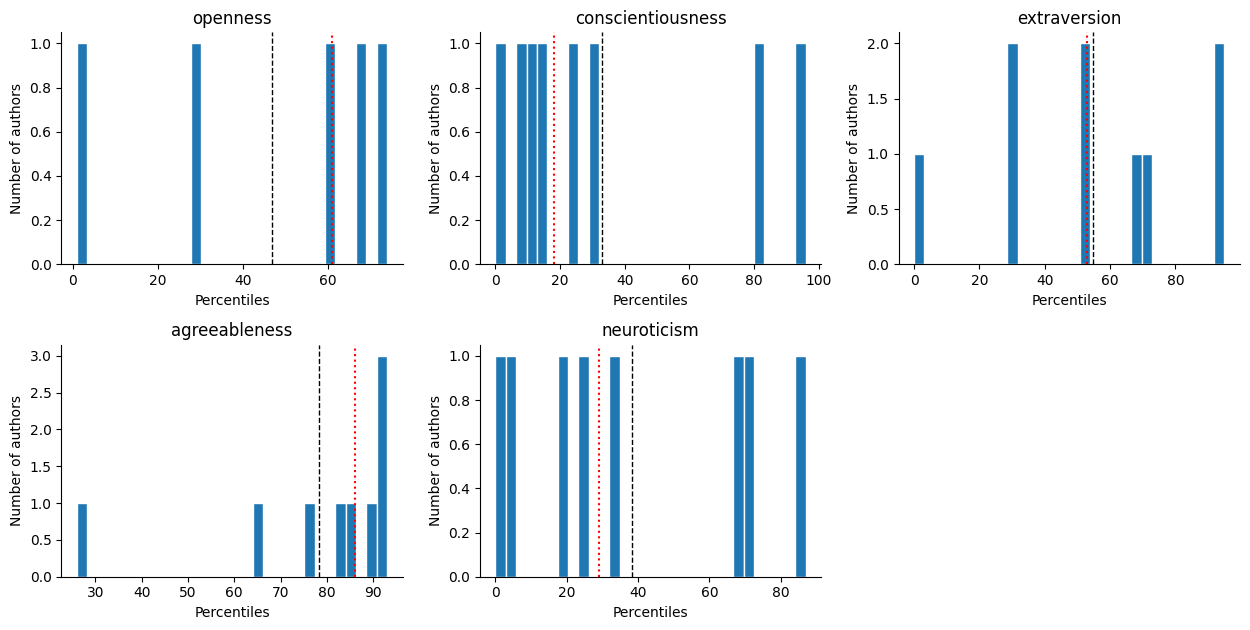

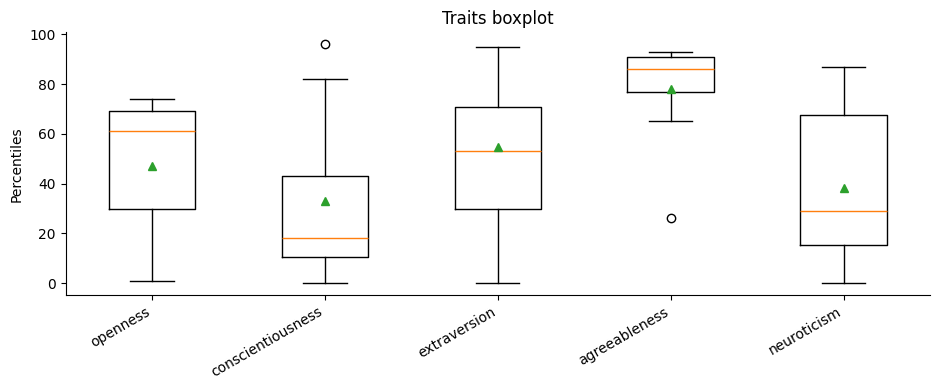

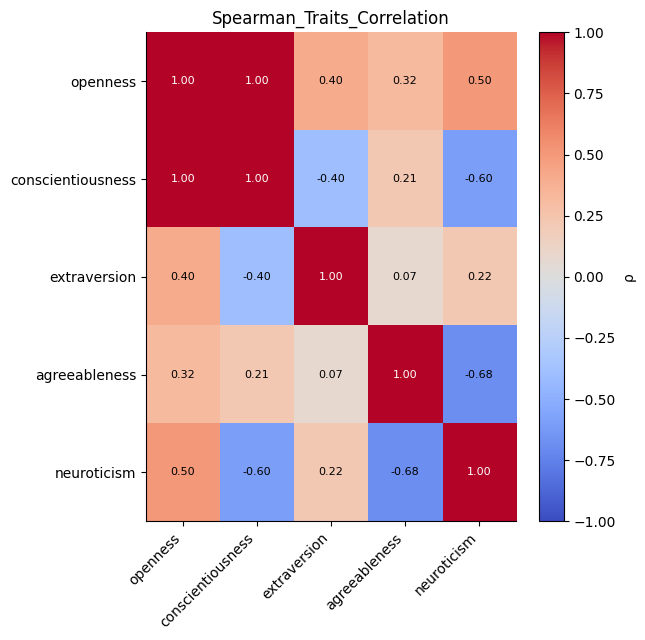

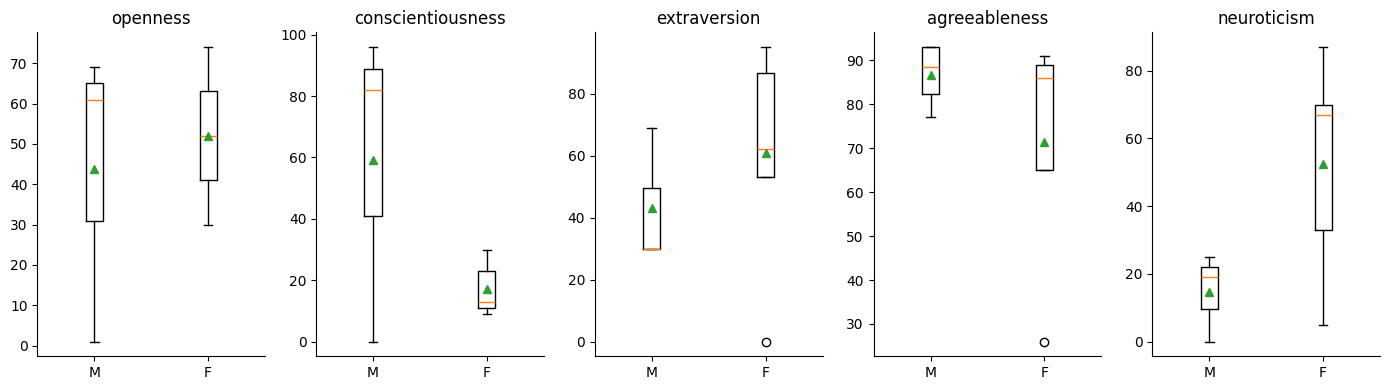

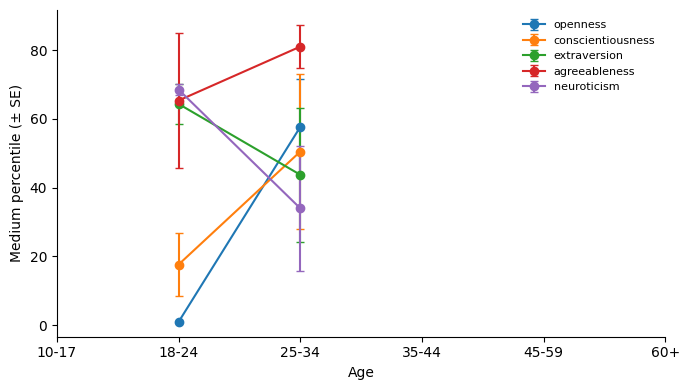

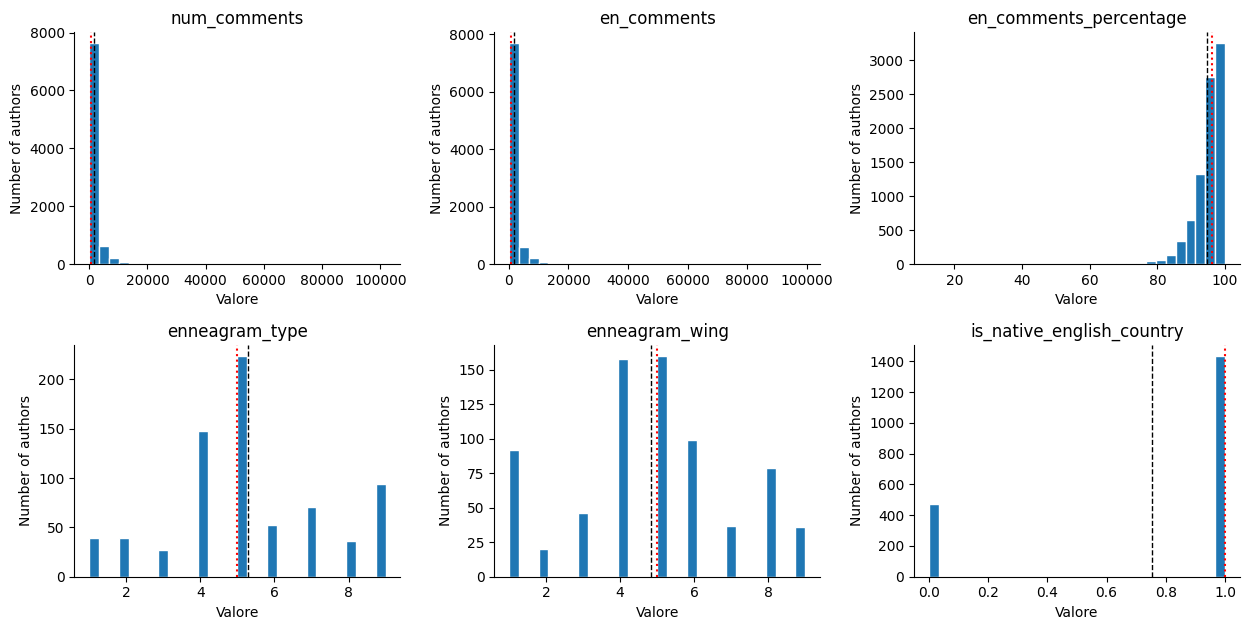

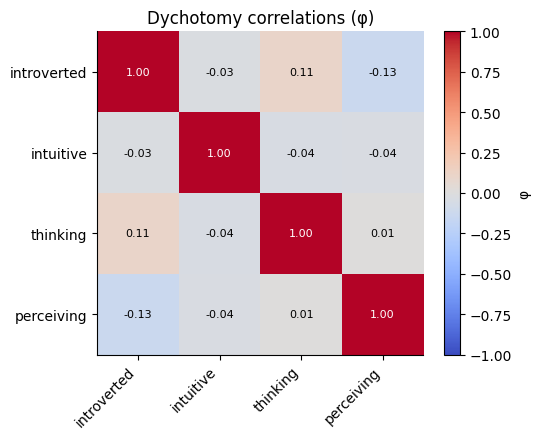

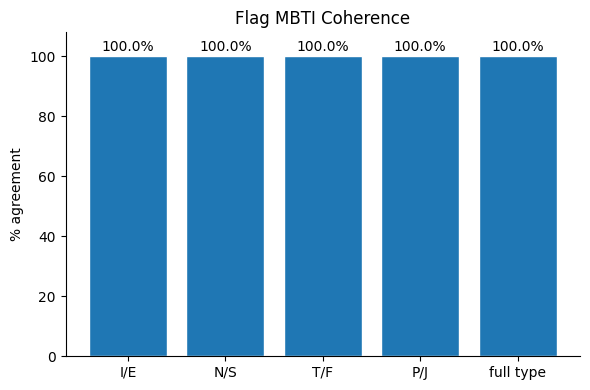

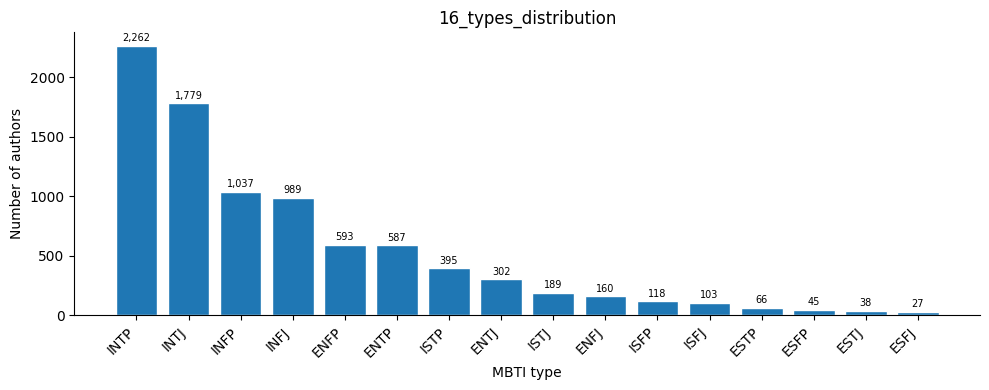

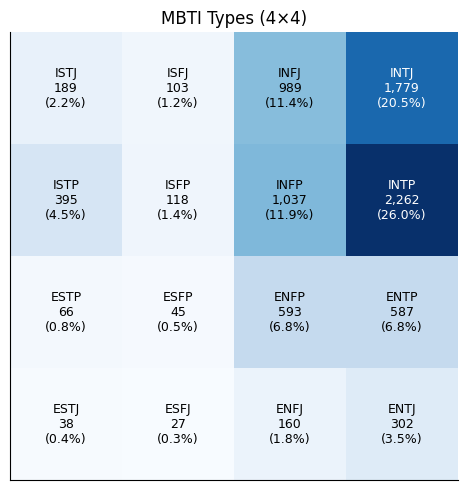

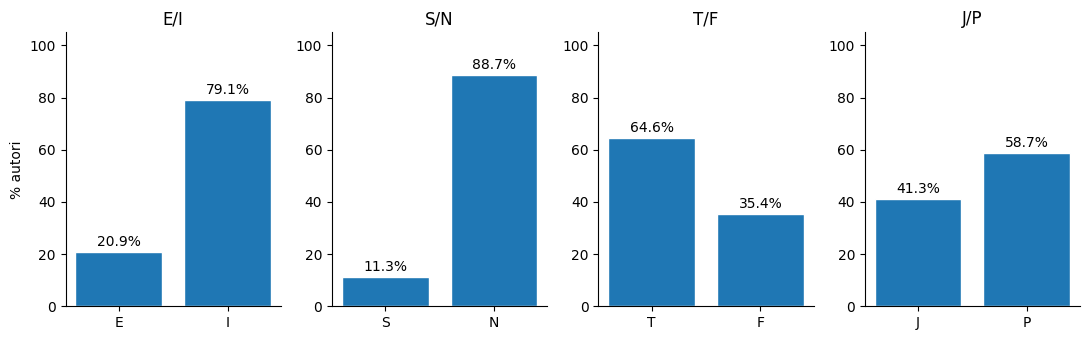

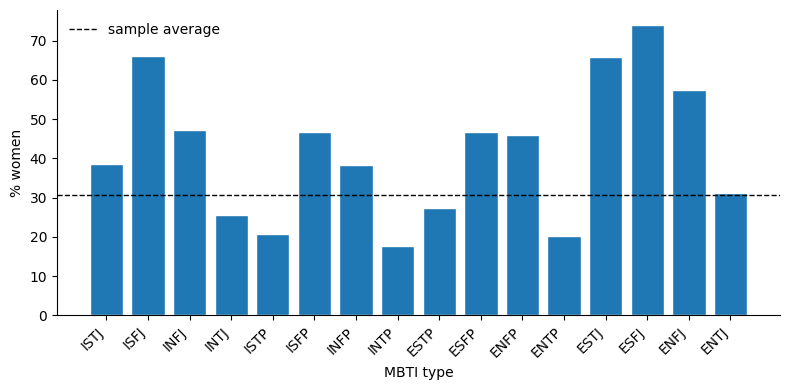

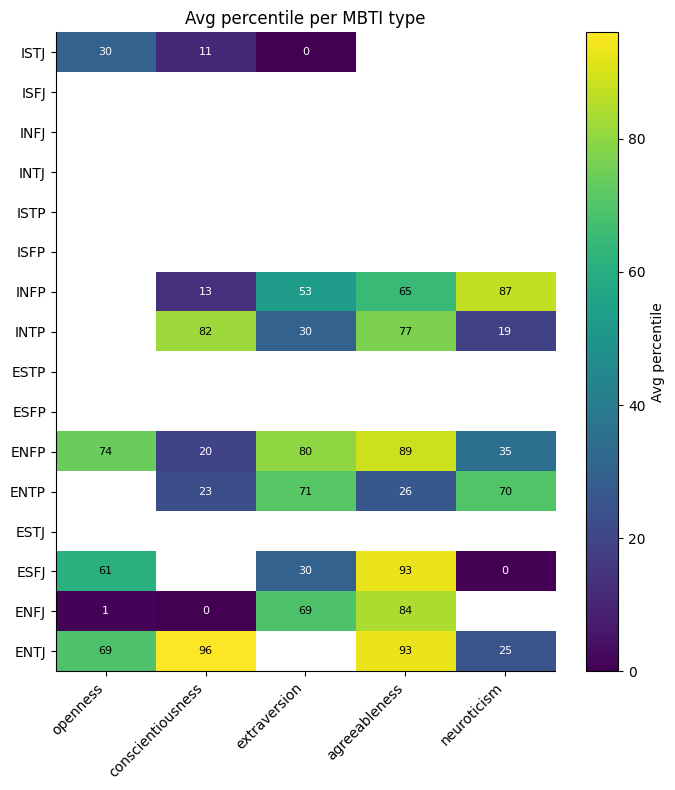

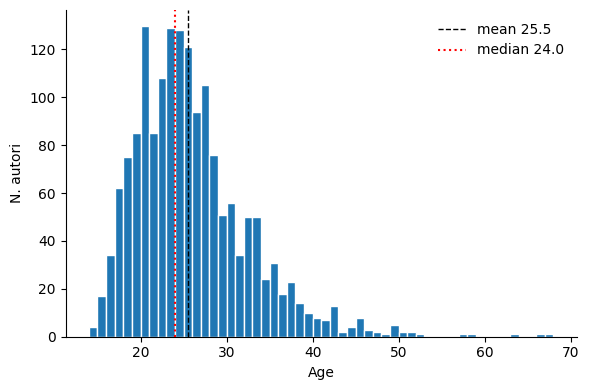

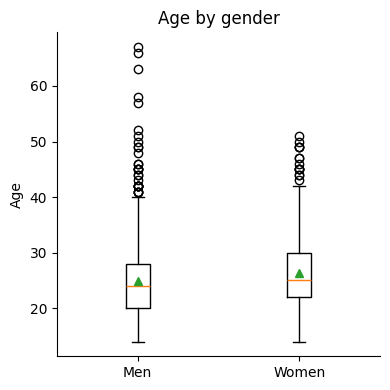

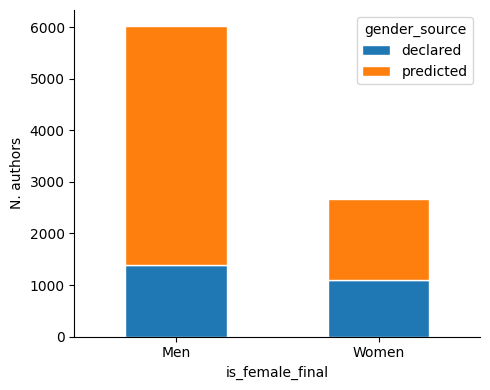

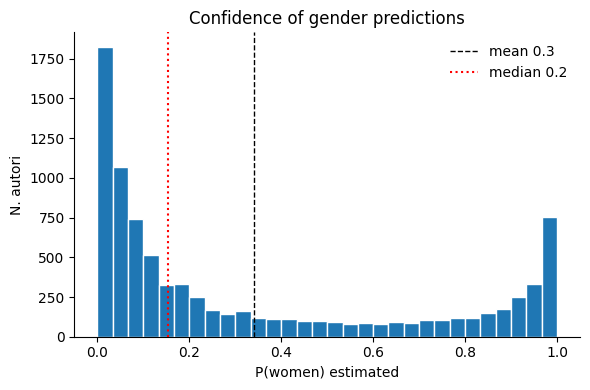

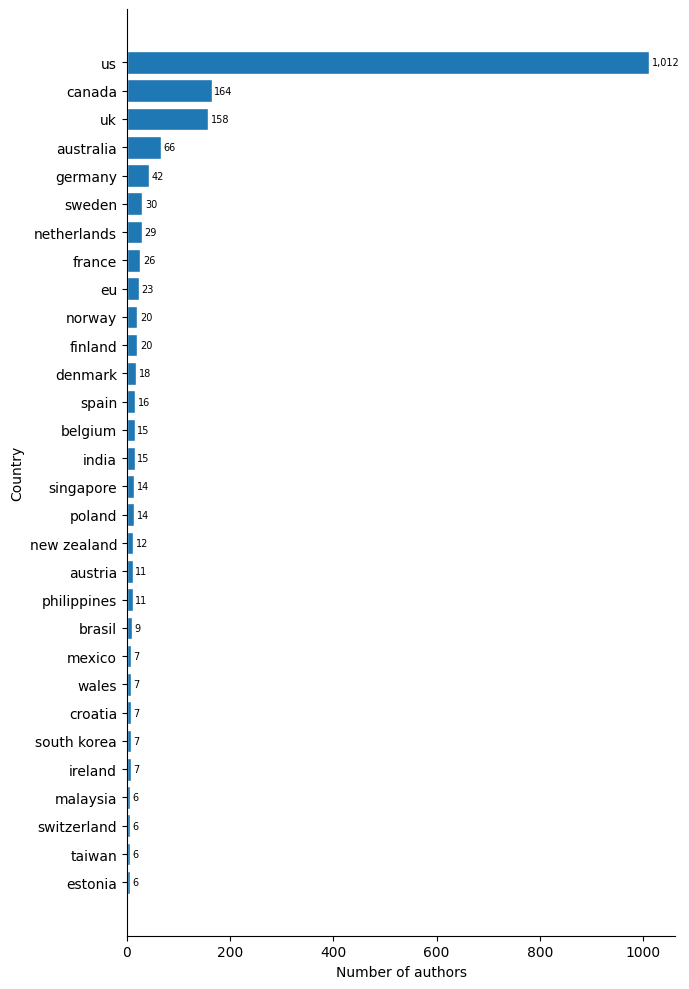

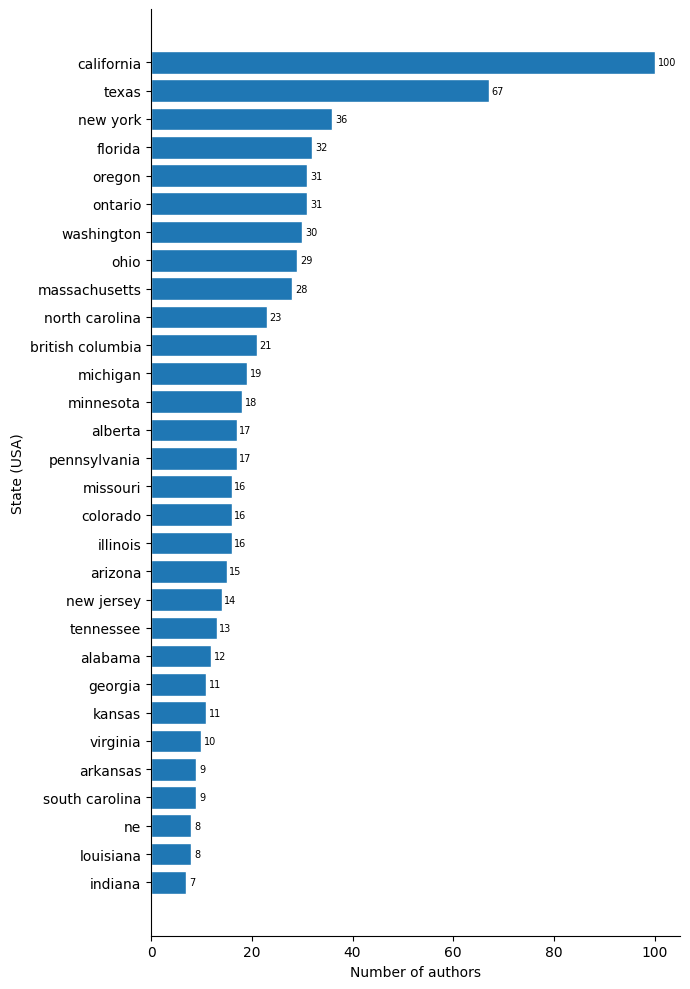

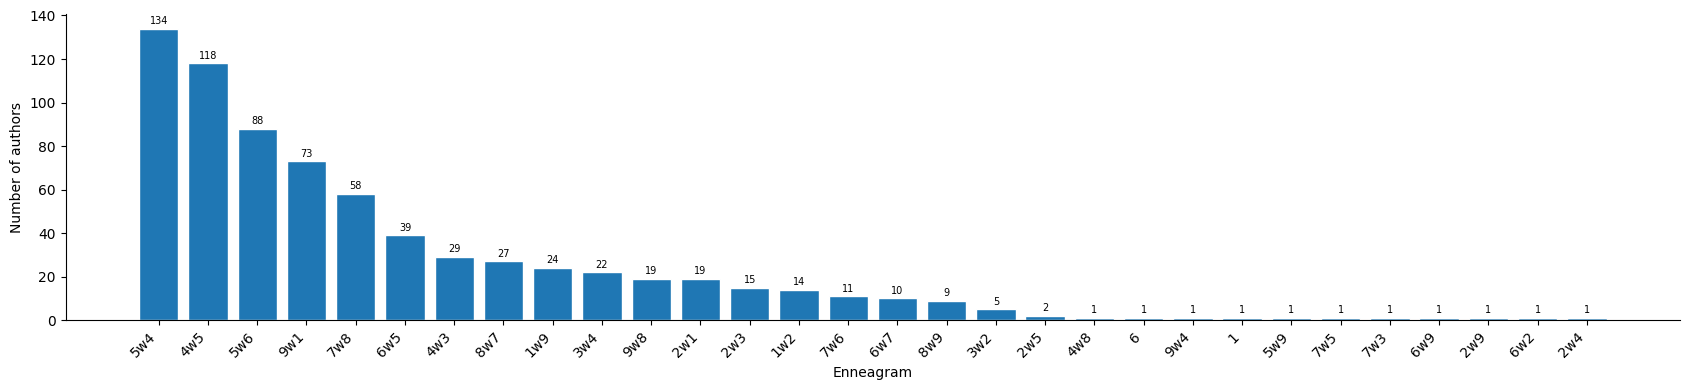

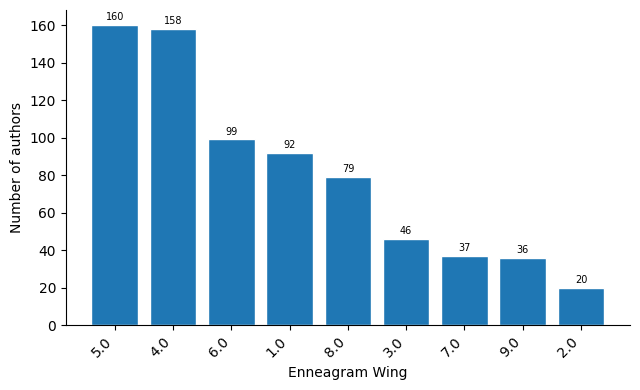

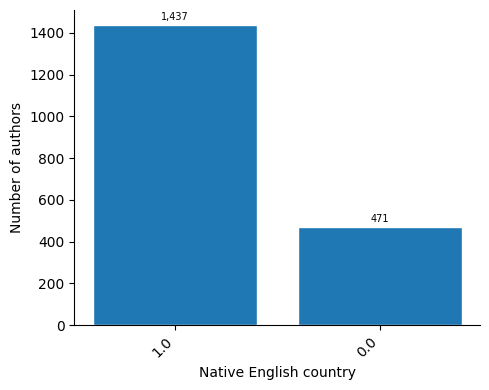

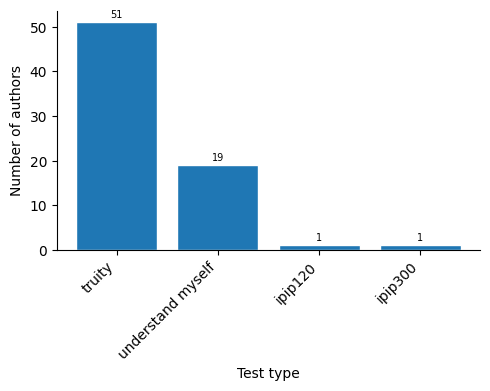

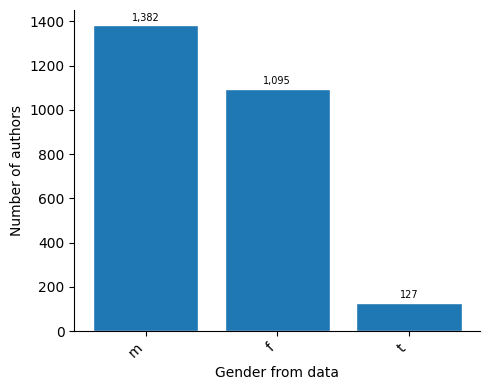

                         count      mean        std      min       5%      25%       50%       75%        95%         max   skew
n_comments              8690.0   1150.75    2519.92     8.00    61.00   175.00    429.00   1110.75    4491.40    80120.00  10.17
n_words_total           8690.0  42017.32  104826.63  1057.00  2318.25  6218.75  14947.50  38436.50  164163.05  3019438.00  12.25
mean_words_per_comment  8690.0     41.66      25.99     5.85    15.00    24.52     35.39     51.58      87.69      518.15   3.09
n_unique_subreddits     8690.0     67.06      69.14     2.00    10.00    24.00     45.00     85.00     196.55      931.00   3.09


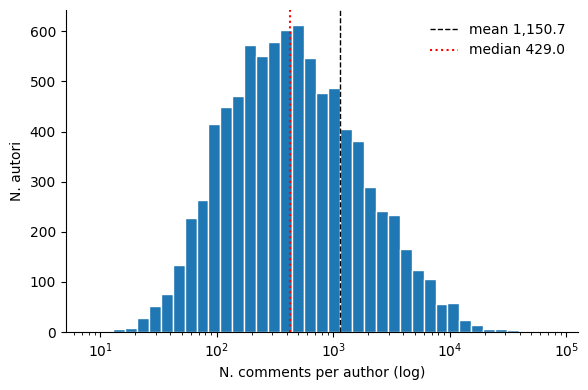

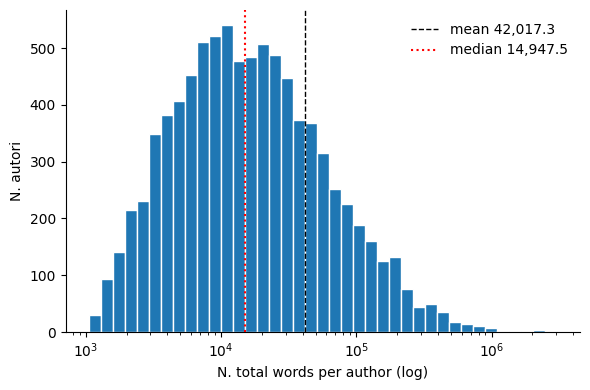

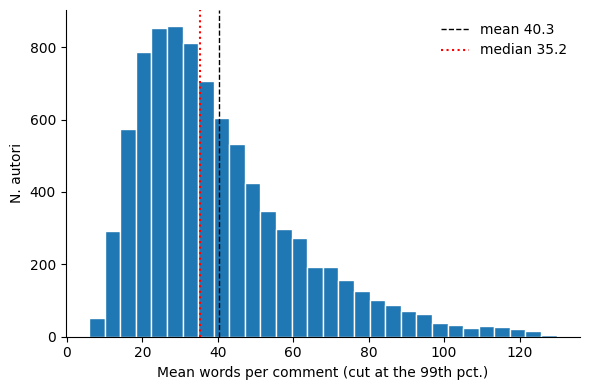

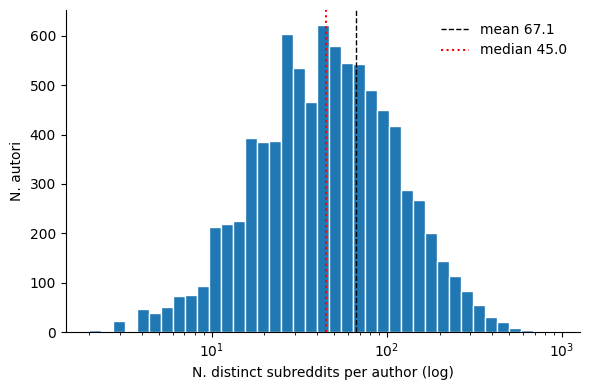

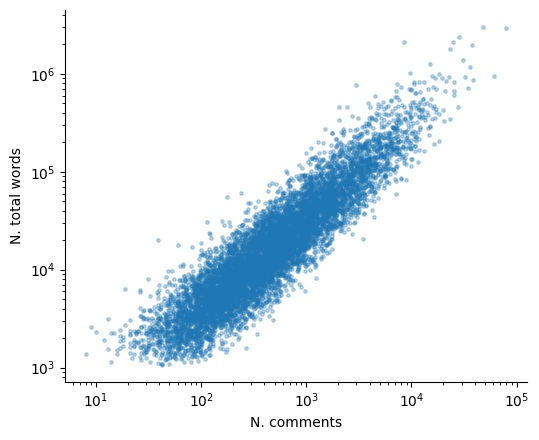

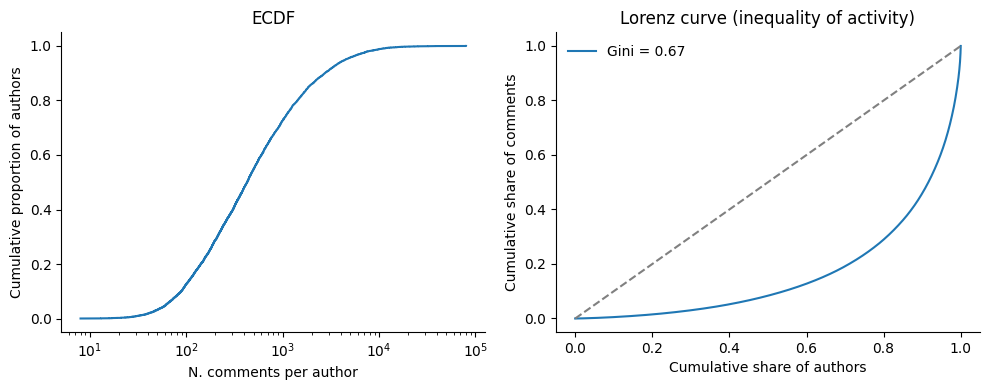

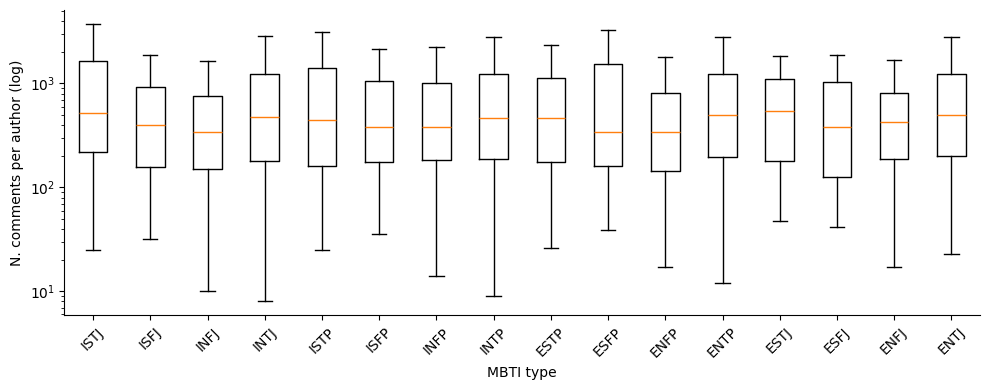

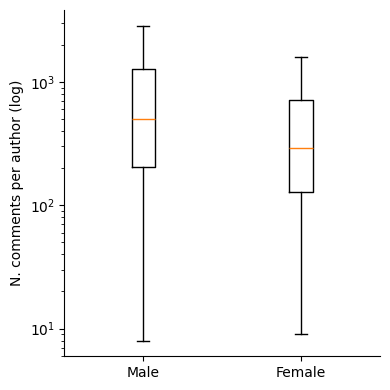

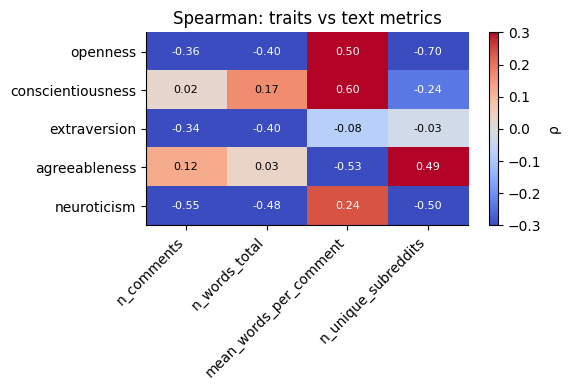

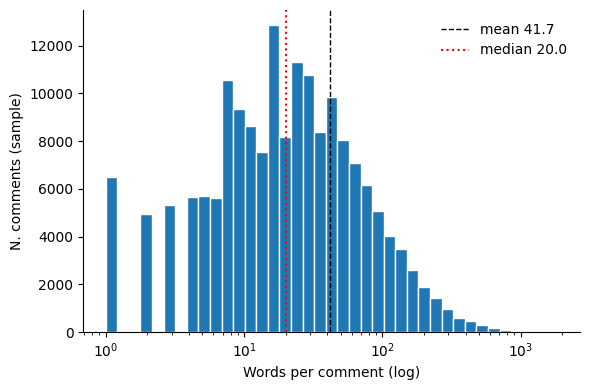

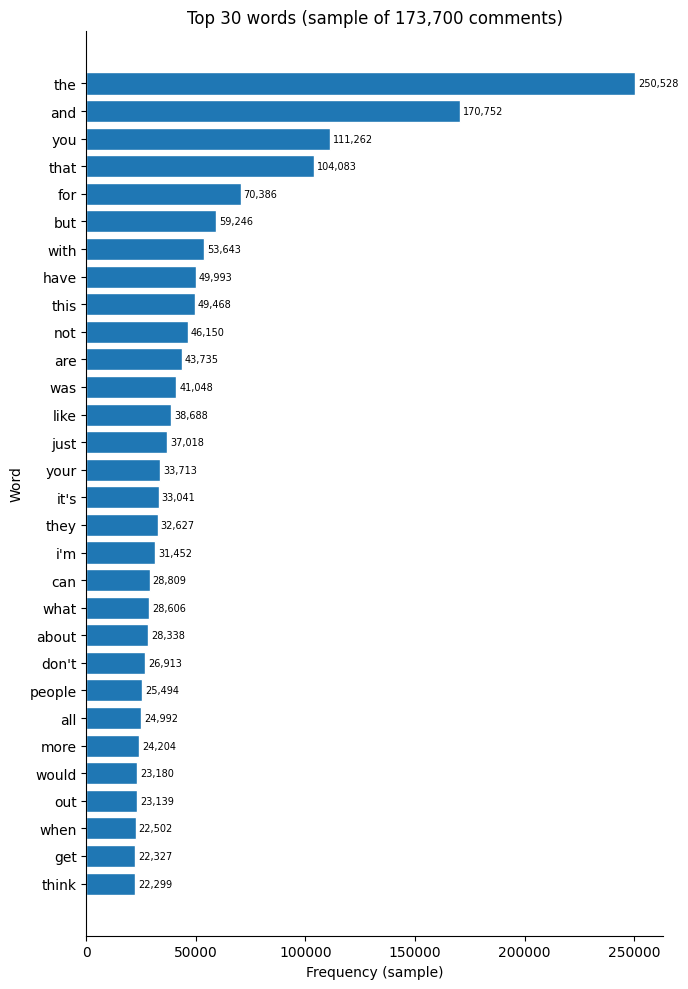

Distinct subreddits: 35,440 | share of the top 10: 18.9%


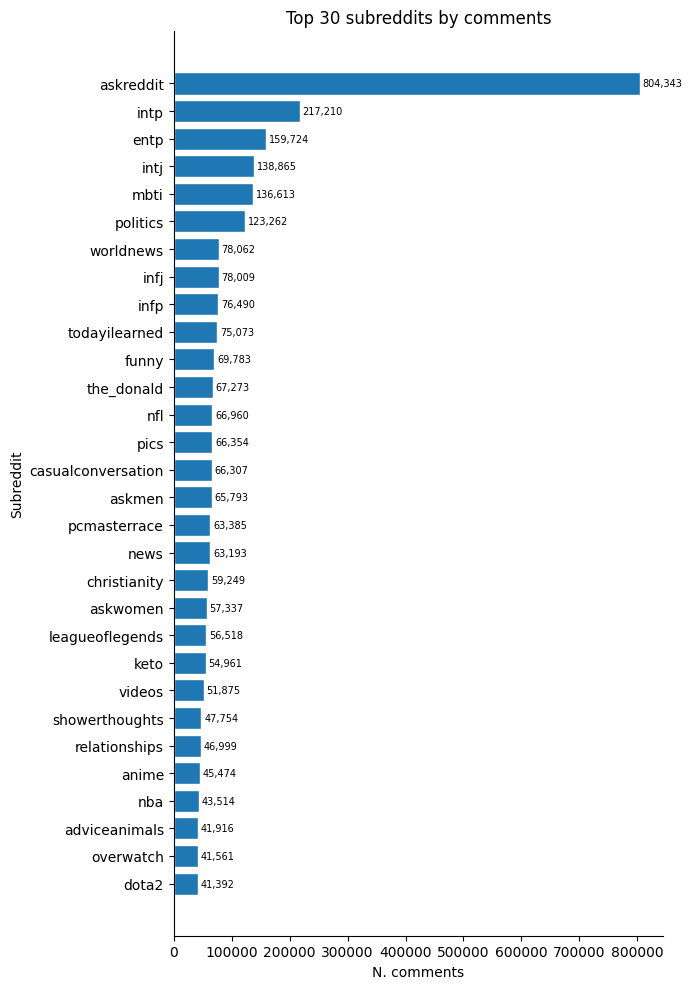

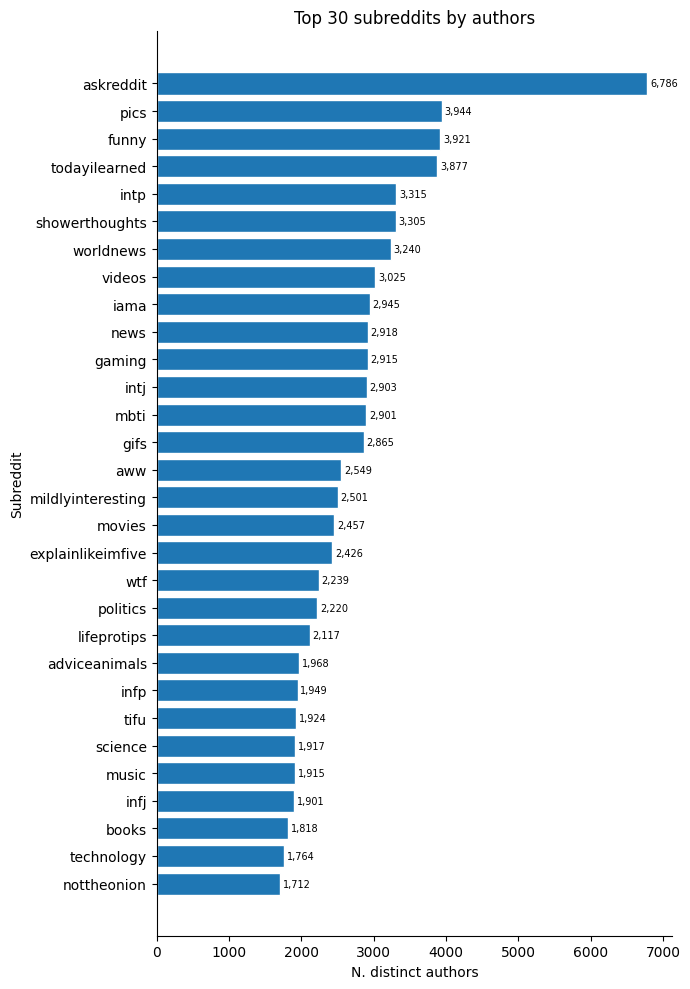

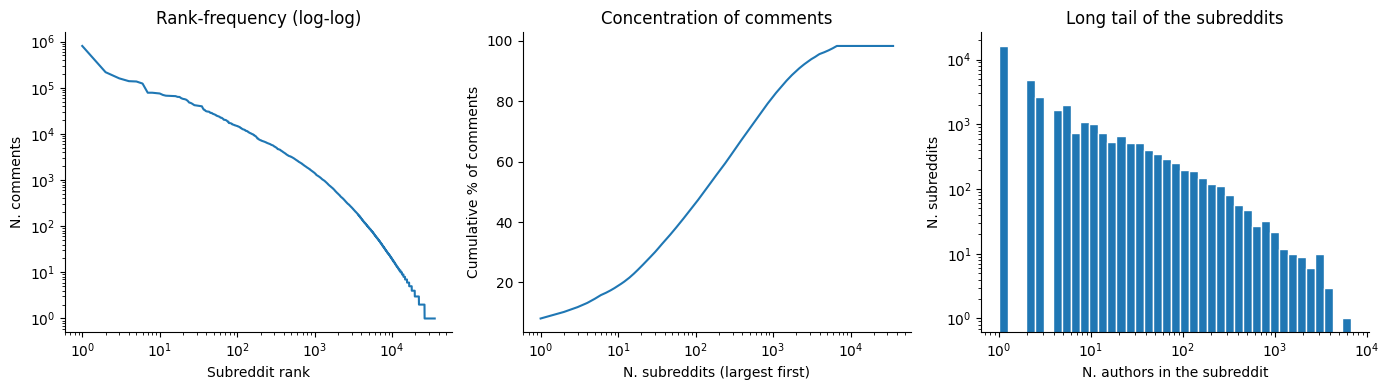

Comments in personality subreddits: 9.1% | authors with at least one: 99.9%


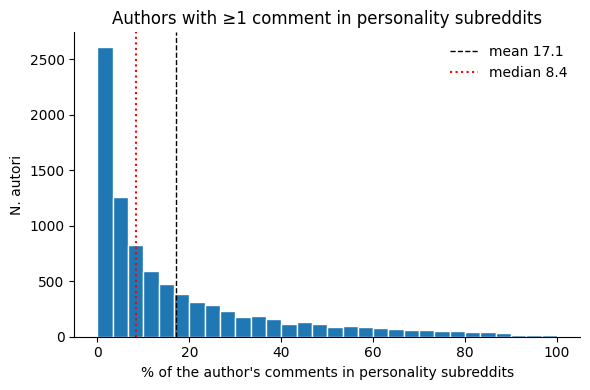

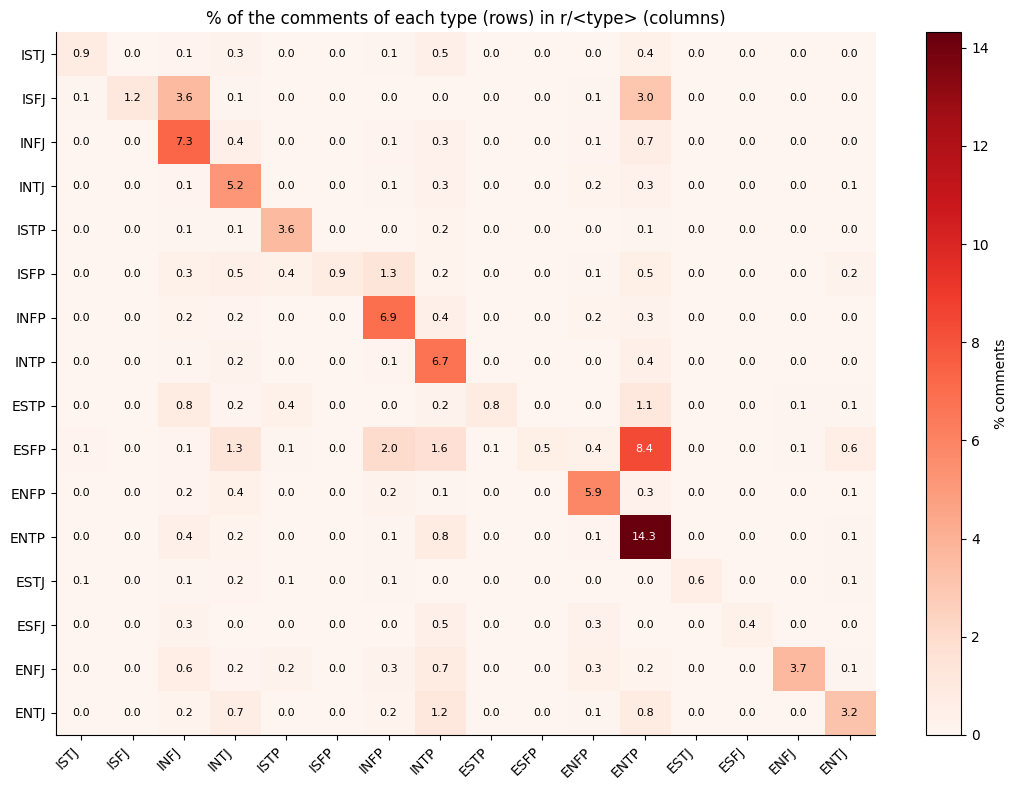

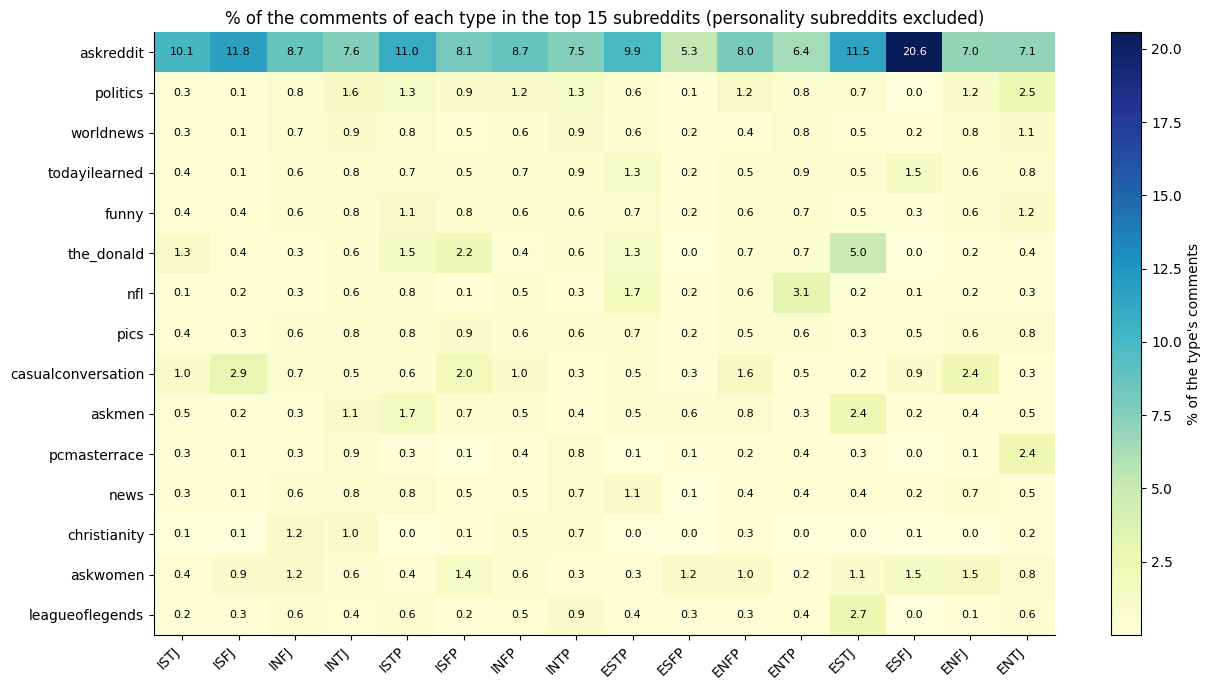

-> completed 'mbti_1': 8,690 authors
DATASET: mbti_2
/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/mbti_dataset_commented_2.csv
Righe: 7,022 | Colonne: 40
Out of age range (10, 90): 0 -> NaN
                             dtype  n_missing  pct_missing  n_unique                                   example                                     advice
is_percentile              float64       7022       100.00       0.0                                                                DROP (empty/constant)
is_description             float64       7021        99.99       1.0                                       1.0                      DROP (empty/constant)
16pers_ta                   string       7021        99.99       1.0                                         a                      DROP (empty/constant)
openness                   float64       7018        99.94       4.0                                      74.0  consider dropping (more than 90% missing)
conscientiousness          floa

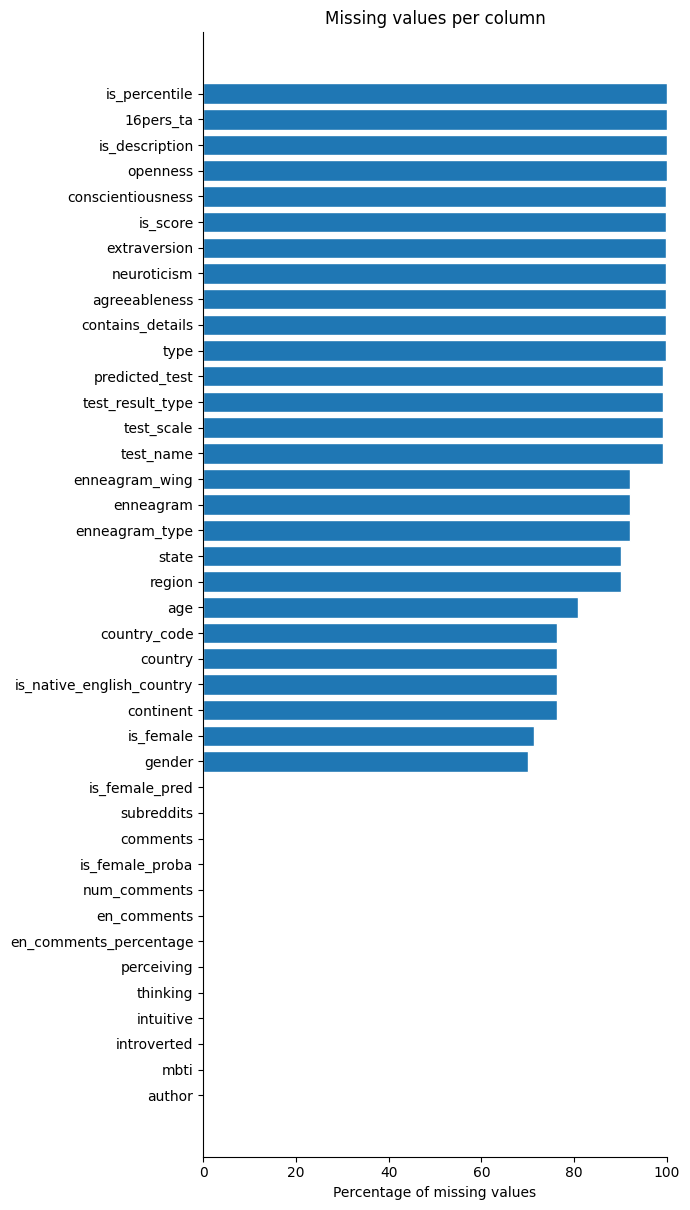

Dropped columns: ['is_description', 'is_percentile', 'is_score', '16pers_ta']
Traits: ['openness', 'conscientiousness', 'extraversion', 'agreeableness', 'neuroticism'] | MBTI flag: ['introverted', 'intuitive', 'thinking', 'perceiving']
Other numerical columns: ['num_comments', 'en_comments', 'en_comments_percentage', 'enneagram_type', 'enneagram_wing', 'is_native_english_country']
Duplicates: 0
Declared gender vs predicted gender: 89.8% (n=2010)
Missing or invalid MBTI: 0
Flag coherence by MBTI type:
 I/E          100.0
N/S          100.0
T/F          100.0
P/J          100.0
full type    100.0
MBTI type obtained by flags for 0 authors
Authors with more comments than subreddits: 0
Authors with less than 1 commens have been removed: 0
                              openness             conscientiousness            extraversion            agreeableness             neuroticism           
                                 count   min   max             count  min   max        count  min   max

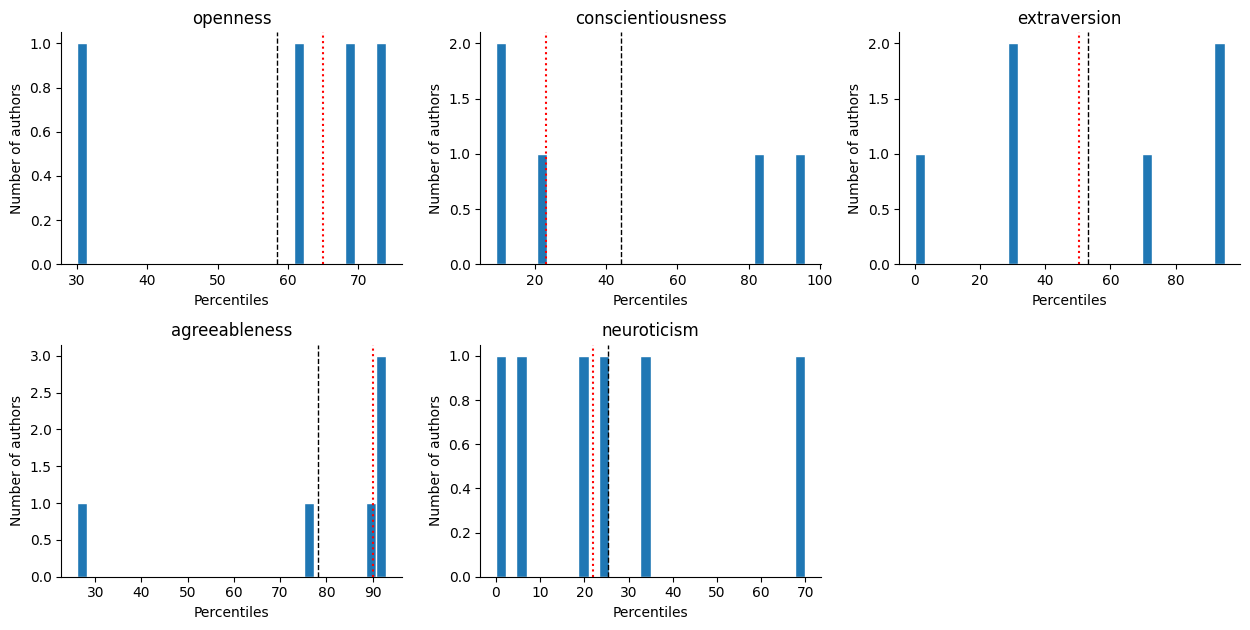

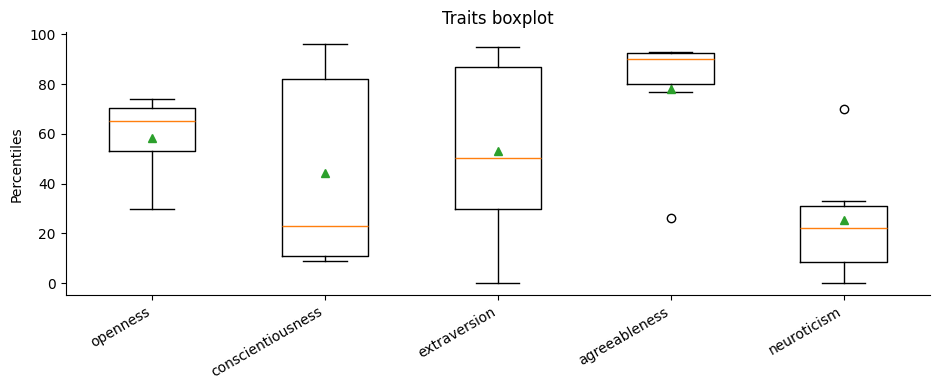

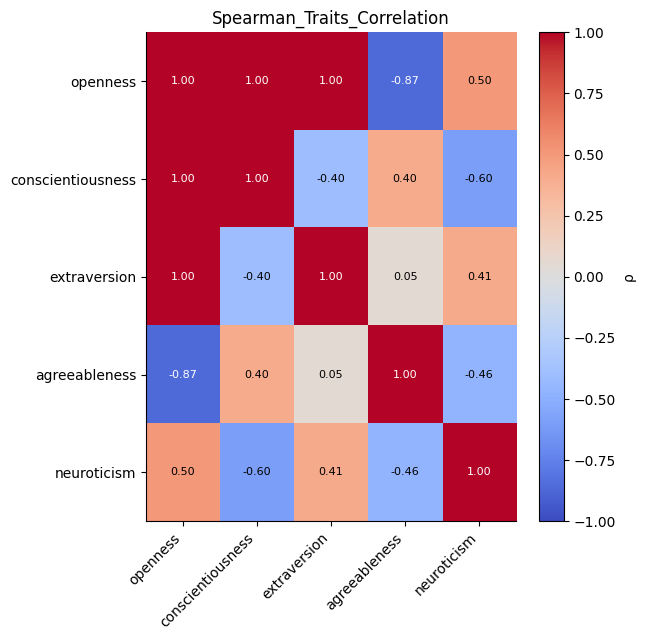

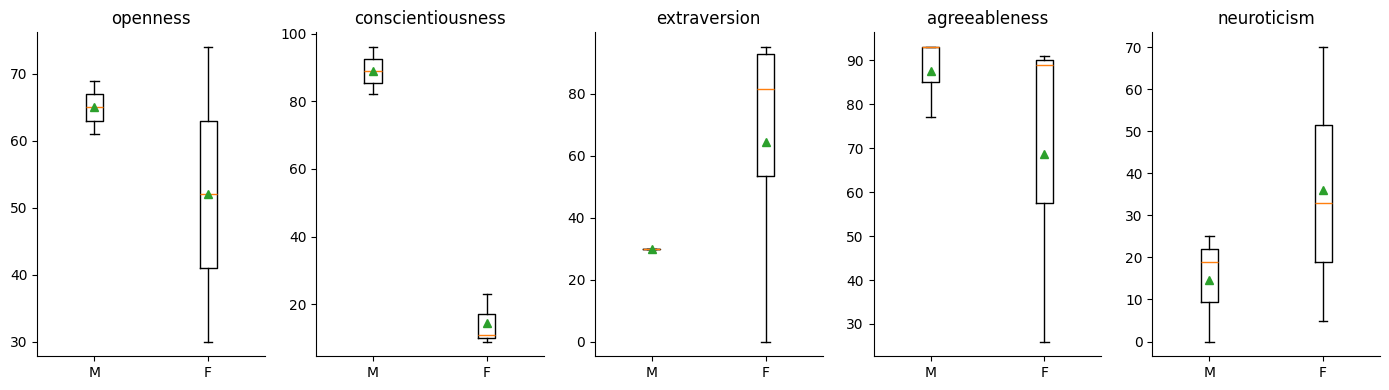

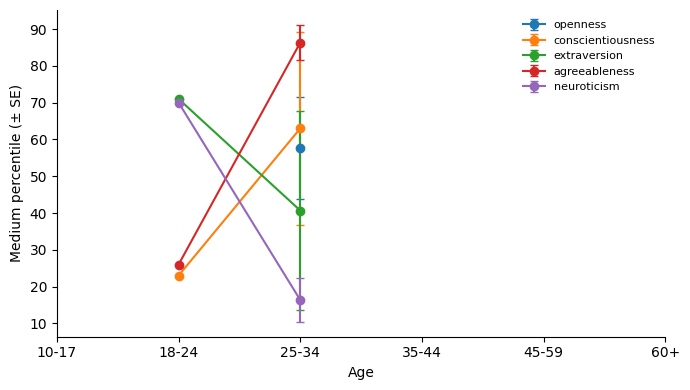

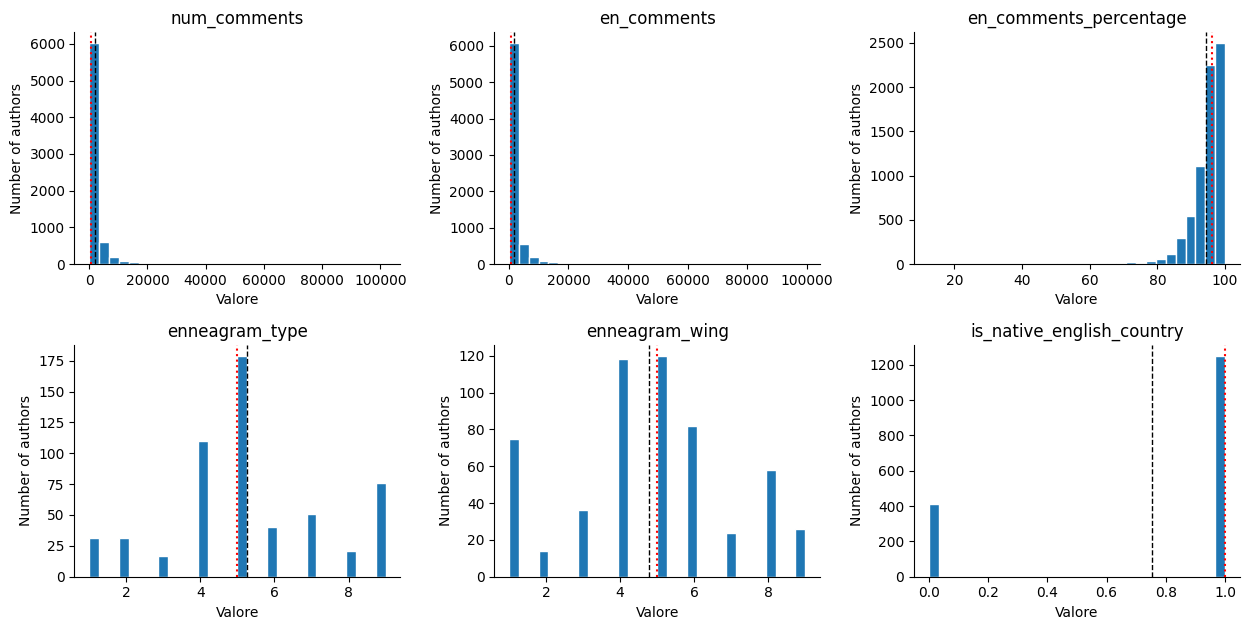

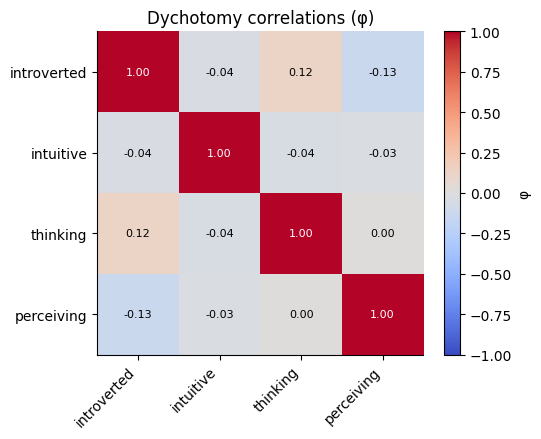

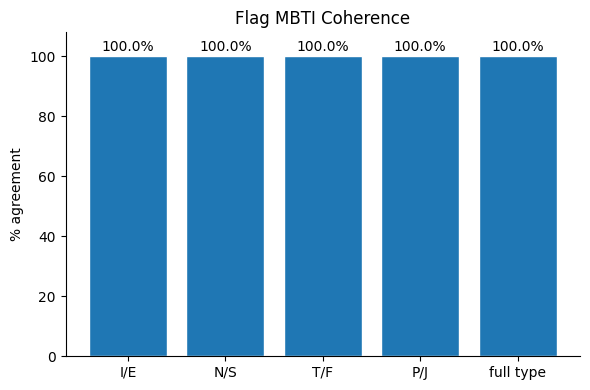

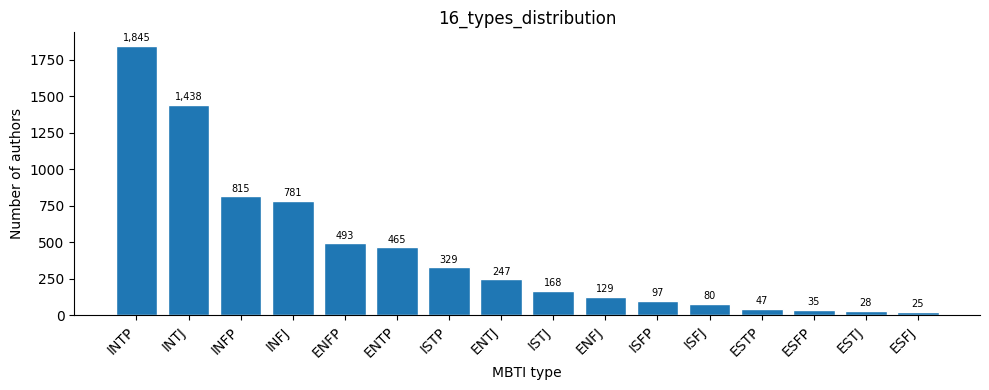

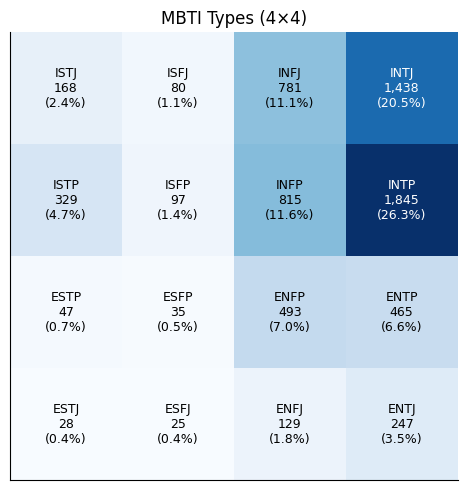

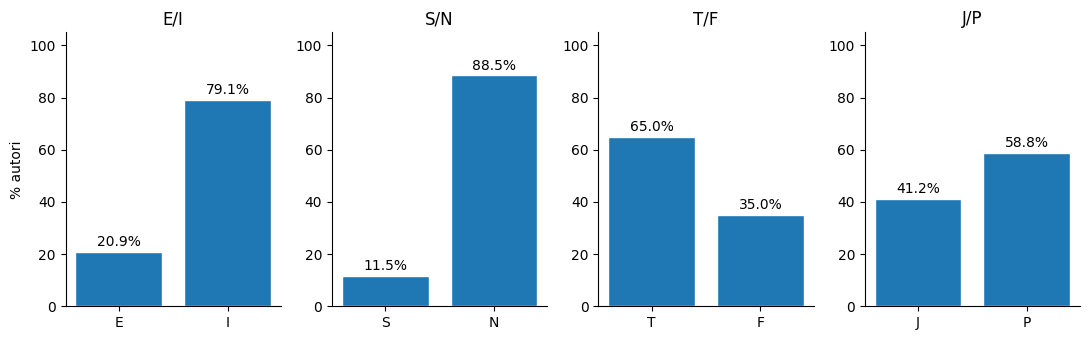

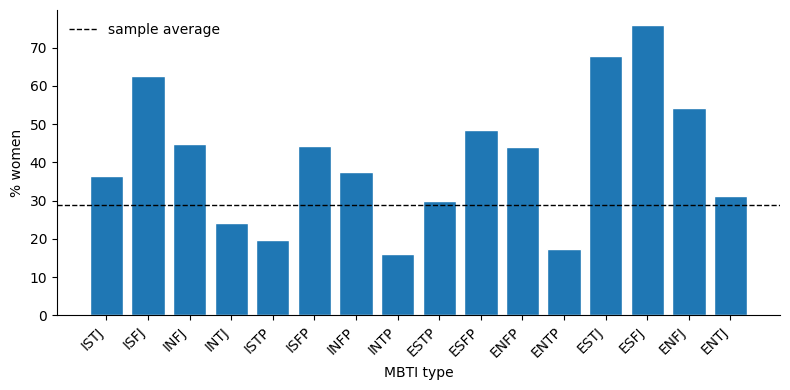

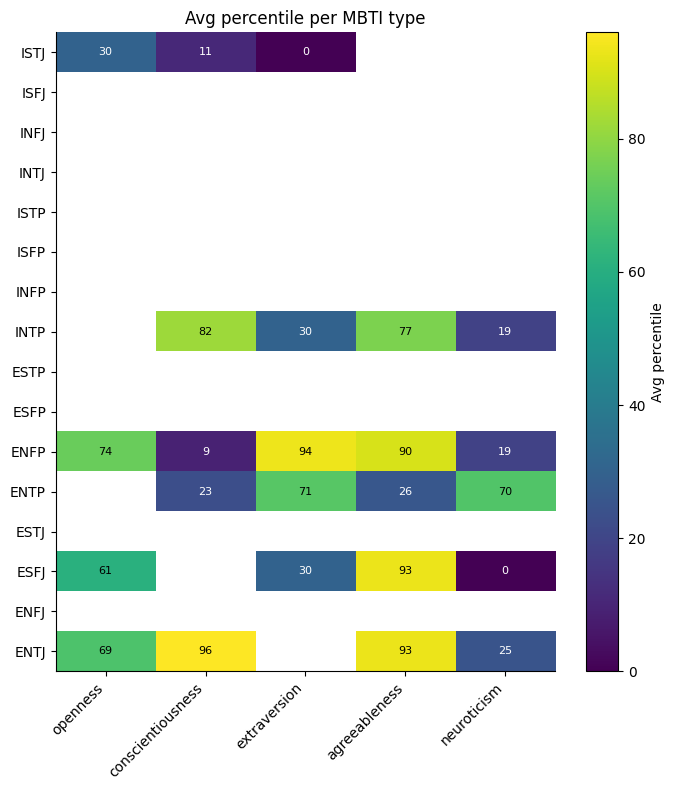

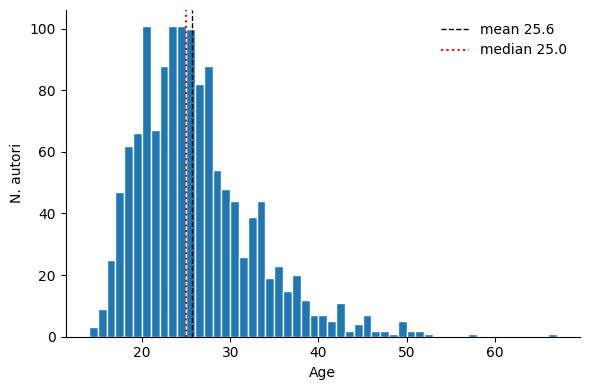

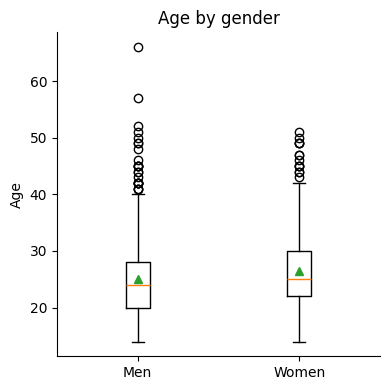

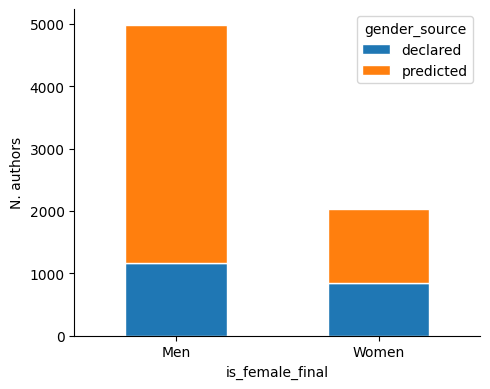

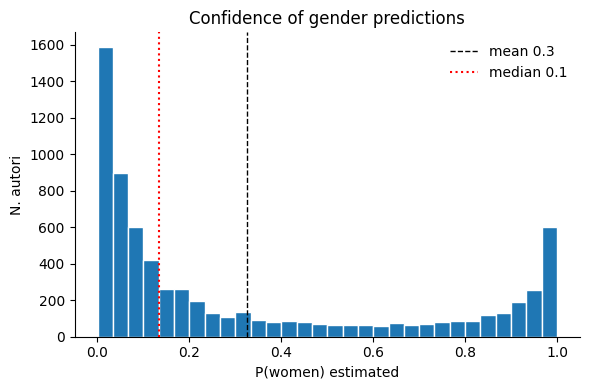

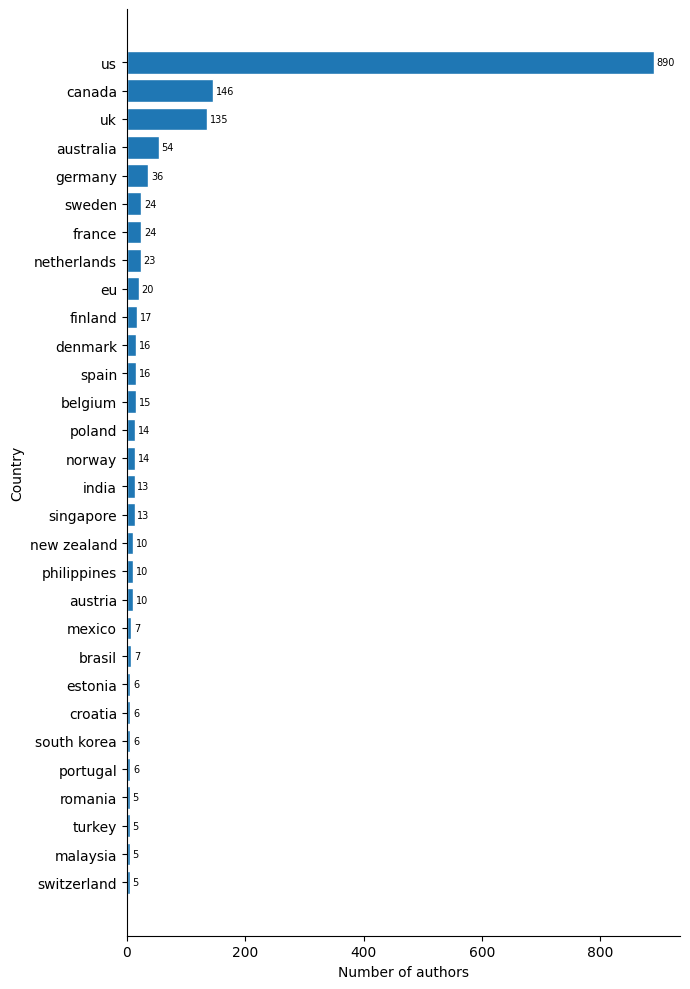

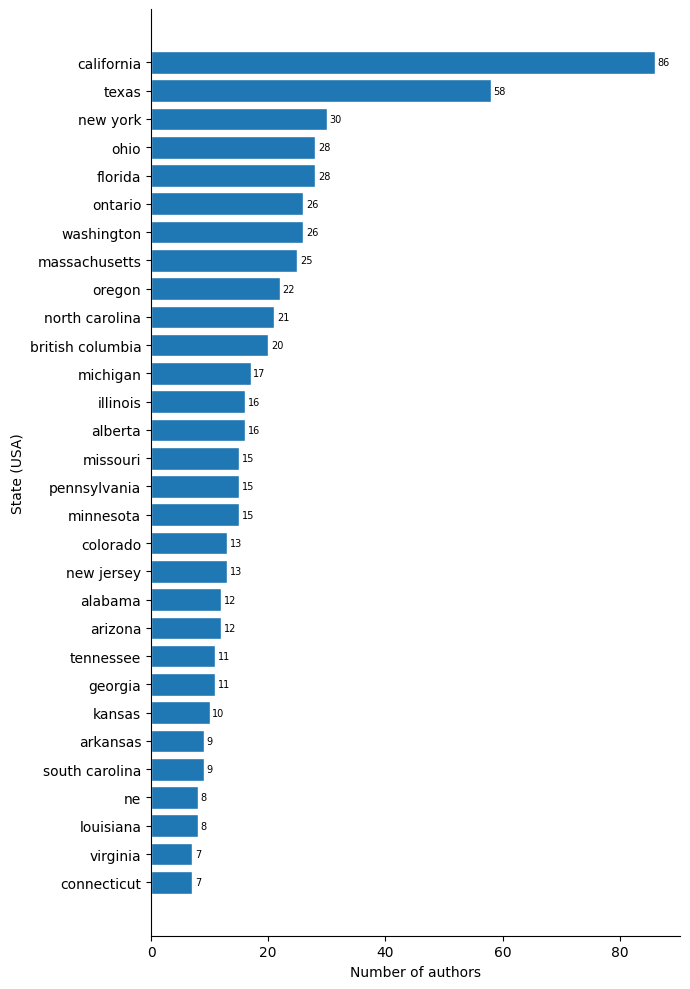

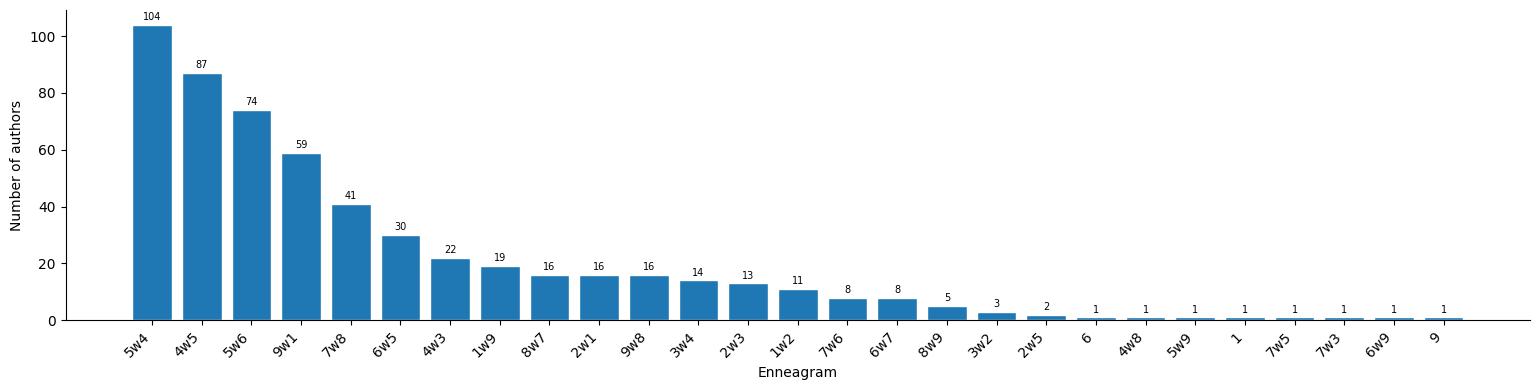

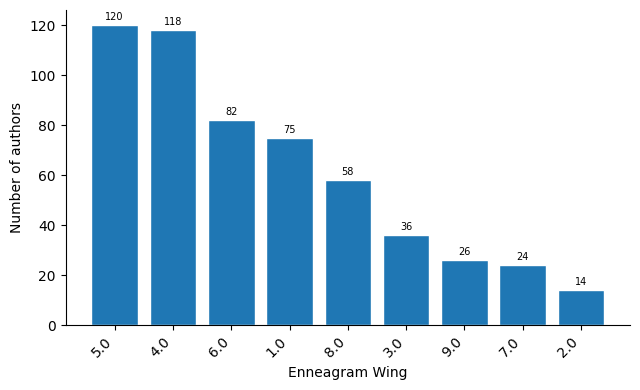

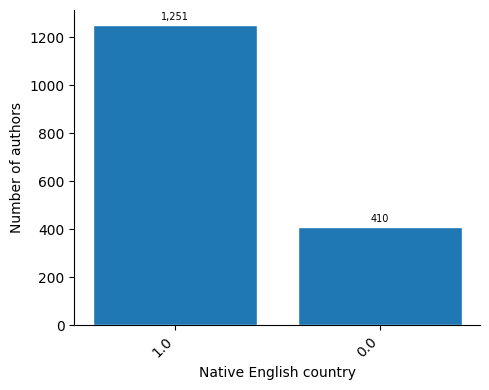

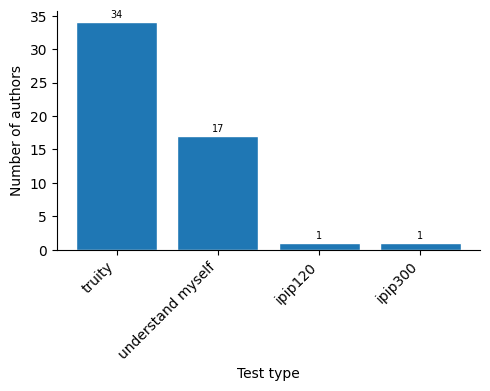

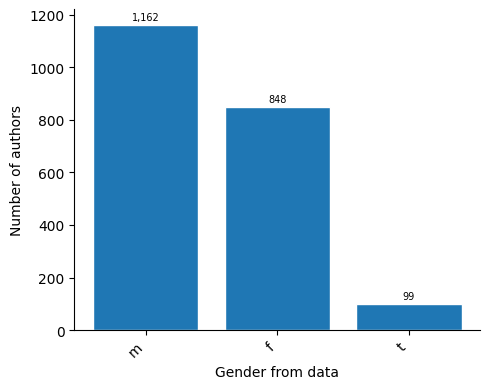

                         count      mean       std  min     5%      25%      50%       75%       95%        max   skew
n_comments              7022.0    642.35   1527.99  1.0   4.00    42.00   166.50    591.75   2818.50    34307.0   7.62
n_words_total           7022.0  22813.82  63021.79  1.0  96.05  1363.50  5474.50  19492.50  93424.95  1853869.0  10.95
mean_words_per_comment  7022.0     38.77     30.29  1.0  11.45    21.11    31.77     47.36     85.76      697.0   5.07
n_unique_subreddits     7022.0     48.53     59.99  1.0   2.00    11.00    29.00     63.00    161.95      719.0   3.17


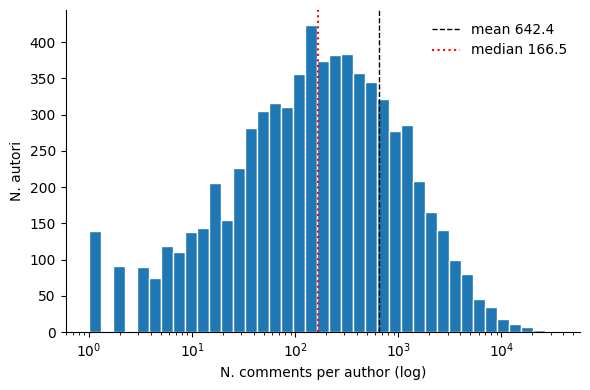

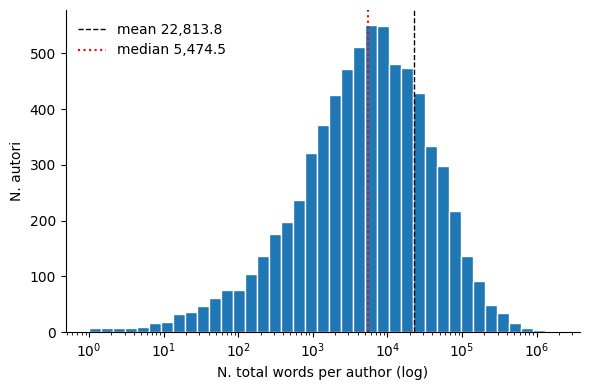

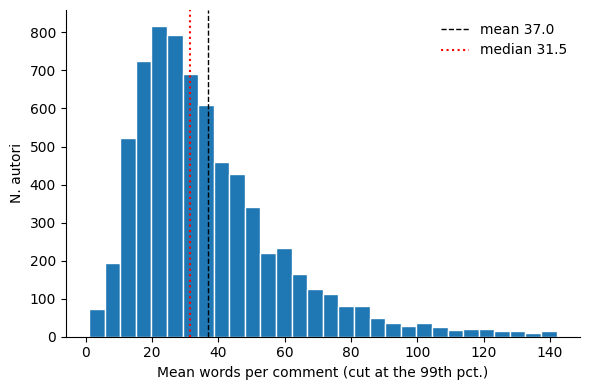

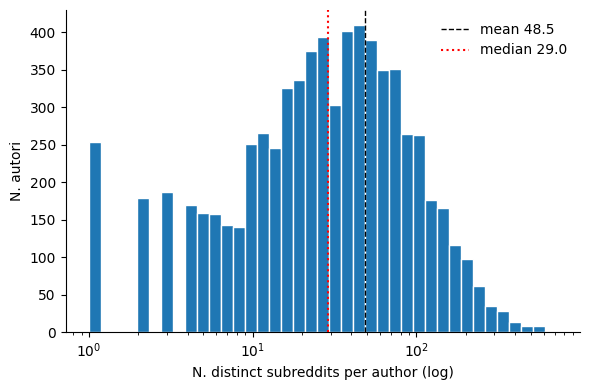

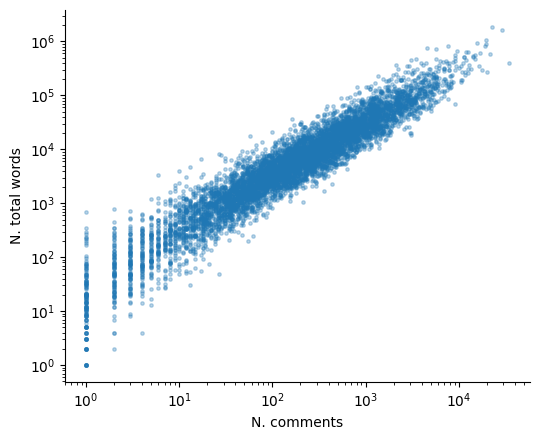

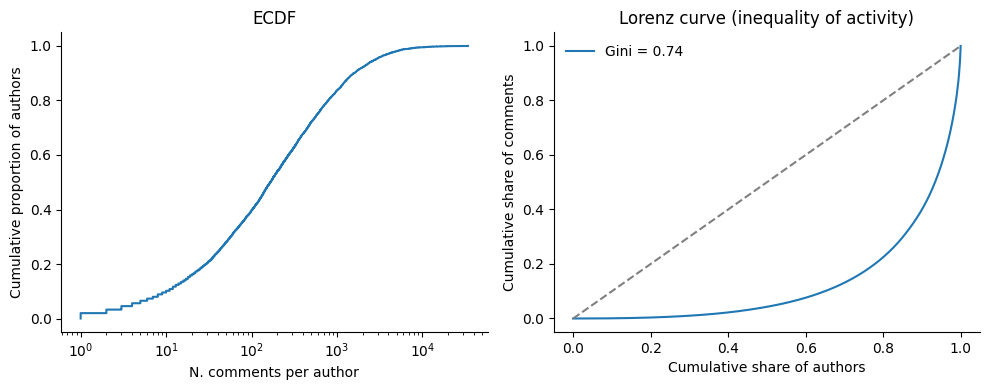

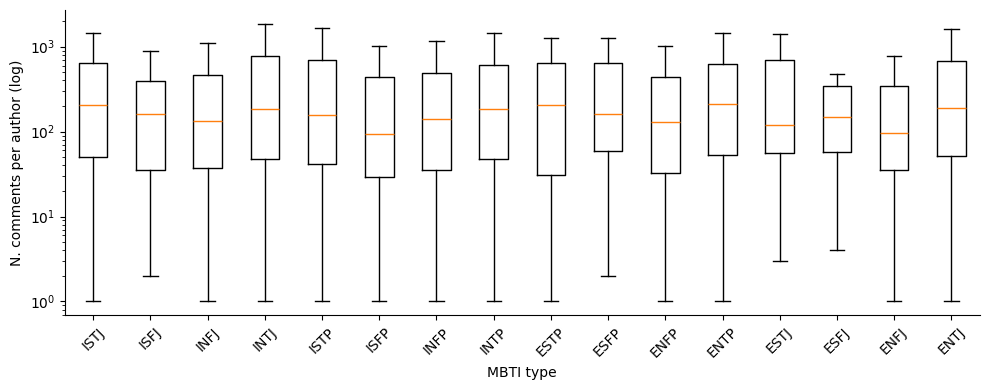

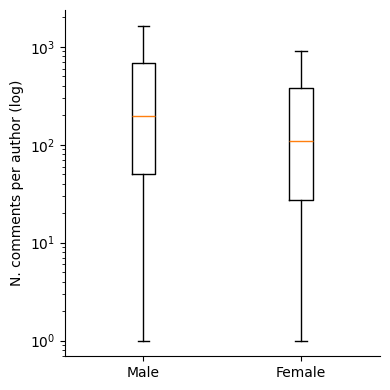

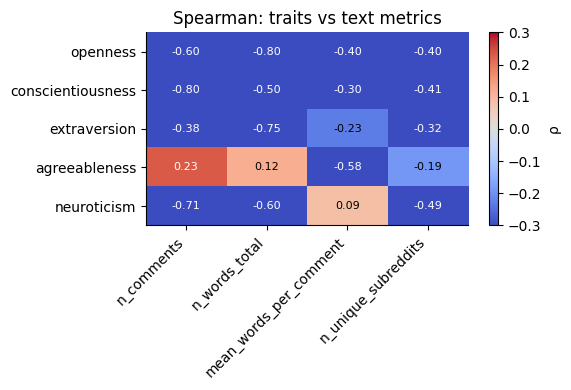

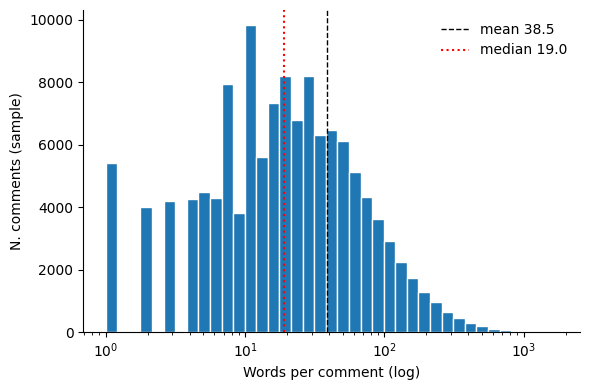

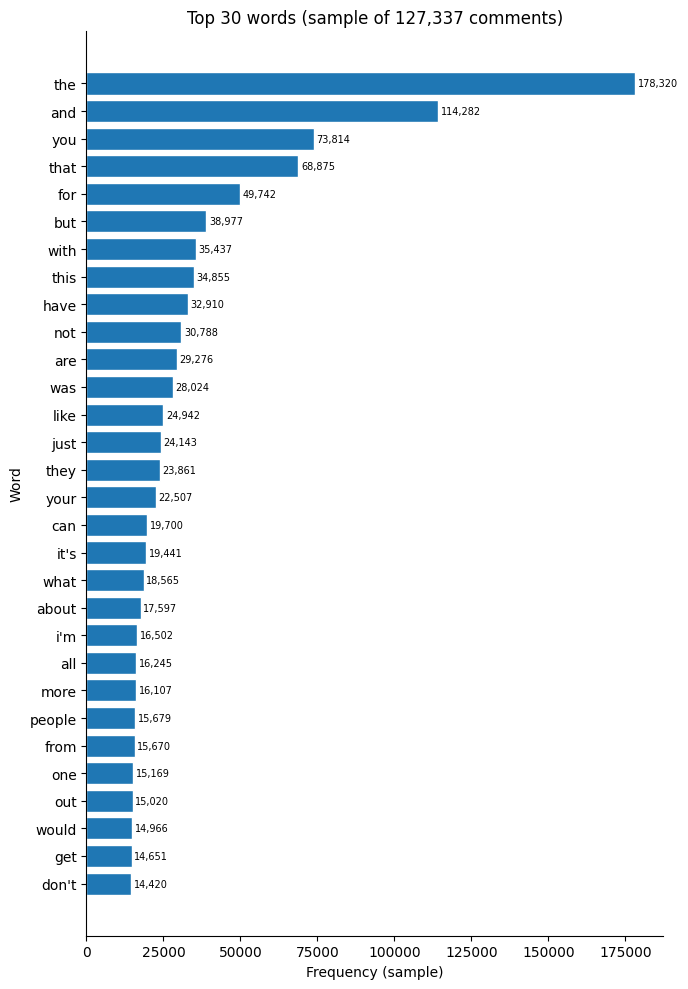

Distinct subreddits: 26,455 | share of the top 10: 14.9%


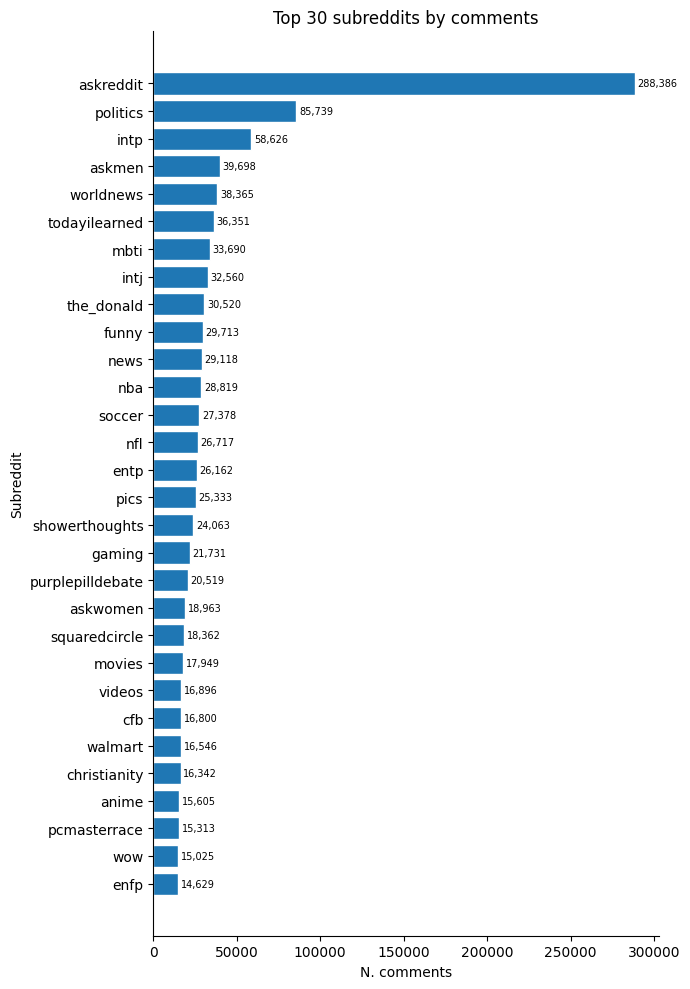

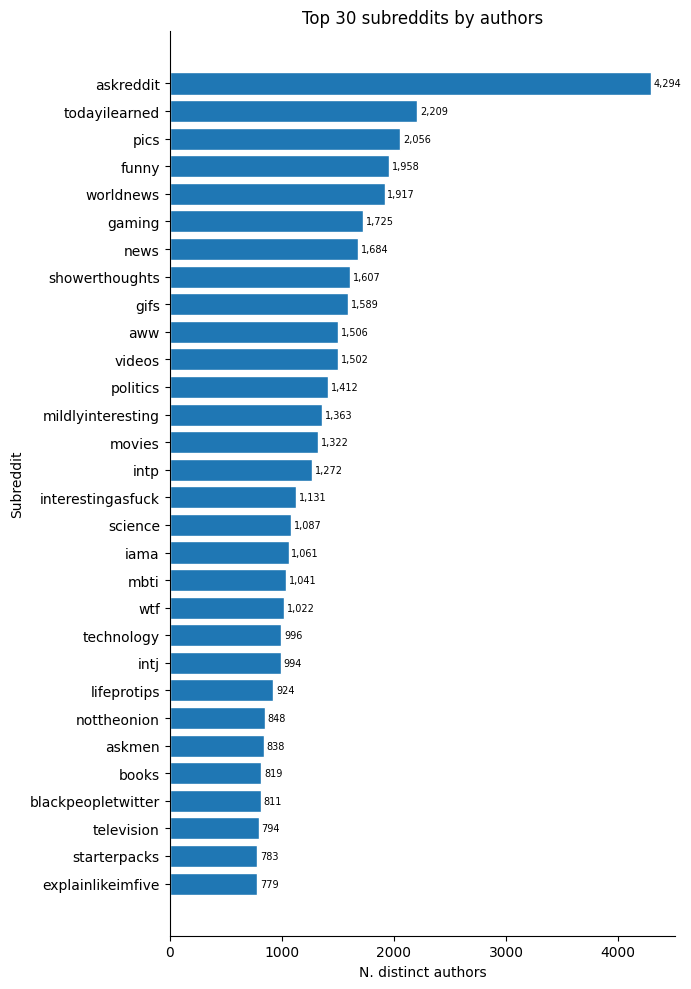

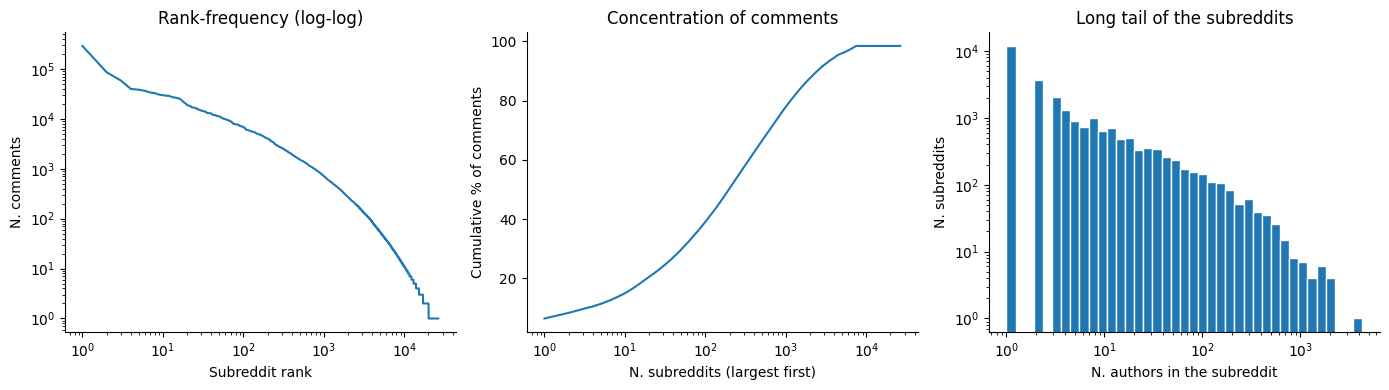

Comments in personality subreddits: 4.7% | authors with at least one: 55.6%


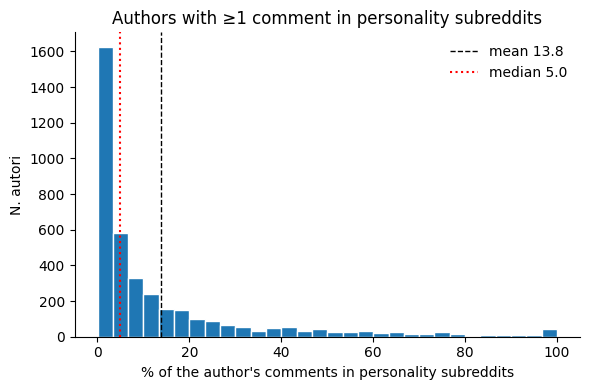

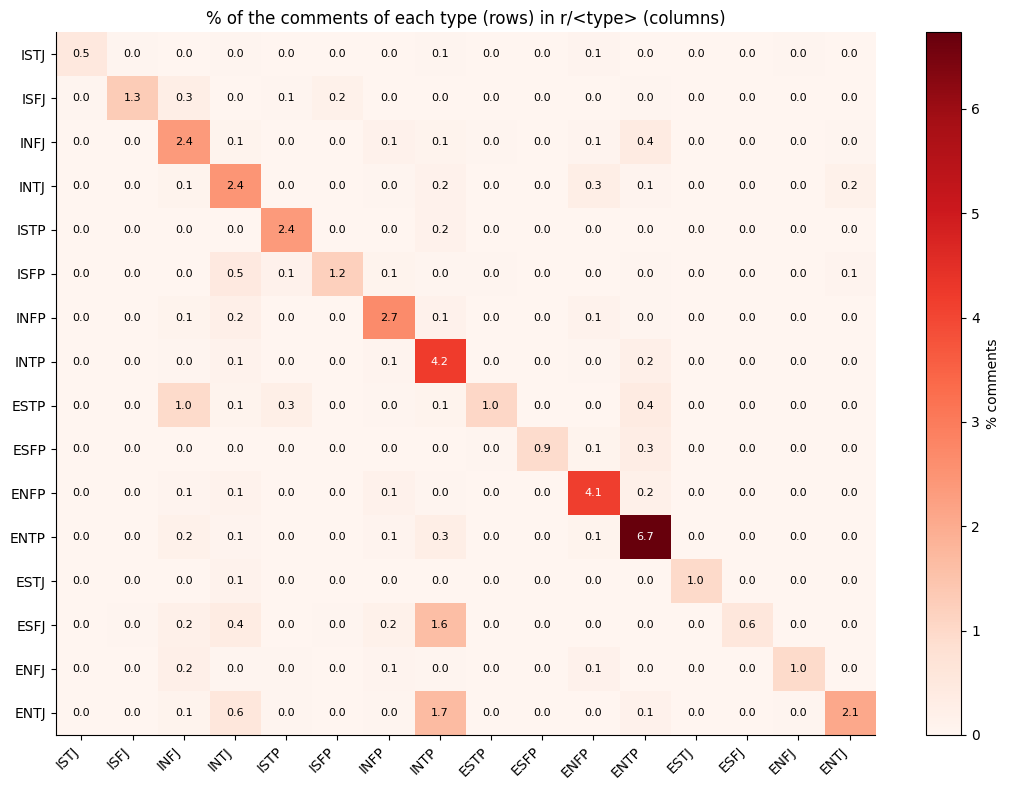

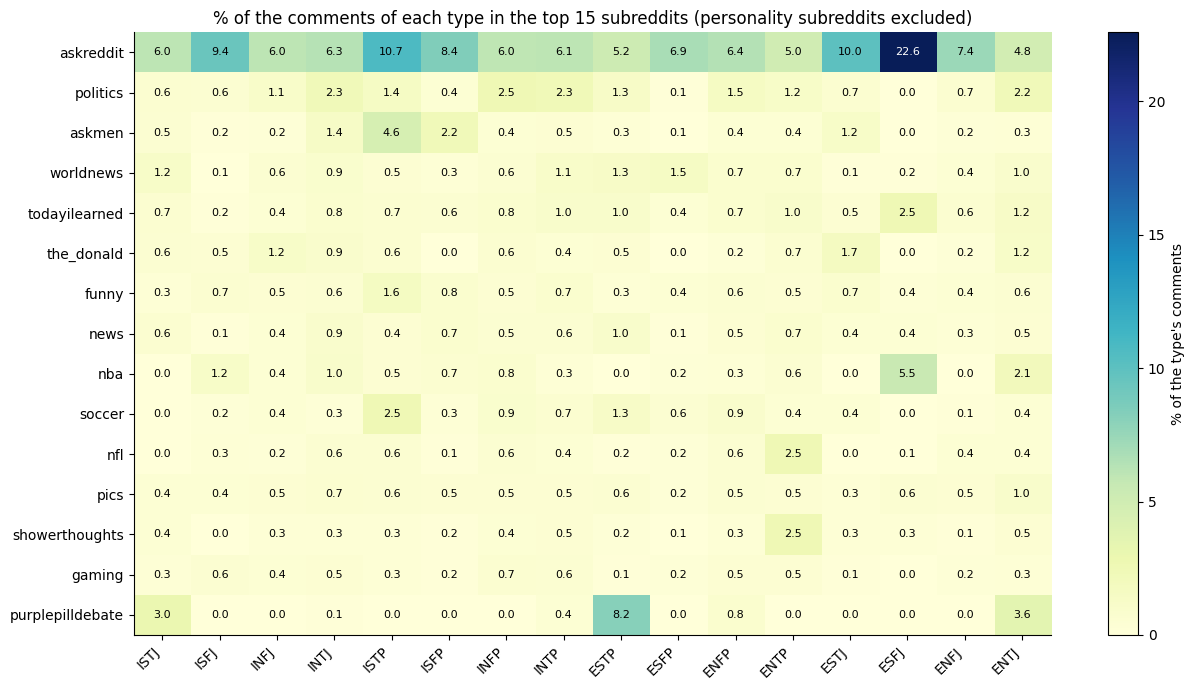

-> completed 'mbti_2': 7,022 authors
DATASET: final
/content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/final_dataset_commented.csv
Righe: 377 | Colonne: 40
Out of age range (10, 90): 0 -> NaN
                             dtype  n_missing  pct_missing  n_unique                                   example                                     advice
16pers_ta                   string        369        97.88       2.0                                         a  consider dropping (more than 90% missing)
region                      string        353        93.63       6.0                                        sw  consider dropping (more than 90% missing)
state                       string        352        93.37      12.0                                     texas  consider dropping (more than 90% missing)
is_description             float64        349        92.57       1.0                                       1.0                      DROP (empty/constant)
is_percentile              float64 

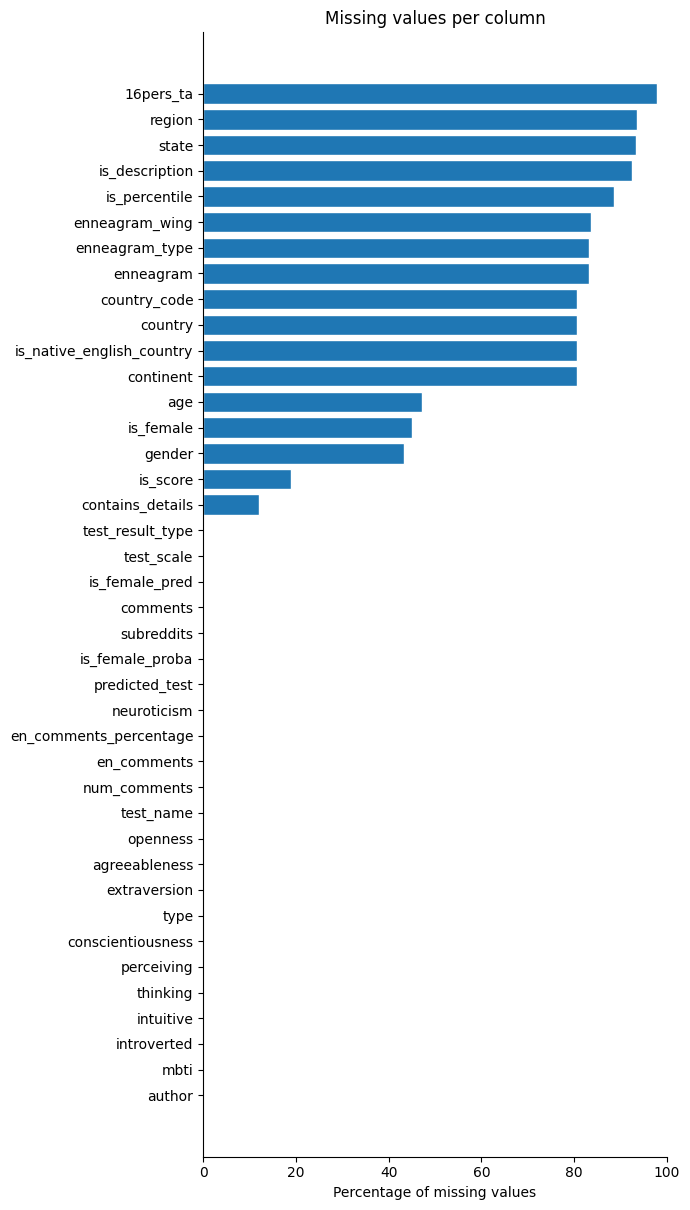

Dropped columns: ['is_description', 'is_percentile', 'is_score']
Traits: ['openness', 'conscientiousness', 'extraversion', 'agreeableness', 'neuroticism'] | MBTI flag: ['introverted', 'intuitive', 'thinking', 'perceiving']
Other numerical columns: ['contains_details', 'num_comments', 'en_comments', 'en_comments_percentage', 'enneagram_type', 'enneagram_wing', 'is_native_english_country']
Duplicates: 0
Declared gender vs predicted gender: 88.9% (n=207)
Missing or invalid MBTI: 0
Flag coherence by MBTI type:
 I/E          100.0
N/S          100.0
T/F          100.0
P/J          100.0
full type    100.0
MBTI type obtained by flags for 0 authors
Authors with more comments than subreddits: 0
Authors with less than 1 commens have been removed: 0
                                 openness             conscientiousness             extraversion             agreeableness             neuroticism            
                                    count   min   max             count   min   max        

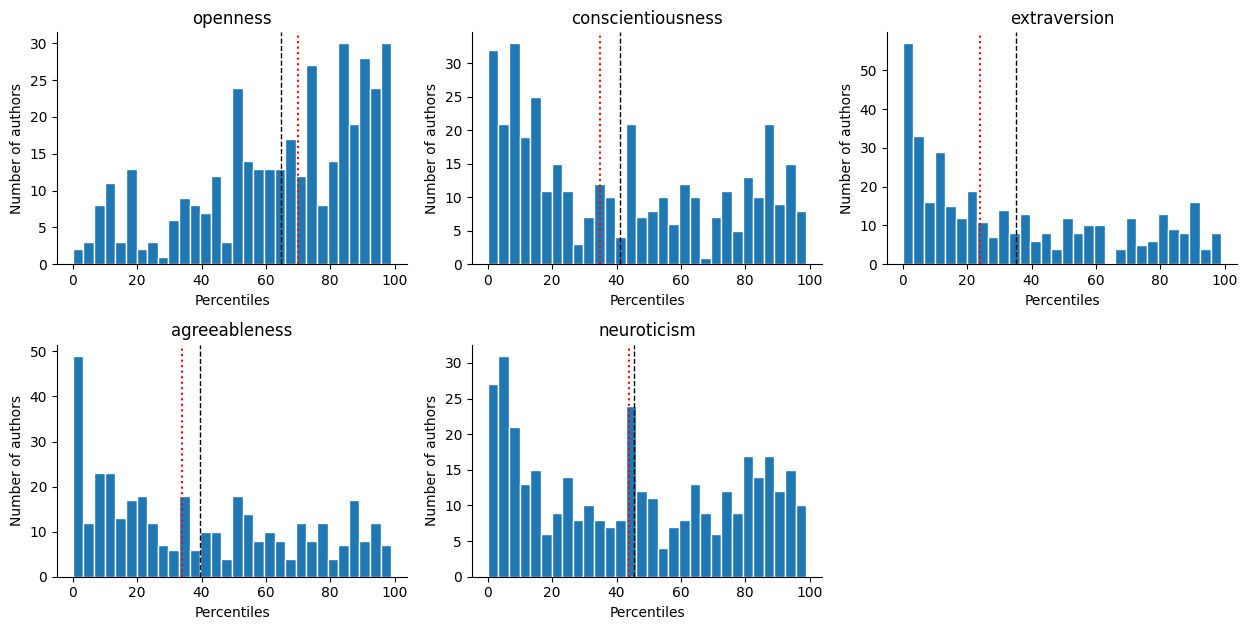

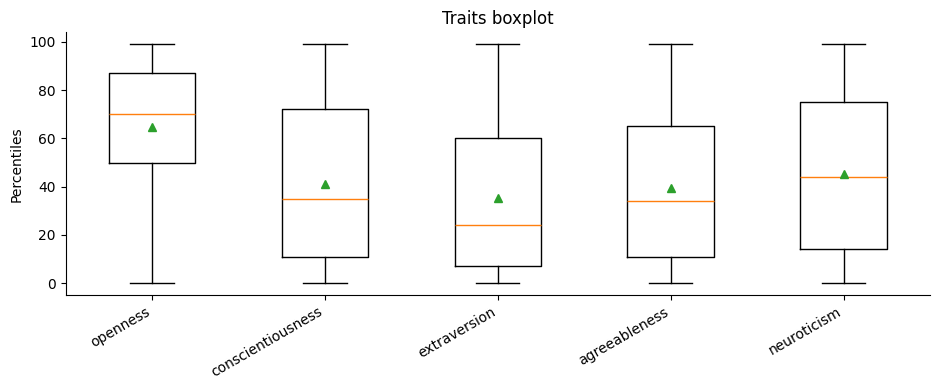

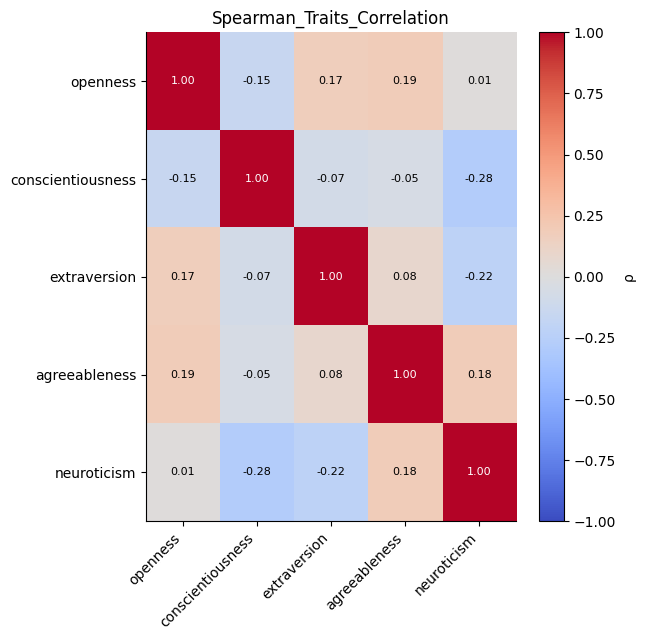

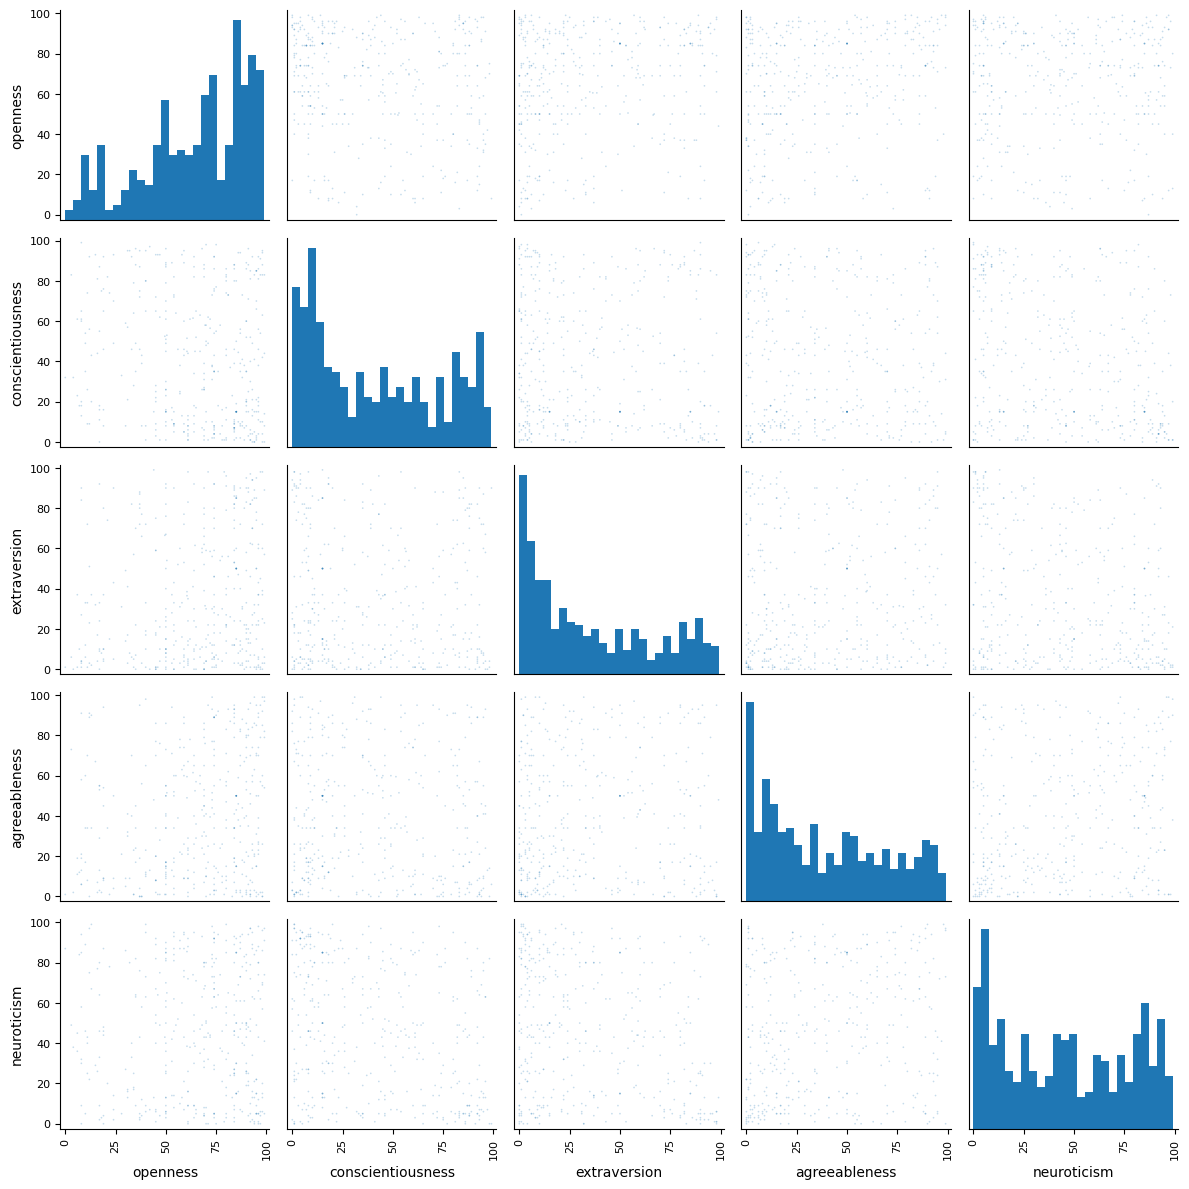

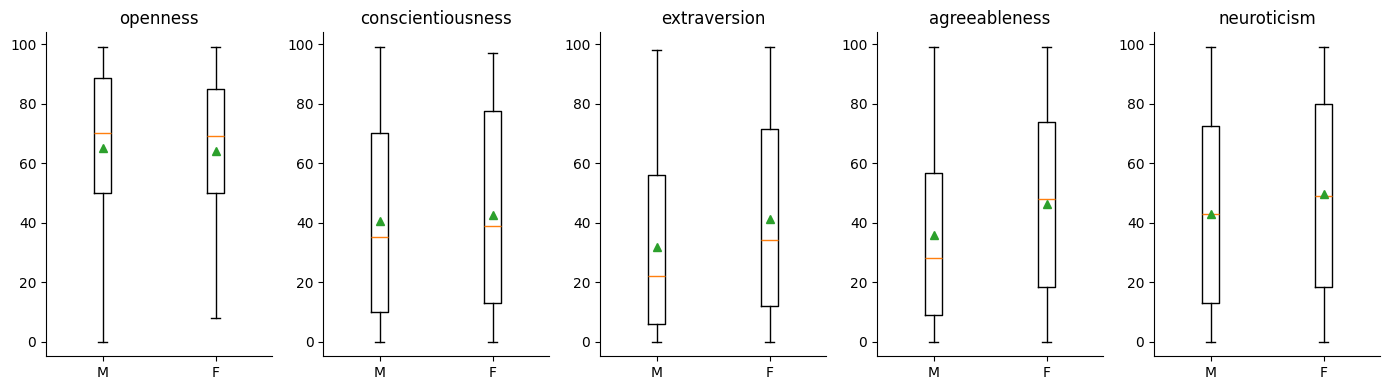

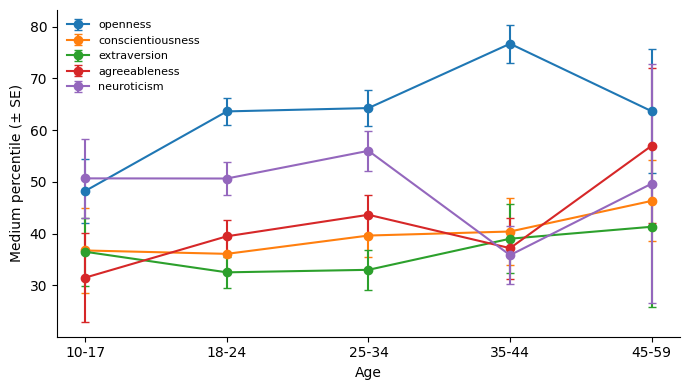

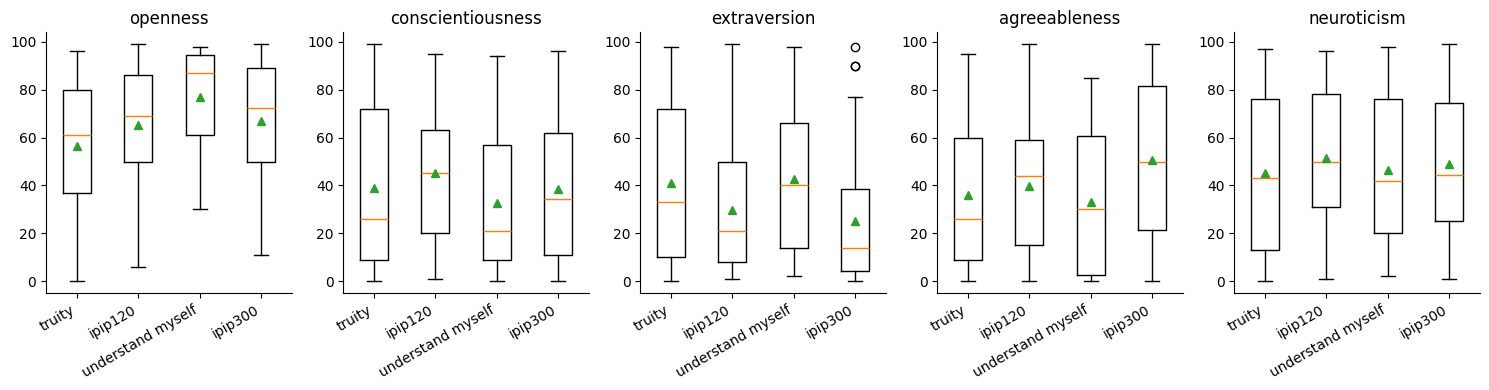

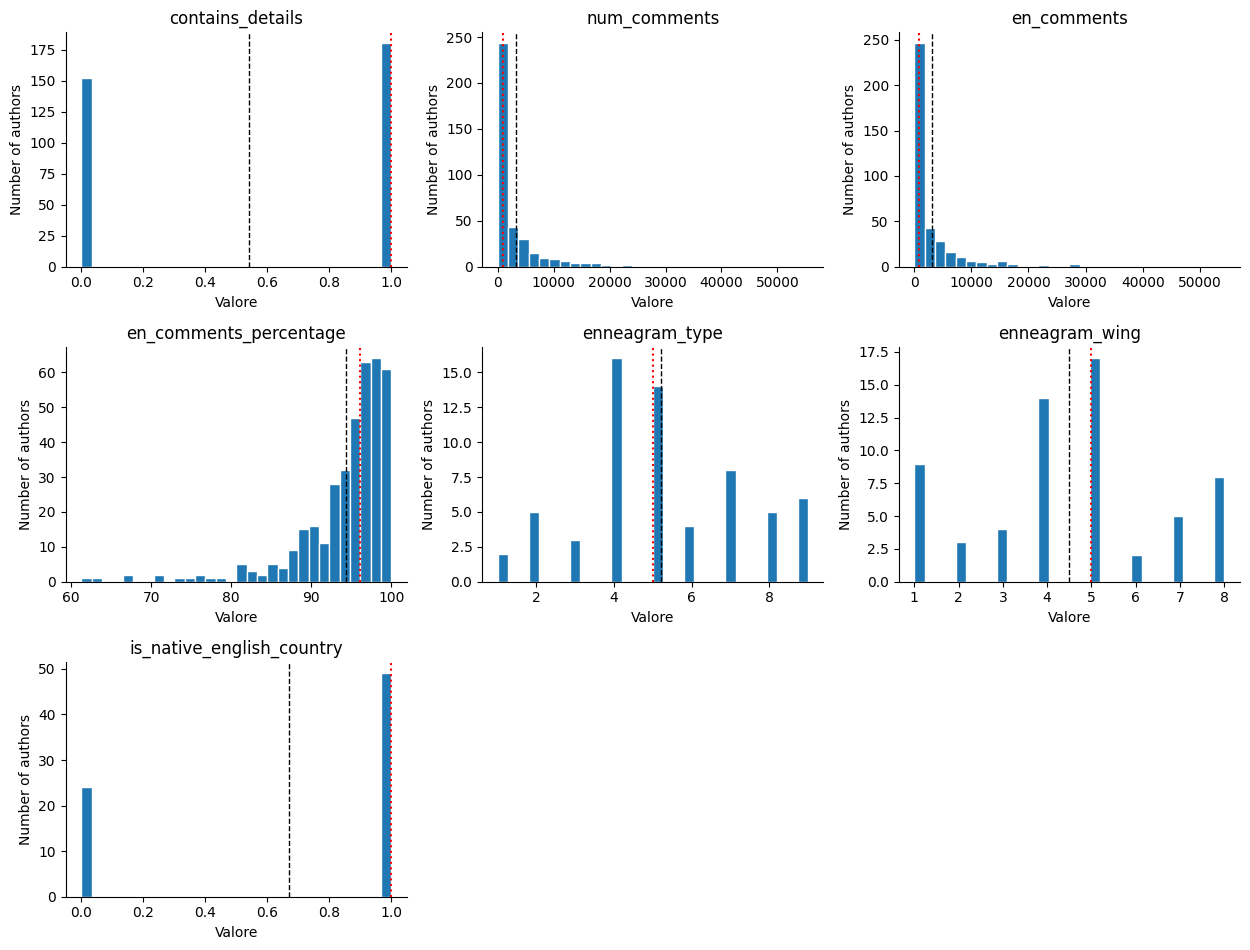

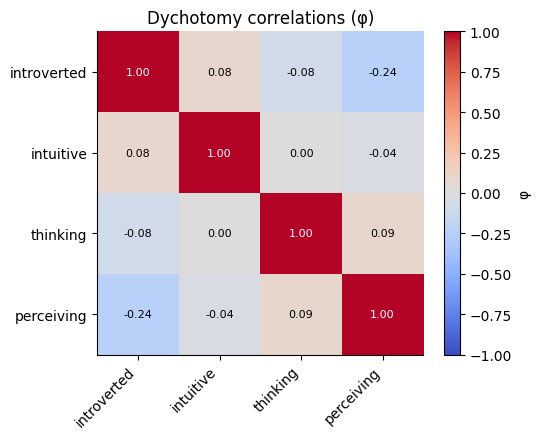

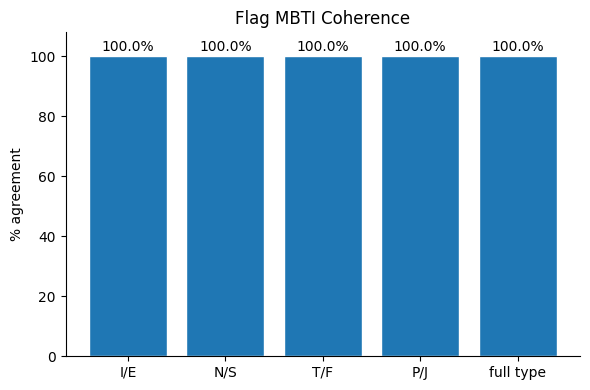

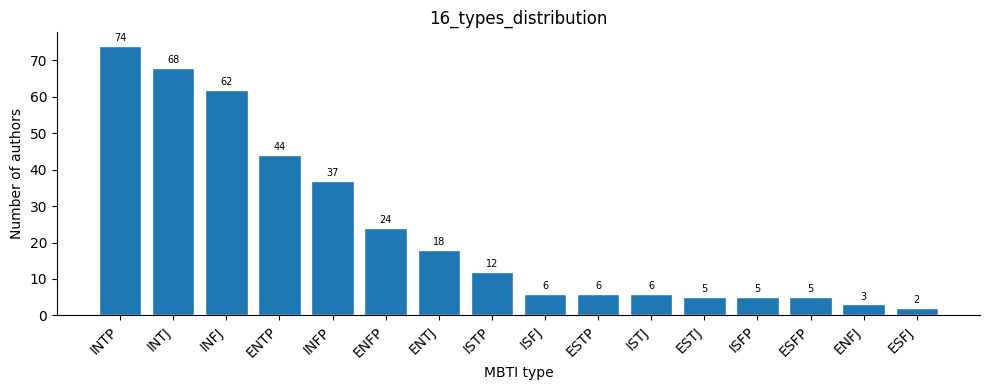

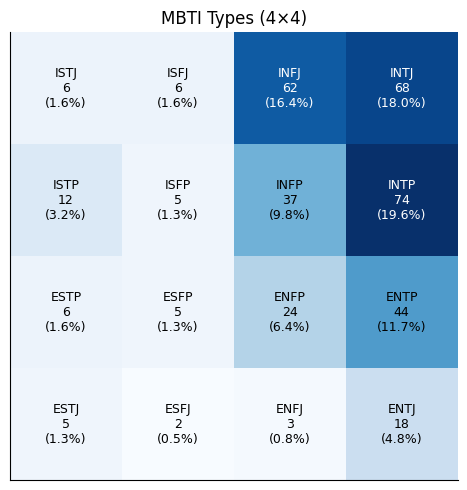

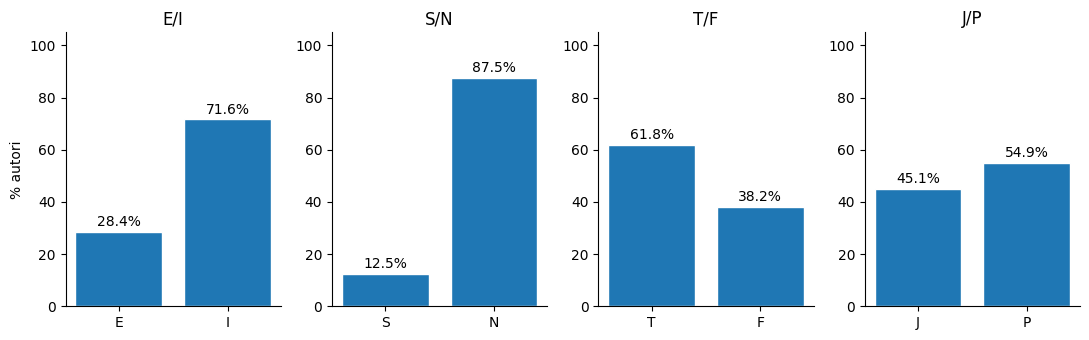

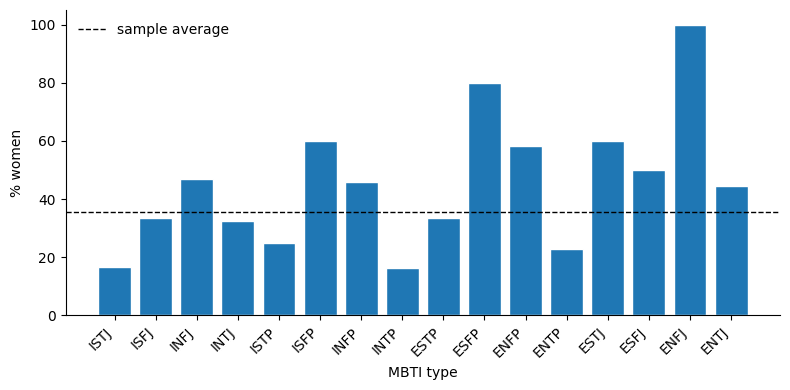

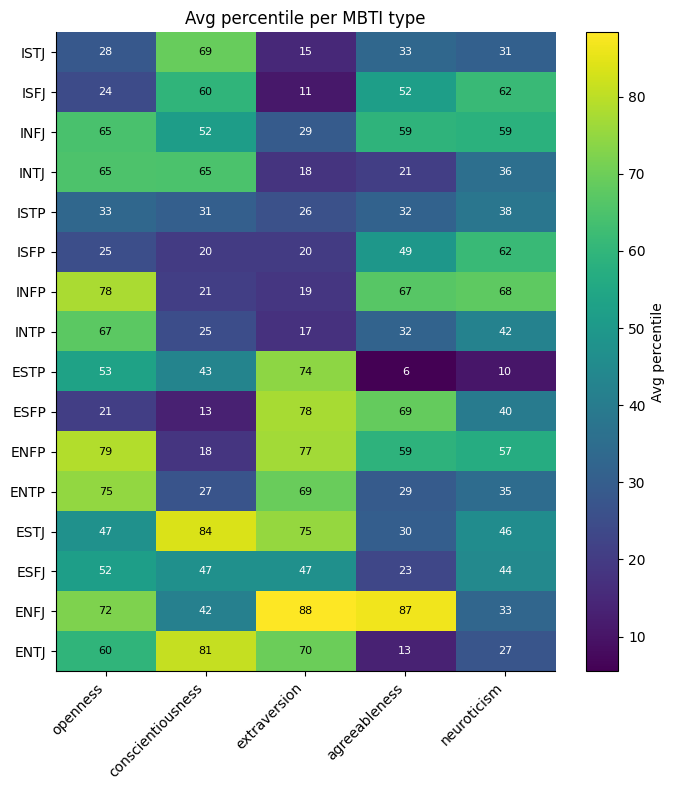

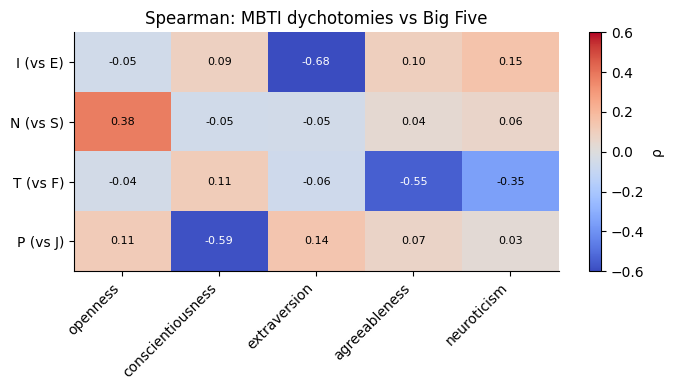

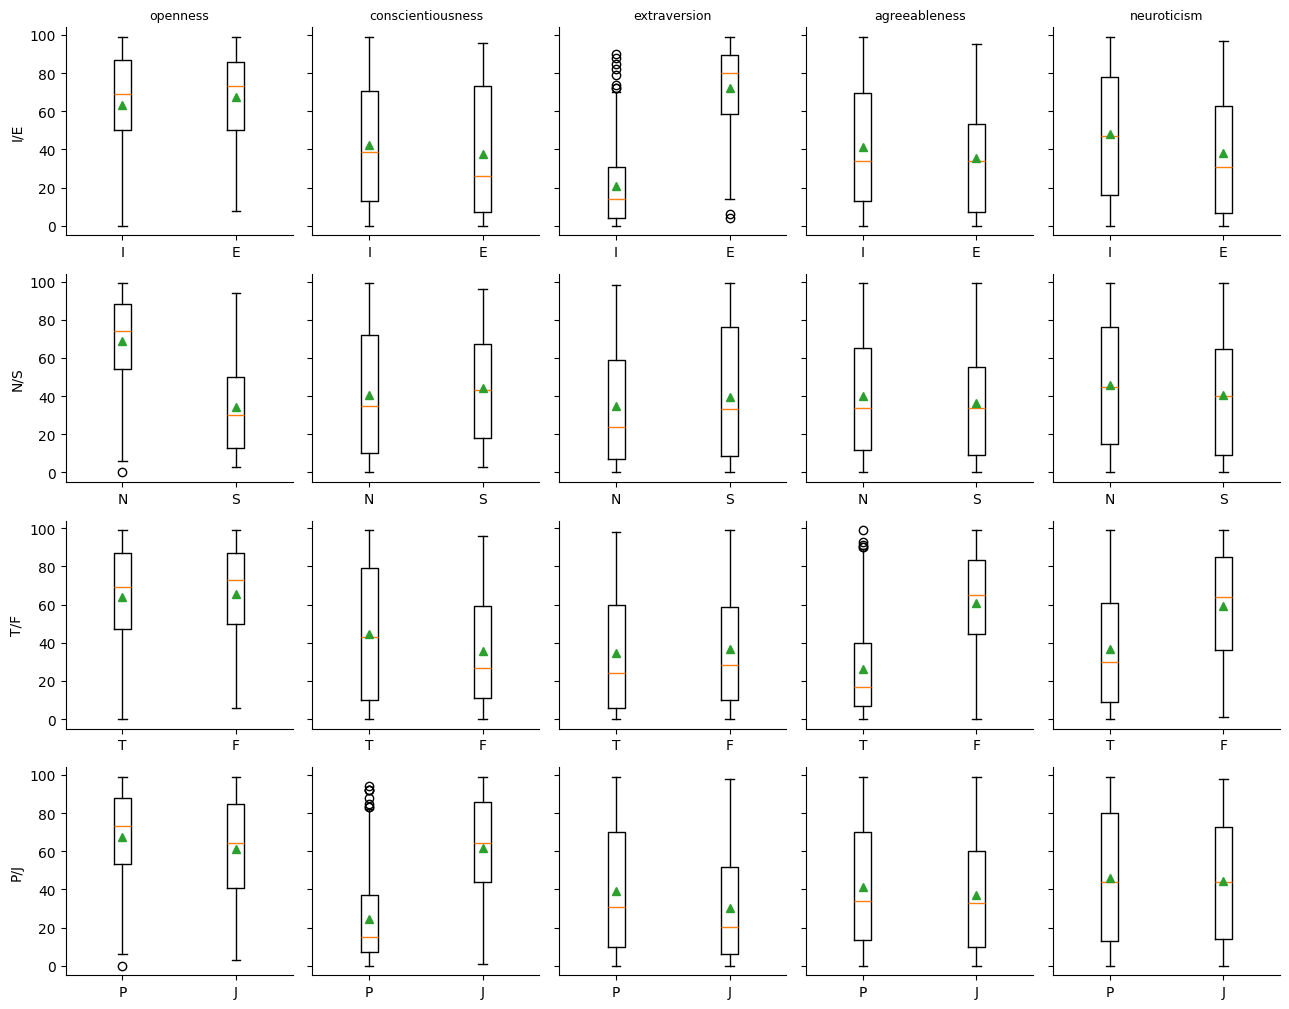

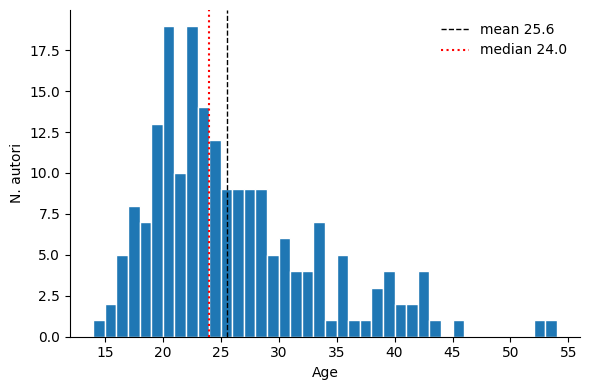

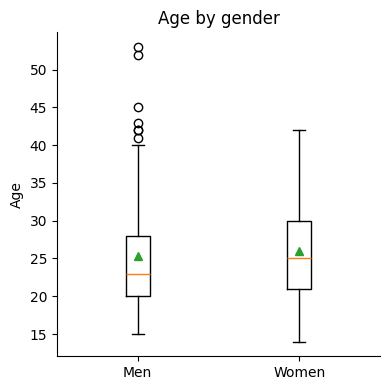

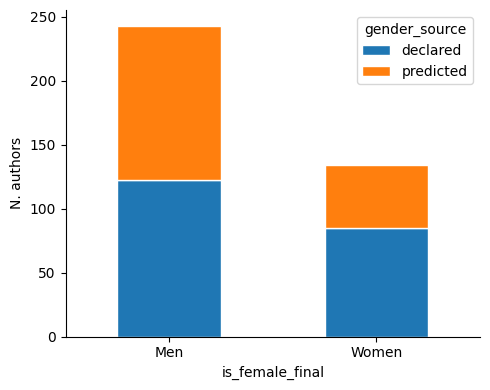

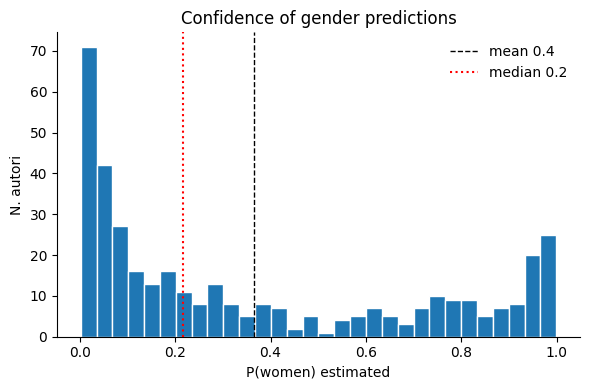

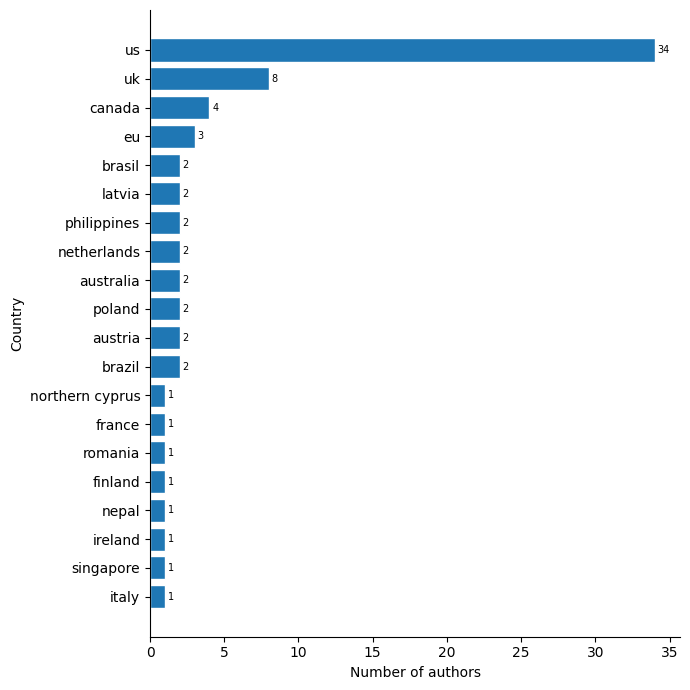

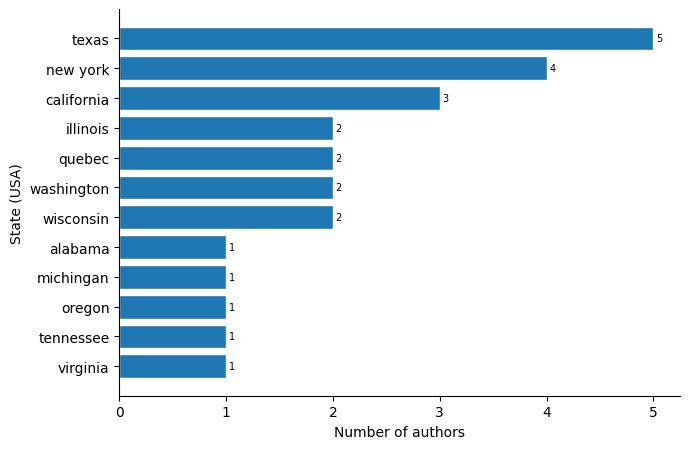

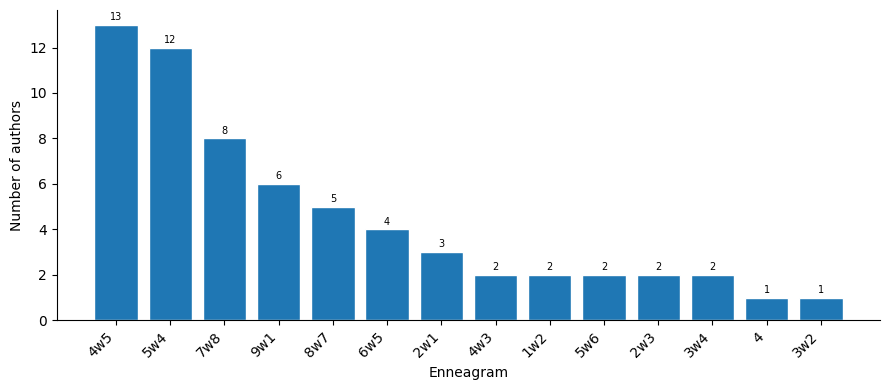

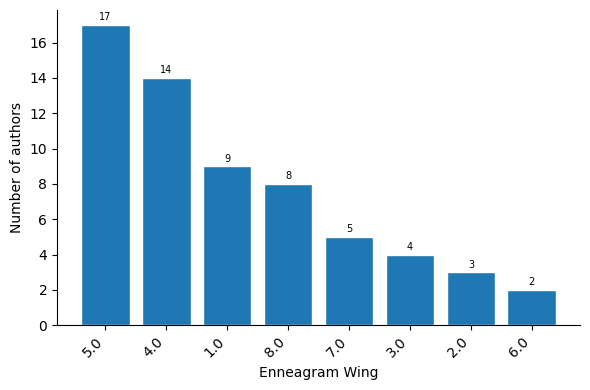

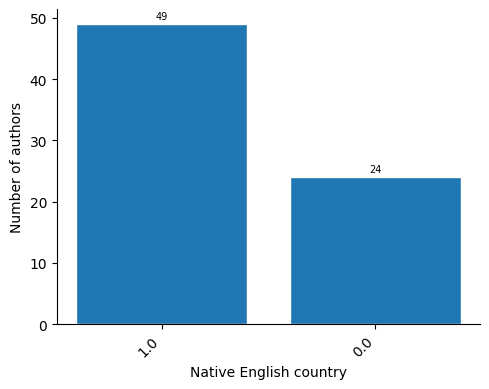

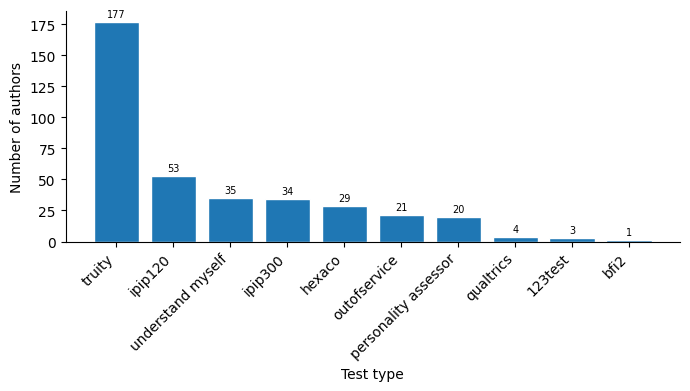

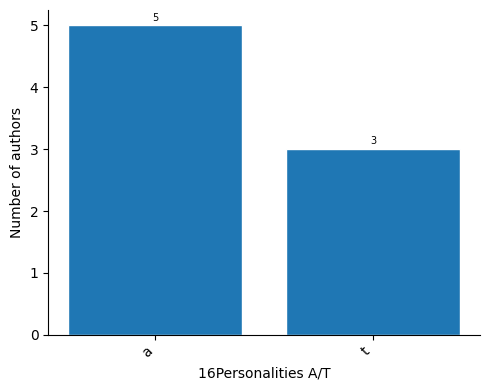

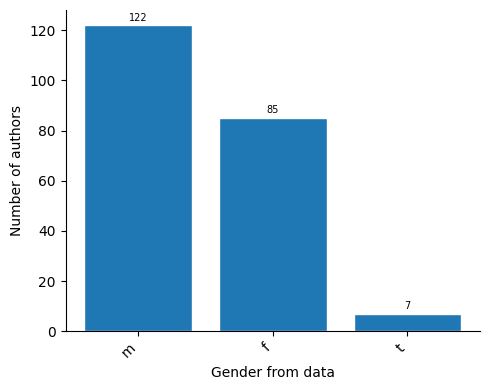

                        count       mean        std    min       5%      25%       50%        75%        95%         max  skew
n_comments              377.0    2772.88    5575.37   1.00    21.80   180.00    727.00    2899.00   11082.00    44989.00  4.47
n_words_total           377.0  114585.06  223451.00  11.00  1315.20  6742.00  30800.00  110876.00  513024.20  1981404.00  3.98
mean_words_per_comment  377.0      47.21      31.63   7.39    14.13    27.57     40.03      57.58     102.44      340.42  3.12
n_unique_subreddits     377.0      73.48      88.89   1.00     4.00    18.00     41.00      92.00     262.20      674.00  2.55


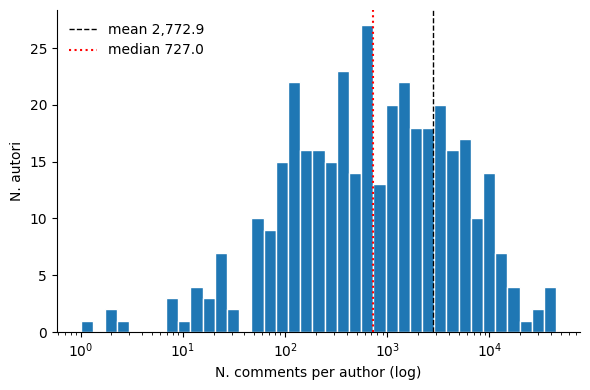

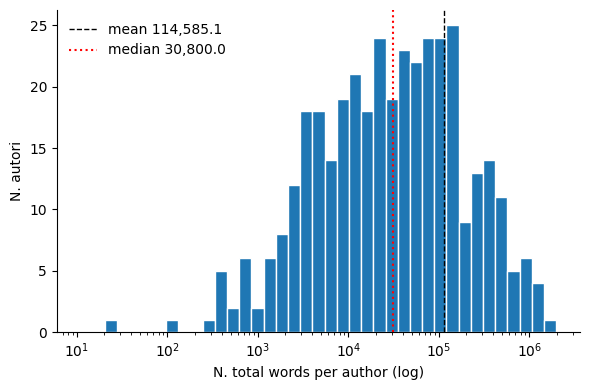

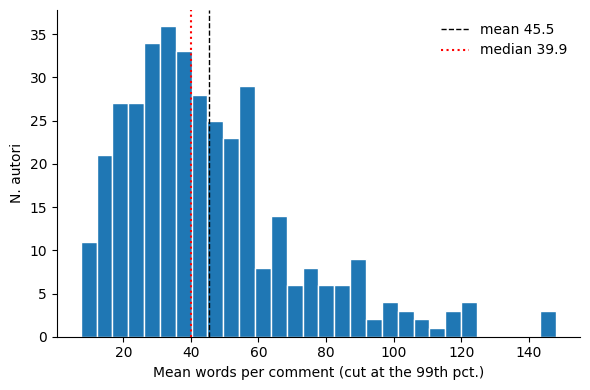

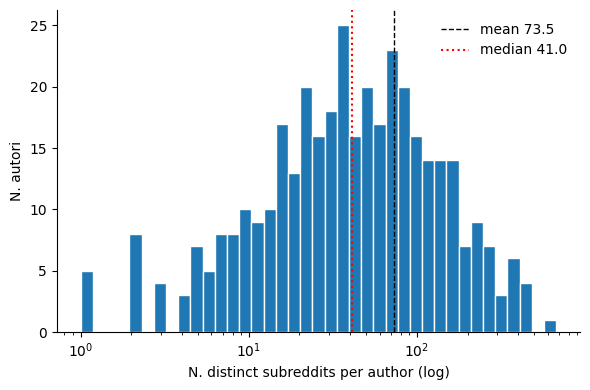

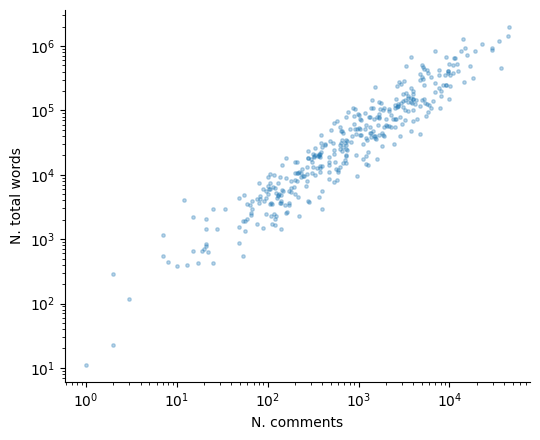

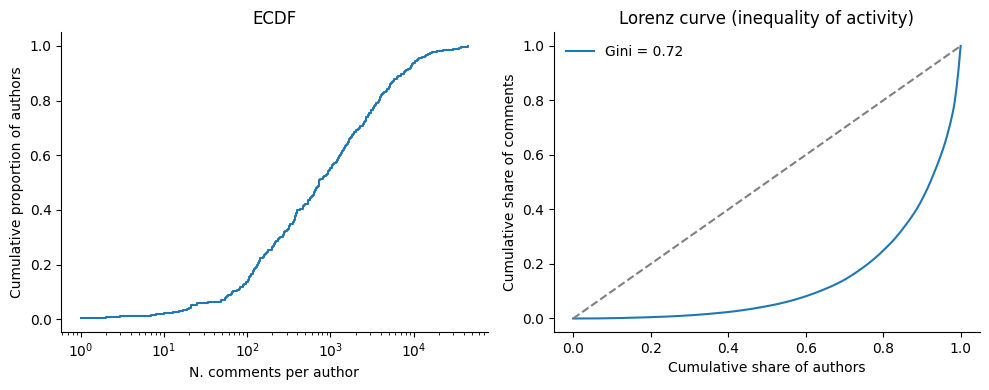

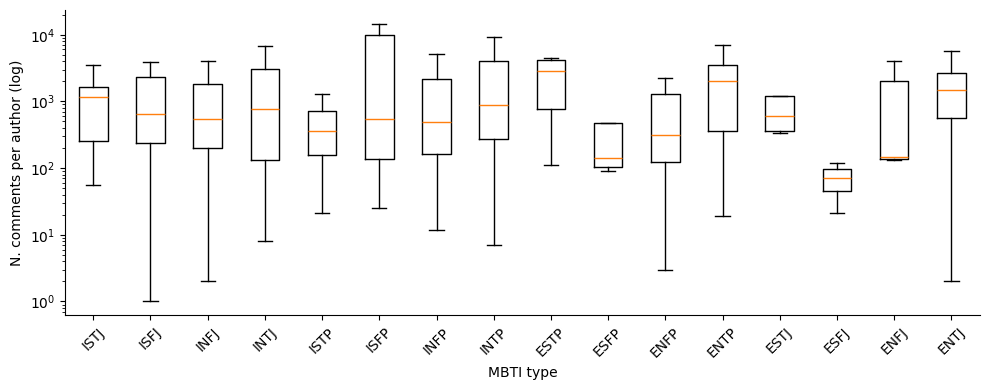

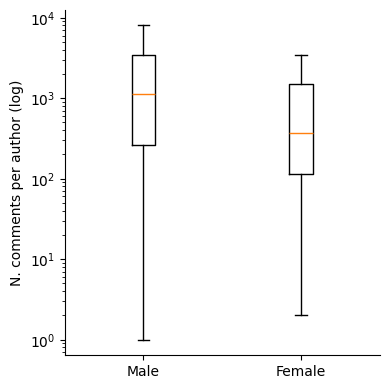

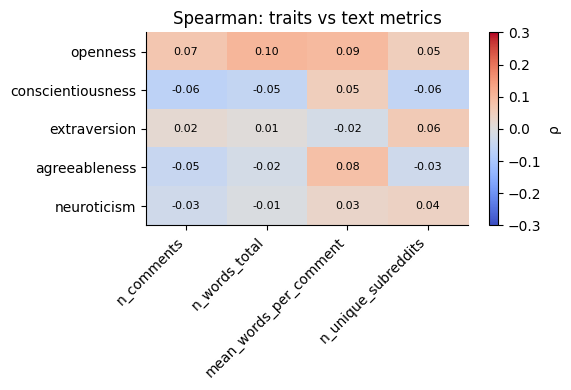

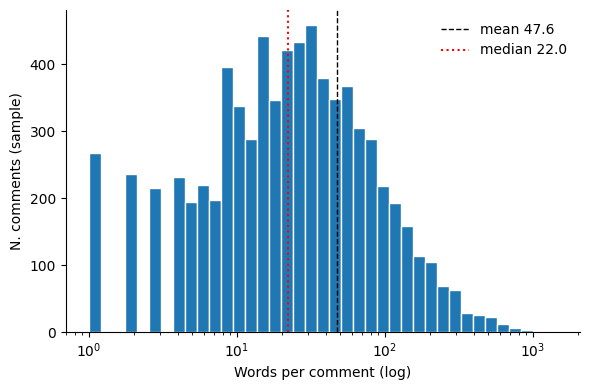

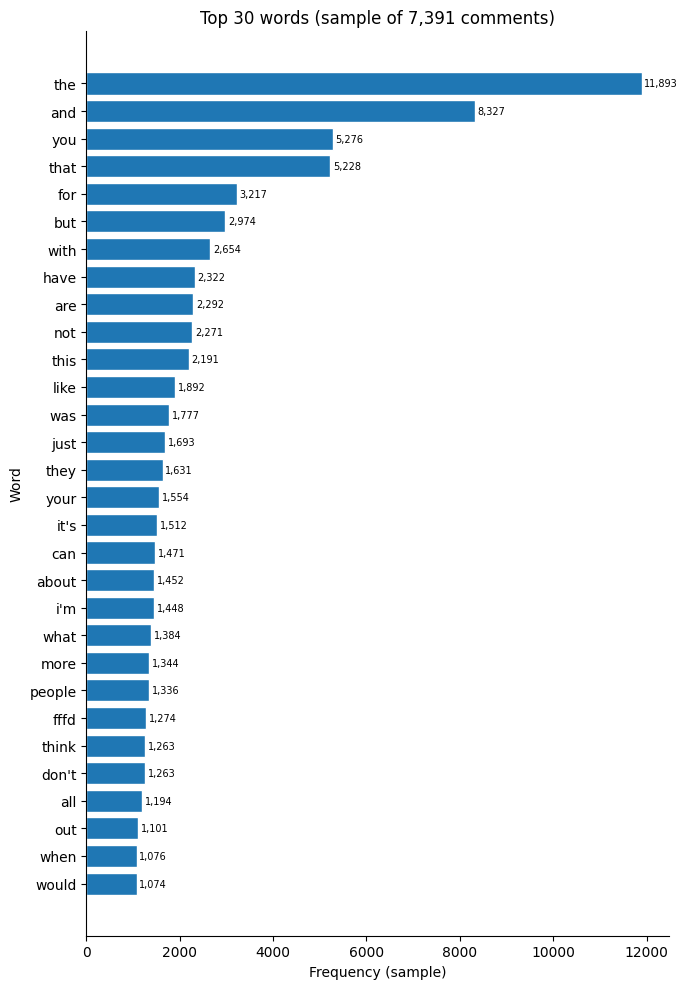

Distinct subreddits: 7,766 | share of the top 10: 34.2%


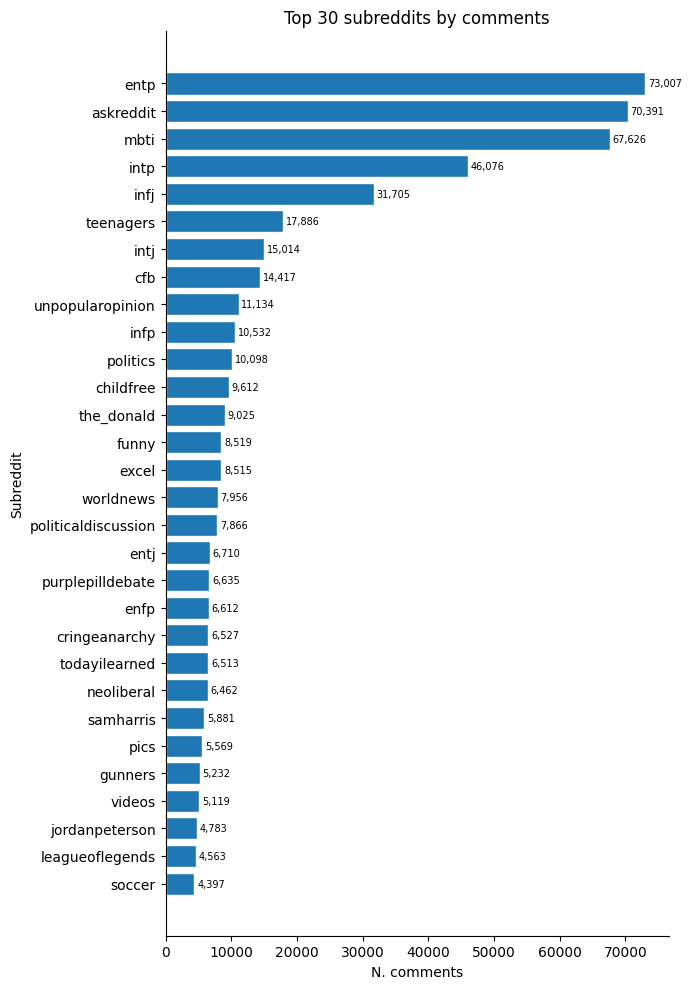

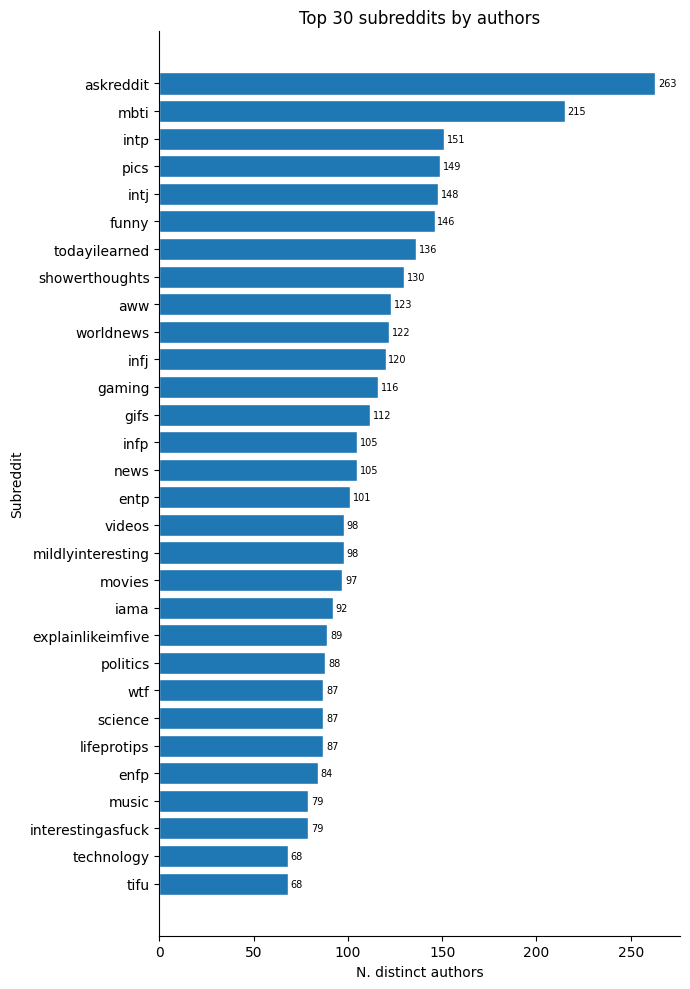

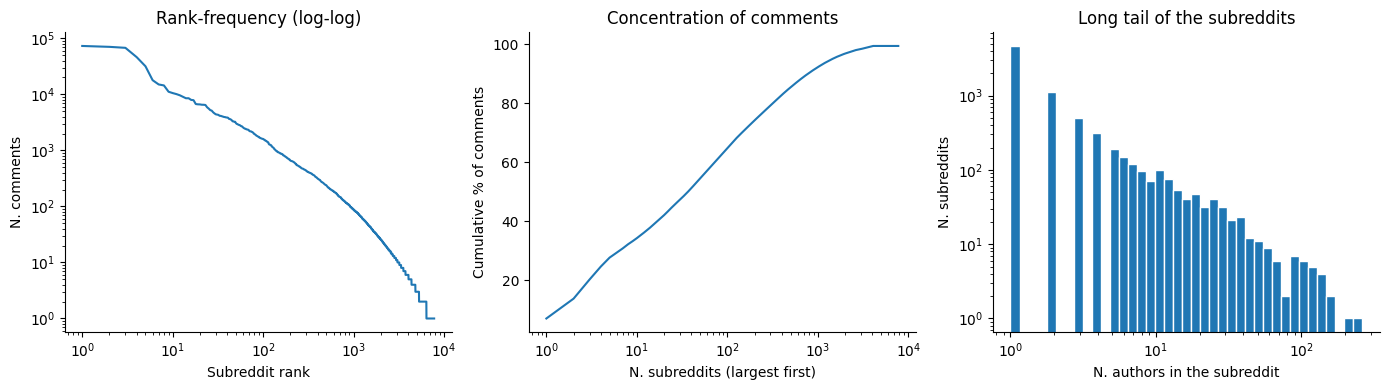

Comments in personality subreddits: 25.5% | authors with at least one: 97.6%


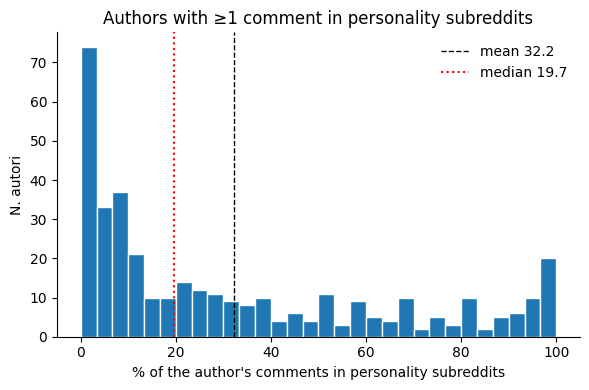

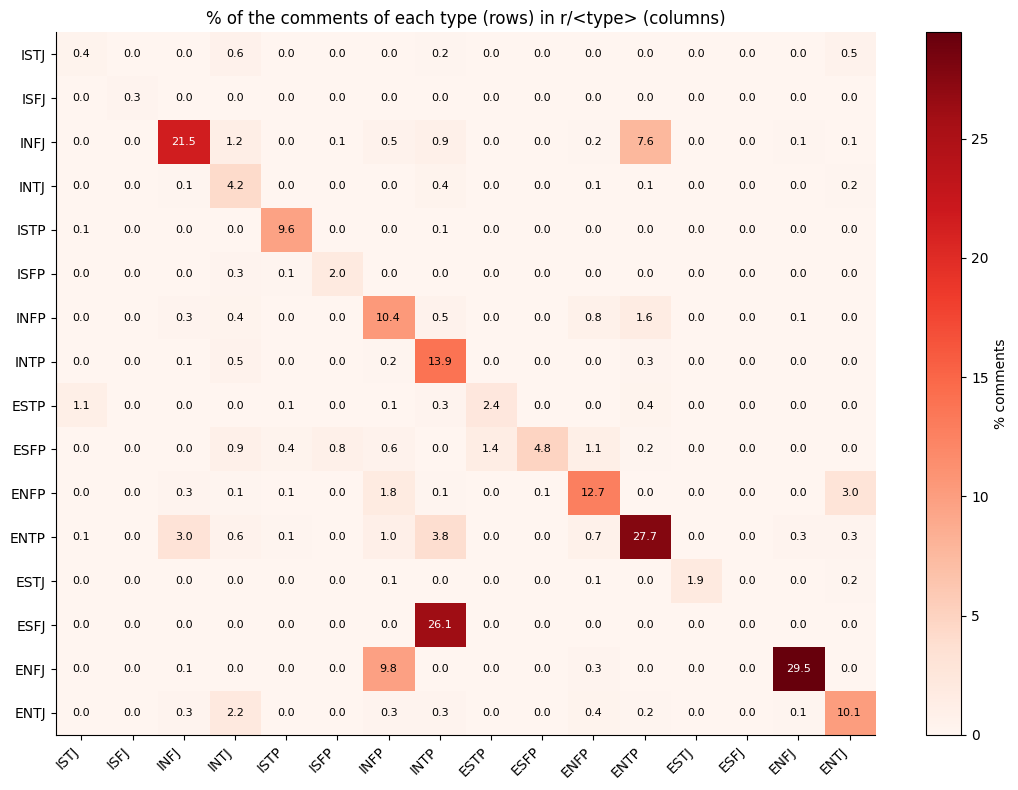

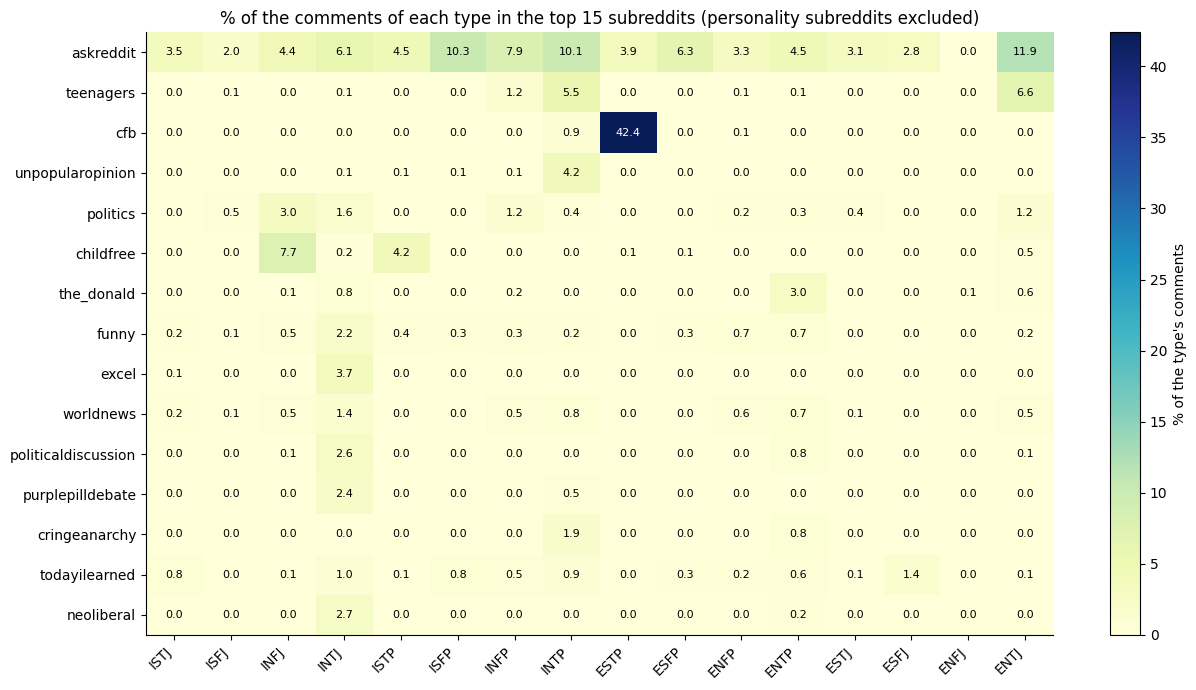

-> completed 'final': 377 authors
dataset                             big_five        mbti_1        mbti_2        final
n_rows_raw                           1191.00  8.690000e+03  7.022000e+03       377.00
n_cols_raw                             35.00  4.000000e+01  4.000000e+01        40.00
n_cols_clean                           29.00  3.600000e+01  3.600000e+01        37.00
n_authors                            1191.00  8.690000e+03  7.022000e+03       377.00
n_mbti_valid                            0.00  8.690000e+03  7.022000e+03       377.00
n_big5_complete                      1191.00  0.000000e+00  0.000000e+00       377.00
pct_female                             25.27  3.061000e+01  2.894000e+01        35.54
mean_age                               26.46  2.550000e+01  2.562000e+01        25.57
n_comments_total                  1961192.00  1.000000e+07  4.510601e+06   1045374.00
n_words_total                    72591084.00  3.651305e+08  1.601987e+08  43198569.00
median_comments     

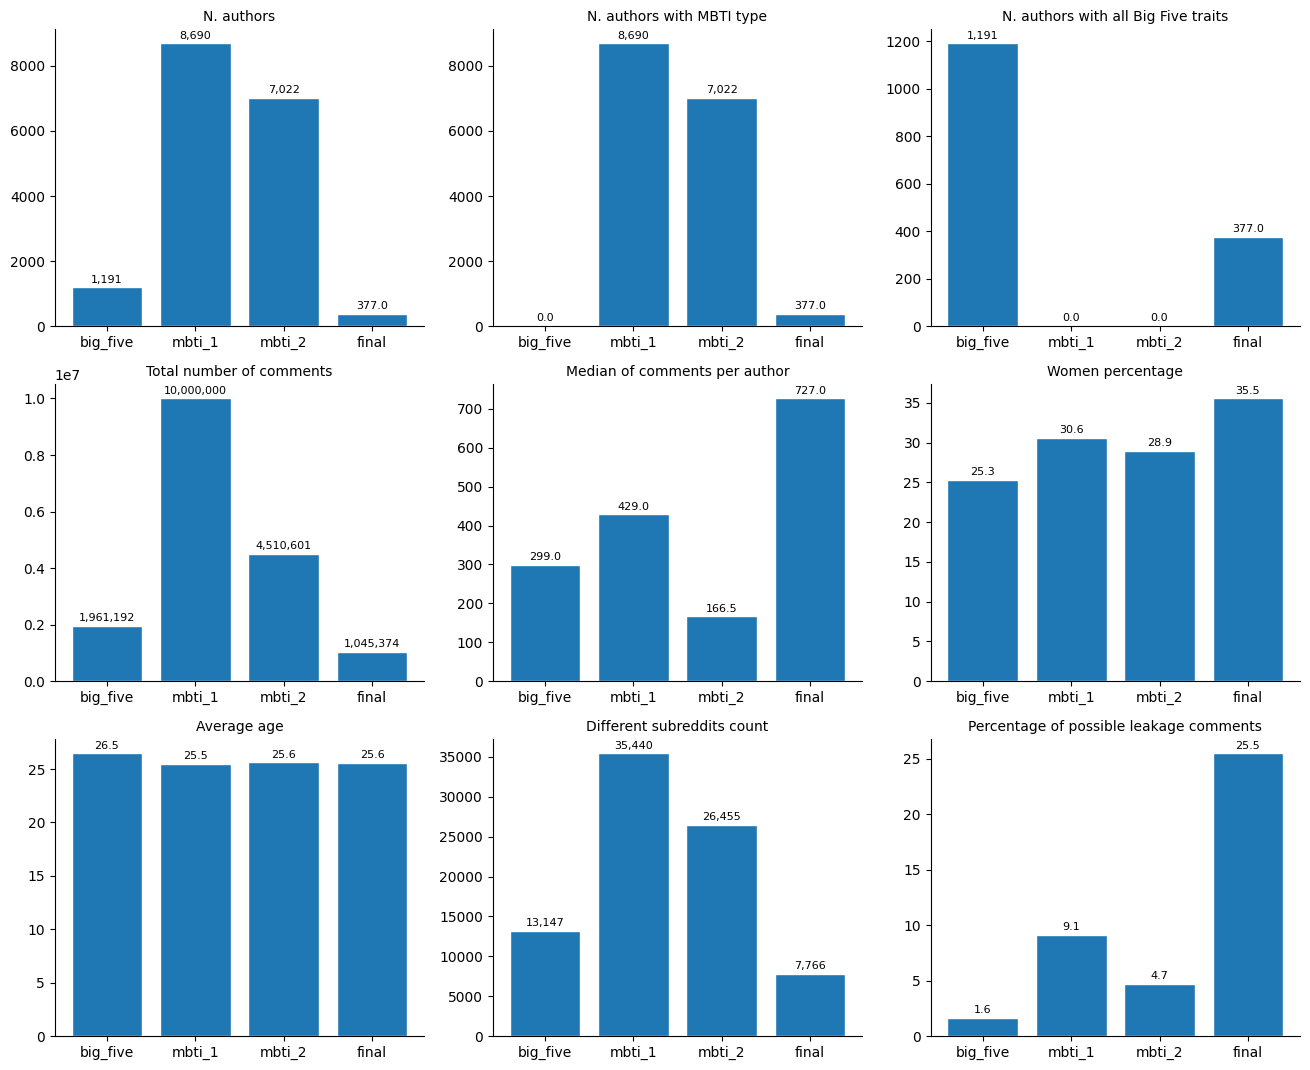


Calculating author overlap...

Authors Overlap:
           big_five  mbti_1  mbti_2  final
big_five      1191       0       0      0
mbti_1           0    8690    7022      0
mbti_2           0    7022    7022      0
final            0       0       0    377


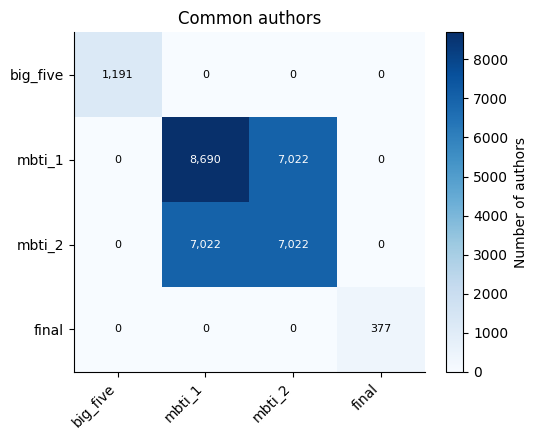


Dataset comparison completed.
Results saved in: /content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Descriptive analysis output/datasets_comparison

Output saved in: /content/drive/MyDrive/Thesis_Elena_Maggiore/Datasets/Descriptive analysis output


In [ ]:
summaries, author_sets = [], {}
for ds_name, ds_path in DATASETS.items():
    if not Path(ds_path).exists():
        print(f"!! File not found: {ds_path}")
        continue
    s, a = run_analysis(ds_name, Path(ds_path))
    summaries.append(s)
    author_sets[ds_name] = a
    gc.collect()

if summaries:
    compare_datasets(summaries, author_sets)
print("\nOutput saved in:", OUT_DIR)
